# Urban Mobility Demand Planning
## Giá, khuyến mãi và thời tiết tại New York

Notebook tự chứa: upload riêng file này lên Google Colab hoặc mở trong Jupyter, rồi chọn **Run all**. Không cần clone repo, upload script hay chạy bước chuẩn bị bên ngoài.

Phạm vi chính là 01/2024 và 01-02/2025. Riêng phần mưa rà thời tiết 2024 và dùng cửa sổ 06-08/2024 được chọn trước khi xem kết quả chuyến. Notebook thực hiện thu thập, audit, tổng hợp, phân tích thời tiết và lập watchlist. Notebook có thêm so sánh chênh lệch tăng trưởng quanh phí vùng trung tâm; phân tích thị phần Lyft, credit và kinh tế hòa vốn theo kịch bản. Dự báo tuần 17-23/02/2025 gồm ba baseline, cutoff 16/02, memo kế hoạch riêng và chấm điểm hồi cứu. Dữ liệu chuyến là chuyến hoàn thành, không gồm booking bị hủy/không có xe.

Lần chạy đầu cần Internet để tải ba tháng chính và ba tháng bổ sung riêng cho mưa; các file lớn tổng cộng vài GB. File được tải theo luồng; DuckDB xử lý file lớn trên ổ đĩa với giới hạn RAM 2 GB, pandas chỉ nhận bảng nhỏ. Cần thêm dung lượng đĩa cho bảng trung gian và vùng spill; không chỉ cho 1,43 GB file gốc. Khi chạy lại, dữ liệu được tái sử dụng sau xác minh hash. Trên Colab, thư mục mặc định nằm trong runtime và có thể mất khi runtime bị xóa; có thể đặt `DATA_DIRECTORY` tới vị trí lưu đã có quyền truy cập.

Notebook cũng tạo bộ bảng báo cáo, hai ảnh preview từ số thật, memo kế hoạch và báo cáo hồi cứu Markdown. Bản nguồn Power BI, PDF và gói bàn giao là sản phẩm trình bày riêng, không phải điều kiện chạy phân tích. Ảnh preview cục bộ không được gọi là ảnh chụp Power BI.

### Chuẩn bị thư viện
Chỉ cài các thư viện dữ liệu cần thiết khi chưa có phiên bản tương thích; không yêu cầu cài JupyterLab trong Colab.

In [1]:
import importlib.metadata
import importlib.util
import subprocess
import sys


requirements = {
    "duckdb": ("duckdb==1.5.6", (1, 1)),
    "pandas": ("pandas>=2.2,<4", (2, 2)),
    "requests": ("requests>=2.31,<3", (2, 31)),
    "holidays": ("holidays==0.106", (0, 60)),
    "matplotlib": ("matplotlib>=3.8,<4", (3, 8)),
}
missing = []
for package, (requirement, minimum) in requirements.items():
    try:
        installed = tuple(int(part) for part in importlib.metadata.version(package).split(".")[:2])
    except importlib.metadata.PackageNotFoundError:
        installed = (0, 0)
    if installed < minimum:
        missing.append(requirement)
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
print("Python dependencies are ready.")

Python dependencies are ready.


### Cấu hình dữ liệu
Giờ chuyến và thời tiết dùng giờ New York. Thời tiết là ERA5 tại Central Park, không phải dự báo biết trước tại ngày cắt.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json
import os
import sys
import time

import duckdb
import holidays
import pandas as pd
import requests


DATA_DIRECTORY = None

base = Path.cwd().resolve()
if base.name == "notebooks":
    base = base.parent
ROOT = Path(DATA_DIRECTORY).expanduser().resolve() if DATA_DIRECTORY else (
    base if (base / "data").is_dir() else base / "urban-mobility-data"
)
for directory in ["data/raw", "data/external", "data/processed", "docs"]:
    (ROOT / directory).mkdir(parents=True, exist_ok=True)
MONTHS = [("2024-01", "2024-01-01", "2024-01-31"),
          ("2025-01", "2025-01-01", "2025-01-31"),
          ("2025-02", "2025-02-01", "2025-02-28")]
MANIFEST = ROOT / "data/external/source_manifest.json"
REQUIRED = {"request_datetime", "pickup_datetime", "dropoff_datetime", "PULocationID", "DOLocationID",
            "hvfhs_license_num", "trip_miles", "base_passenger_fare", "driver_pay"}

### Tải và lưu dấu nguồn
Lưu URL, thời điểm tải, kích thước và SHA-256; file tải dở giữ đuôi `.partial`. Dữ liệu gốc không được sửa.

In [3]:
def digest(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def utcnow():
    return datetime.now(timezone.utc).isoformat()

def record(path, url, manifest, **extra):
    manifest[str(path.relative_to(ROOT))] = {
        "url": url, "downloaded_at_utc": utcnow(), "bytes": path.stat().st_size,
        "sha256": digest(path), **extra,
    }
    MANIFEST.write_text(json.dumps(manifest, indent=2, ensure_ascii=False) + "\n")

def download(url, path, manifest, params=None):
    key = str(path.relative_to(ROOT))
    if path.exists():
        previous = manifest.get(key)
        if previous and digest(path) == previous["sha256"]:
            print(f"Reuse verified: {key}", flush=True)
            return
        raise RuntimeError(f"Unverified or modified input: {path}. Preserve and inspect it before redownloading.")
    partial = path.with_suffix(path.suffix + ".partial")
    for attempt in range(3):
        try:
            with requests.get(url, params=params, stream=True, timeout=(30, 180)) as response:
                response.raise_for_status()
                length = int(response.headers.get("content-length", 0))
                print(f"Downloading {key}: {length / 1e6:.1f} MB", flush=True)
                size, last = 0, time.monotonic()
                with partial.open("wb") as f:
                    for chunk in response.iter_content(4 * 1024 * 1024):
                        f.write(chunk)
                        size += len(chunk)
                        if time.monotonic() - last >= 15:
                            print(f"  {key}: {size / 1e6:.1f} MB received", flush=True)
                            last = time.monotonic()
                if length and size != length:
                    raise ValueError(f"Incomplete response {size}/{length}")
                if not size:
                    raise ValueError("Empty response")
                if path.suffix == ".parquet":
                    with partial.open("rb") as f:
                        if f.read(4) != b"PAR1":
                            raise ValueError("Invalid Parquet header")
                        f.seek(-4, 2)
                        if f.read(4) != b"PAR1":
                            raise ValueError("Invalid Parquet footer")
                partial.replace(path)
                record(path, response.url, manifest)
                print(f"Saved {key}: {size / 1e6:.1f} MB", flush=True)
                return
        except (requests.RequestException, ValueError) as exc:
            if attempt == 2:
                raise
            print(f"Retry {attempt + 1}: {exc}", flush=True)
            time.sleep(2 * (attempt + 1))

### Chuyến, khu vực, thời tiết và ngày lễ
Nguồn: [NYC TLC](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page), [Open-Meteo Historical Weather](https://open-meteo.com/en/docs/historical-weather-api) và thư viện holidays cho lịch Mỹ. Các hàm thu thập nằm ngay trong notebook.

In [4]:
def prepare(manifest):
    for month, start, end in MONTHS:
        download(f"https://d37ci6vzurychx.cloudfront.net/trip-data/fhvhv_tripdata_{month}.parquet",
                 ROOT / f"data/raw/fhvhv_tripdata_{month}.parquet", manifest)
    download("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv",
             ROOT / "data/external/taxi_zone_lookup.csv", manifest)
    frames = []
    for month, start, end in MONTHS:
        path = ROOT / f"data/external/weather_{month}.json"
        download("https://archive-api.open-meteo.com/v1/archive", path, manifest, params={
            "latitude": 40.7812, "longitude": -73.9665, "start_date": start,
            "end_date": end, "hourly": "temperature_2m,rain,snowfall",
            "timezone": "America/New_York", "models": "era5", "temperature_unit": "celsius",
            "precipitation_unit": "mm",
        })
        payload = json.loads(path.read_text())
        if payload.get("timezone") != "America/New_York":
            raise ValueError("Unexpected weather timezone")
        frame = pd.DataFrame(payload["hourly"])
        frame = frame.rename(columns={"time": "request_hour", "temperature_2m": "temperature_c",
                                      "rain": "rain_mm", "snowfall": "snowfall_cm"})
        frames.append(frame)
    pd.concat(frames, ignore_index=True).to_csv(ROOT / "data/external/weather_hourly.csv", index=False)
    calendar = holidays.US(years=[2024, 2025], observed=True)
    pd.DataFrame(sorted(calendar.items()), columns=["date", "holiday_name"]).to_csv(
        ROOT / "data/external/holidays.csv", index=False)
    manifest["derived_sources"] = {
        "weather_hourly.csv": {"inputs": [f"weather_{m}.json" for m, _, _ in MONTHS],
                               "model": "ERA5", "timezone": "America/New_York",
                               "note": "Historical reanalysis; not a forecast known at 16 Feb 2025"},
        "holidays.csv": {"country": "US", "years": [2024, 2025], "observed": True,
                         "holidays_version": importlib.metadata.version("holidays")},
    }
    MANIFEST.write_text(json.dumps(manifest, indent=2, ensure_ascii=False) + "\n")

In [5]:
manifest = json.loads(MANIFEST.read_text()) if MANIFEST.exists() else {}
prepare(manifest)

Reuse verified: data/raw/fhvhv_tripdata_2024-01.parquet


Reuse verified: data/raw/fhvhv_tripdata_2025-01.parquet


Reuse verified: data/raw/fhvhv_tripdata_2025-02.parquet


Reuse verified: data/external/taxi_zone_lookup.csv


Reuse verified: data/external/weather_2024-01.json


Reuse verified: data/external/weather_2025-01.json


Reuse verified: data/external/weather_2025-02.json


### Kiểm tra tính nhất quán của đầu vào
Kiểm tra schema, dữ liệu thời tiết, khóa khu vực và mốc phí trước khi phân tích. Chuyến qua nửa đêm có thể đặt/đón ngày 04/01 nhưng kết thúc ngày 05/01; không coi đó là lỗi chỉ vì ngày đặt. Chi tiết kiểm tra được lưu trong file JSON; bảng dưới đây trình bày dữ liệu và phát hiện, không trình bày checklist kế hoạch.

In [6]:
def validate():
    checks, inventory, schemas, fee_frames, timing = [], [], {}, [], []

    def check(name, condition, details):
        checks.append({"check": name, "valid": bool(condition), "details": details})

    versions = {}
    for pkg in ["duckdb", "pandas", "requests", "holidays"]:
        __import__(pkg)
        versions[pkg] = importlib.metadata.version(pkg)
    check("libraries_import", True, versions)
    con = duckdb.connect()
    con.execute("SET threads=4")
    con.execute("SET memory_limit='2GB'")
    for month, start, end in MONTHS:
        path = ROOT / f"data/raw/fhvhv_tripdata_{month}.parquet"
        schema = con.execute("DESCRIBE SELECT * FROM read_parquet(?)", [str(path)]).df()
        names = set(schema["column_name"])
        schemas[month] = schema[["column_name", "column_type"]].to_dict("records")
        n = con.execute("SELECT count(*) FROM read_parquet(?)", [str(path)]).fetchone()[0]
        check(f"schema_{month}", REQUIRED <= names, {"missing": sorted(REQUIRED - names)})
        check(f"rows_{month}", n > 0, {"rows": n})
        if month.startswith("2025"):
            check(f"fee_column_{month}", "cbd_congestion_fee" in names, {})
        fee = "cbd_congestion_fee" if "cbd_congestion_fee" in names else "CAST(NULL AS DOUBLE)"
        frame = con.execute(f"""
          SELECT CAST(request_datetime AS DATE) AS request_date, count(*) AS trips,
                 SUM(CASE WHEN {fee} > 0 THEN 1 ELSE 0 END) AS fee_positive_trips,
                 SUM(CASE WHEN {fee} < 0 THEN 1 ELSE 0 END) AS fee_negative_trips,
                 SUM(CASE WHEN {fee} IS NULL THEN 1 ELSE 0 END) AS fee_null_trips,
                 min({fee}) AS min_fee, max({fee}) AS max_fee
          FROM read_parquet(?) GROUP BY request_date ORDER BY request_date
        """, [str(path)]).df()
        fee_counts = ["fee_positive_trips", "fee_negative_trips", "fee_null_trips"]
        frame[fee_counts] = frame[fee_counts].astype("int64")
        frame.insert(0, "source_month", month)
        fee_frames.append(frame)
        if "cbd_congestion_fee" in names:
            timing_row = con.execute("""
                SELECT SUM(CASE WHEN cbd_congestion_fee>0 AND request_datetime<TIMESTAMP '2025-01-05' THEN 1 ELSE 0 END) AS request_before_start,
                       SUM(CASE WHEN cbd_congestion_fee>0 AND pickup_datetime<TIMESTAMP '2025-01-05' THEN 1 ELSE 0 END) AS pickup_before_start,
                       SUM(CASE WHEN cbd_congestion_fee>0 AND dropoff_datetime<TIMESTAMP '2025-01-05' THEN 1 ELSE 0 END) AS ended_before_start,
                       SUM(CASE WHEN cbd_congestion_fee>0 AND dropoff_datetime IS NULL THEN 1 ELSE 0 END) AS positive_fee_missing_dropoff
                FROM read_parquet(?)
            """, [str(path)]).df()
            timing_row = timing_row.astype("int64")
            timing_row.insert(0, "source_month", month)
            timing.append(timing_row)
        inventory.append({"month": month, "rows": n, "bytes": path.stat().st_size,
                          "columns": len(names), "fee_column_present": "cbd_congestion_fee" in names,
                          "min_request_date": str(frame.request_date.min()),
                          "max_request_date": str(frame.request_date.max())})
        print(f"Validated {month}: {n:,} trips", flush=True)
    fees = pd.concat(fee_frames, ignore_index=True)
    timing_df = pd.concat(timing, ignore_index=True)
    timing_df.to_csv(ROOT / "data/processed/congestion_fee_start_date_checks.csv", index=False)
    before = timing_df.ended_before_start.sum()
    after = fees[fees.request_date >= pd.Timestamp("2025-01-05")].fee_positive_trips.sum()
    check("no_positive_fee_on_trips_ended_before_start", before == 0, {"positive_fee_trips": int(before),
          "time_basis": "dropoff_datetime < 2025-01-05 00:00 New York",
          "note": "Trips spanning midnight may have a fee; 2024 has no fee column"})
    check("positive_fee_has_dropoff", timing_df.positive_fee_missing_dropoff.sum() == 0, {})
    check("positive_fee_after_start", after > 0, {"positive_fee_trips": int(after)})
    fees.to_csv(ROOT / "data/processed/congestion_fee_by_request_date.csv", index=False)
    pd.DataFrame(inventory).to_csv(ROOT / "data/processed/trip_file_inventory.csv", index=False)
    (ROOT / "docs/trip_data_schema.json").write_text(json.dumps(schemas, indent=2) + "\n")
    zones = pd.read_csv(ROOT / "data/external/taxi_zone_lookup.csv")
    check("zone_unique_key", zones.LocationID.notna().all() and zones.LocationID.is_unique,
          {"rows": len(zones)})
    weather = pd.read_csv(ROOT / "data/external/weather_hourly.csv", parse_dates=["request_hour"])
    expected = pd.DatetimeIndex([])
    for _, start, end in MONTHS:
        expected = expected.append(pd.date_range(start, end + " 23:00:00", freq="h"))
    check("weather_exact_hour_grid", len(weather) == 2160 and weather.request_hour.is_unique
          and set(weather.request_hour) == set(expected), {"rows": len(weather), "expected": 2160})
    check("weather_non_null", weather.notna().all().all(), {"nulls": weather.isna().sum().to_dict()})
    check("weather_nonnegative", (weather[["rain_mm", "snowfall_cm"]] >= 0).all().all(), {})
    calendar = pd.read_csv(ROOT / "data/external/holidays.csv")
    required_dates = {"2024-01-15", "2025-01-20", "2025-02-17"}
    check("key_holidays_present", required_dates <= set(calendar.date),
          calendar[calendar.date.isin(required_dates)].to_dict("records"))
    check("holidays_unique", calendar.date.is_unique, {"rows": len(calendar)})
    valid = all(c["valid"] for c in checks)
    report = {"valid": valid, "checked_at_utc": utcnow(),
              "python": sys.version, "checks": checks, "inventory": inventory}
    (ROOT / "docs/source_data_validation.json").write_text(json.dumps(report, indent=2, ensure_ascii=False) + "\n")
    lines = ["# Dữ liệu nguồn - Báo cáo thực hiện", "",
             f"Thời điểm kiểm tra UTC: {report['checked_at_utc']}", "",
             "## Cách đã thực hiện", "",
             "1. Môi trường Python riêng; các thư viện được import thật.",
             "2. Tải nguyên file Parquet/zone và lưu manifest kèm SHA-256.",
             "3. Lấy thời tiết ERA5 theo giờ Central Park, giờ New York; giữ bản JSON API.",
             "4. Xuất lịch lễ Mỹ; DuckDB đọc schema, đếm chuyến và quét phí theo ngày.", "",
             "## Số dòng thực tế", "", "| Tháng | Chuyến | MB | Có cột phí |",
             "|---|---:|---:|---|"]
    for item in inventory:
        lines.append(f"| {item['month']} | {item['rows']:,} | {item['bytes']/1e6:.1f} | {item['fee_column_present']} |")
    lines += ["", f"Tổng chuyến raw: {sum(i['rows'] for i in inventory):,}.",
              f"Thời tiết: {len(weather):,} giờ; zone: {len(zones)} dòng; lịch lễ: {len(calendar)} ngày.",
              "", "## Kết quả kiểm tra", ""]
    for item in checks:
        lines.append(f"- {'Hợp lệ' if item['valid'] else 'Cần kiểm tra'} - {item['check']}: {json.dumps(item['details'], ensure_ascii=False)}")
    lines += ["", "## Giới hạn và bước tiếp", "",
              "Kiểm tra mốc phí dựa trên chuyến đã kết thúc trước 00:00 ngày 05/01. Request/pickup trước mốc không đủ kết luận lỗi nếu chuyến kéo dài qua mốc. Không quan sát được thời điểm đi qua ranh giới thu phí.",
              f"Chuyến có phí nhưng đặt trước mốc: {int(timing_df.request_before_start.sum()):,}; đón trước mốc: {int(timing_df.pickup_before_start.sum()):,}; kết thúc trước mốc: {int(before):,}. Chi tiết: congestion_fee_start_date_checks.csv.",
              "2024 không có cột phí: không sửa raw và không coi NULL là khoản phí đã đo bằng 0.",
              "Số raw gồm mọi hãng/dòng; chưa phải tập sạch Uber/Lyft. Bước làm sạch sẽ audit giờ ngoài tháng, lỗi metric và nhãn vùng.",
              "Thời tiết ERA5 là dữ liệu tái phân tích tại một điểm, không phải đo toàn thành phố hay forecast tại cutoff.",
              "Chưa ước tính tác động phí, credit hoặc dự báo; không dùng số minh họa trong deck.", ""]
    (ROOT / "docs/source_data_report.md").write_text("\n".join(lines))
    con.close()
    if not valid:
        failed = [item["check"] for item in checks if not item["valid"]]
        raise ValueError("Source inconsistencies: " + ", ".join(failed))
    print("Source data prepared. Inventory and diagnostics saved.", flush=True)

In [7]:
validate()

Validated 2024-01: 19,663,930 trips


Validated 2025-01: 20,405,666 trips


Validated 2025-02: 19,339,461 trips


Source data prepared. Inventory and diagnostics saved.


### Quy mô và phạm vi dữ liệu

In [8]:
inventory = pd.read_csv(ROOT / "data/processed/trip_file_inventory.csv")
display(inventory)
print(f"Tổng chuyến raw: {inventory.rows.sum():,}")

,month,rows,bytes,columns,fee_column_present,min_request_date,max_request_date
0,2024-01,19663930,472757547,24,False,2023-12-31 00:00:00,2024-02-01 00:00:00
1,2025-01,20405666,491076642,25,True,2024-12-31 00:00:00,2025-02-01 00:00:00
2,2025-02,19339461,461632254,25,True,2025-01-31 00:00:00,2025-03-01 00:00:00


Tổng chuyến raw: 59,409,057


### Phí vùng trung tâm tại thời điểm bắt đầu
Phí dương trên chuyến kết thúc hoàn toàn trước mốc cần điều tra. Không quan sát được giờ đi qua ranh giới vùng. Năm 2024 chưa có cột phí mới; NULL không phải khoản phí đã đo bằng 0.

In [9]:
fees = pd.read_csv(ROOT / "data/processed/congestion_fee_by_request_date.csv", parse_dates=["request_date"])
display(fees[fees.request_date.between("2025-01-01", "2025-01-07")])
timing = pd.read_csv(ROOT / "data/processed/congestion_fee_start_date_checks.csv")
display(timing)

,source_month,request_date,trips,fee_positive_trips,fee_negative_trips,fee_null_trips,min_fee,max_fee
34,2025-01,2025-01-01,663945,0,0,0,0.0,0.0
35,2025-01,2025-01-02,529160,0,0,0,0.0,0.0
36,2025-01,2025-01-03,613649,0,0,0,0.0,0.0
37,2025-01,2025-01-04,672761,1890,0,0,0.0,1.5
38,2025-01,2025-01-05,584841,194921,0,0,0.0,1.5
39,2025-01,2025-01-06,562584,168611,0,0,0.0,1.5
40,2025-01,2025-01-07,608447,194400,0,0,0.0,1.5


,source_month,request_before_start,pickup_before_start,ended_before_start,positive_fee_missing_dropoff
0,2025-01,1890,1184,0,0
1,2025-02,0,0,0,0


### Thời tiết và ngày lễ
Mưa: mm/h; tuyết: cm/h; nhiệt độ: °C. Không cộng hai lượng mưa/tuyết khác đơn vị. Presidents’ Day có tên Washington’s Birthday trong lịch nguồn; nối theo ngày.

In [10]:
weather = pd.read_csv(ROOT / "data/external/weather_hourly.csv")
calendar = pd.read_csv(ROOT / "data/external/holidays.csv")
print(f"Số giờ thời tiết: {len(weather):,}")
display(weather.head())
display(calendar[calendar.date.isin(["2024-01-15", "2025-01-20", "2025-02-17"])])

Số giờ thời tiết: 2,160


,request_hour,temperature_c,rain_mm,snowfall_cm
0,2024-01-01T00:00,4.8,0.0,0.0
1,2024-01-01T01:00,5.1,0.1,0.0
2,2024-01-01T02:00,4.7,0.1,0.0
3,2024-01-01T03:00,4.8,0.0,0.0
4,2024-01-01T04:00,4.5,0.0,0.0


,date,holiday_name
1,2024-01-15,Martin Luther King Jr. Day
12,2025-01-20,Martin Luther King Jr. Day
13,2025-02-17,Washington's Birthday


## Làm sạch, gắn nhãn và tổng hợp chuyến

Ngày phân tích theo thời điểm đặt xe, giờ New York. Đọc cả ba file để chuyển chuyến qua ranh giới 01-02/2025 về đúng ngày đặt. Không loại một chuyến chỉ vì ngày đặt khác tháng file.

Tập phân tích giữ Uber/Lyft, ngày đặt trong 90 ngày đã chọn và hai endpoint có mã xác định. Zone 264 Unknown bị loại; 265 Outside of NYC được giữ như endpoint ngoài vùng. Chuyến có giá, quãng đường hoặc thời gian chờ lỗi vẫn được đếm khi xác định được ngày/hãng/vùng; chỉ metric liên quan bị loại khỏi mẫu.

Bảng trung gian DuckDB nằm trong `.analysis-cache/`, không nạp 59 triệu chuyến vào pandas. Các file SQL được xuất để đọc lại nhưng notebook không cần chúng làm đầu vào.

### Chuẩn hóa thời gian và hãng
Đầu tiên chỉ tạo ngày đặt, giờ đặt, tên hãng và số phút chờ. Tháng nguồn được nối từ danh sách file đã khai báo, không tách bằng biểu thức chính quy.

In [11]:
import math

TRIP_FIELDS_SQL = """
CREATE OR REPLACE VIEW trip_fields AS
SELECT
    source.source_month,
    r.request_datetime,
    r.pickup_datetime,
    r.PULocationID,
    r.DOLocationID,
    r.trip_miles,
    r.base_passenger_fare,
    r.driver_pay,
    r.cbd_congestion_fee,
    CAST(r.request_datetime AS DATE) AS request_date,
    date_trunc('hour', r.request_datetime) AS request_hour,
    CASE
        WHEN r.hvfhs_license_num = 'HV0003' THEN 'Uber'
        WHEN r.hvfhs_license_num = 'HV0005' THEN 'Lyft'
    END AS operator,
    date_diff('second', r.request_datetime, r.pickup_datetime) / 60.0 AS wait_minutes
FROM raw_trips r
JOIN source_files source ON r.filename = source.filename
"""

### Đánh dấu giá trị hợp lệ và chọn chuyến
`CASE WHEN ... THEN true ELSE false END` tạo các cờ đọc trực tiếp được. Nối bảng ngày và khu vực để xác định phạm vi; câu `WHERE` riêng chọn tập chuyến. Các giá trị thiếu không bị xem là hợp lệ.

In [12]:
AUDITABLE_SQL = """
CREATE OR REPLACE VIEW auditable_trips AS
SELECT
    t.*,
    CASE WHEN dates.request_date IS NOT NULL THEN true ELSE false END AS in_period,
    CASE
        WHEN pu.LocationID IS NOT NULL AND pu.LocationID <> 264
         AND do_zone.LocationID IS NOT NULL AND do_zone.LocationID <> 264
        THEN true ELSE false
    END AS known_endpoints,
    CASE WHEN wait_minutes BETWEEN 0 AND 60 THEN true ELSE false END AS valid_wait,
    CASE WHEN isfinite(base_passenger_fare) AND base_passenger_fare > 0
         THEN true ELSE false END AS valid_fare,
    CASE WHEN isfinite(driver_pay) AND driver_pay >= 0
         THEN true ELSE false END AS valid_driver_pay,
    CASE WHEN isfinite(trip_miles) AND trip_miles > 0
         THEN true ELSE false END AS valid_distance
FROM trip_fields t
LEFT JOIN analysis_dates dates ON t.request_date = dates.request_date
LEFT JOIN zone_lookup pu ON t.PULocationID = pu.LocationID
LEFT JOIN zone_lookup do_zone ON t.DOLocationID = do_zone.LocationID
"""

CLEAN_SQL = """
CREATE OR REPLACE TABLE clean_trips AS
SELECT
    source_month, request_datetime, pickup_datetime, request_date, request_hour,
    operator, PULocationID, DOLocationID, trip_miles, base_passenger_fare,
    driver_pay, cbd_congestion_fee, wait_minutes, valid_wait, valid_fare,
    valid_driver_pay, valid_distance,
    valid_fare AND valid_driver_pay AS valid_economics
FROM auditable_trips
WHERE in_period = true
  AND operator IS NOT NULL
  AND known_endpoints = true
"""

### Đếm phí theo zone rồi tính tỷ lệ
Câu đầu chỉ đếm chuyến theo điểm đón. Câu thứ hai nối kết quả nhỏ với tên zone và tính tỷ lệ; zone không có chuyến giữ tỷ lệ NULL. `SUM(CASE WHEN điều kiện THEN 1 ELSE 0 END)` đếm số dòng thỏa điều kiện.

In [13]:
ZONE_COUNTS_SQL = """
CREATE OR REPLACE VIEW zone_fee_counts AS
SELECT
    PULocationID AS LocationID,
    COUNT(*) AS pickup_trips,
    COUNT(cbd_congestion_fee) AS fee_observed_trips,
    SUM(CASE WHEN cbd_congestion_fee > 0 THEN 1 ELSE 0 END) AS fee_positive_trips
FROM clean_trips
WHERE request_date BETWEEN DATE '2025-01-05' AND DATE '2025-01-31'
GROUP BY PULocationID
"""

ZONE_PROFILE_SQL = """
SELECT
    z.LocationID, z.Borough, z.Zone,
    COALESCE(c.pickup_trips, 0) AS pickup_trips,
    COALESCE(c.fee_observed_trips, 0) AS fee_observed_trips,
    COALESCE(c.fee_positive_trips, 0) AS fee_positive_trips,
    CASE WHEN c.pickup_trips > 0
         THEN 1.0 * c.fee_positive_trips / c.pickup_trips
    END AS fee_rate
FROM zone_lookup z
LEFT JOIN zone_fee_counts c ON z.LocationID = c.LocationID
ORDER BY z.LocationID
"""

### Gắn nhãn vùng và loại chuyến
Nối danh sách zone cho điểm đón và trả, rồi dùng `CASE WHEN` để gắn nhãn. Ngưỡng cước sẽ được tính từ 01/2024 và điền vào truy vấn lúc chạy.

In [14]:
LABEL_SQL = """
CREATE OR REPLACE VIEW labeled_trips AS
SELECT
    t.*,
    CASE WHEN pu.LocationID IS NOT NULL OR do_zone.LocationID IS NOT NULL
         THEN true ELSE false END AS touches_zone,
    CASE WHEN valid_distance = true AND trip_miles < 2
         THEN true ELSE false END AS is_short_trip,
    CASE WHEN valid_fare = true AND base_passenger_fare <= {low_fare_threshold}
         THEN true ELSE false END AS is_low_fare_trip
FROM clean_trips t
LEFT JOIN crz_lookup pu ON t.PULocationID = pu.LocationID
LEFT JOIN crz_lookup do_zone ON t.DOLocationID = do_zone.LocationID
"""

### Các chỉ số tổng hợp
`COUNT(*)` đếm tất cả chuyến; `SUM(CASE ... THEN 1 ELSE 0 END)` đếm nhóm hợp lệ. Khi tính tiền và chờ, `CASE` không có `ELSE` trả NULL cho quan sát không hợp lệ, để SUM/MEDIAN bỏ qua chúng. Hai tổng tiền giữ cùng mẫu; GROUP BY ghi tên cột để dễ đọc.

In [15]:
METRIC_SQL = """
COUNT(*) AS trips,
SUM(CASE WHEN is_short_trip THEN 1 ELSE 0 END) AS short_trips,
SUM(CASE WHEN is_low_fare_trip THEN 1 ELSE 0 END) AS low_fare_trips,
SUM(CASE WHEN valid_wait THEN 1 ELSE 0 END) AS valid_wait_trips,
SUM(CASE WHEN valid_fare THEN 1 ELSE 0 END) AS valid_fare_trips,
SUM(CASE WHEN valid_distance THEN 1 ELSE 0 END) AS valid_distance_trips,
SUM(CASE WHEN valid_driver_pay THEN 1 ELSE 0 END) AS valid_driver_pay_trips,
SUM(CASE WHEN valid_economics THEN 1 ELSE 0 END) AS valid_economics_trips,
SUM(CASE WHEN valid_economics THEN base_passenger_fare END) AS total_base_fare,
SUM(CASE WHEN valid_economics THEN driver_pay END) AS total_driver_pay,
MEDIAN(CASE WHEN valid_wait THEN wait_minutes END) AS median_wait_minutes
"""

### Quy trình xử lý
Audit theo từng tháng file; ghi lý do giữ/gắn cờ/loại. Tỷ lệ fee ≥95% trong 05-31/01/2025 xác định zone; lưu thêm nhãn 90%/99%. Giá thấp lấy ngưỡng phân vị 25% từ cước dương 01/2024 và cố định cho toàn bộ giai đoạn. Chuyến ngắn có 0<dặm<2; chờ hợp lệ từ 0 tới 60 phút.

In [16]:
def write_quality_report(root, audit, exclusions, crz, threshold, daily, hourly, fee_labels):
    lines = ["# Làm sạch và tổng hợp chuyến", "",
             "## Cách thực hiện", "",
             "1. Audit raw bằng SQL, đếm từng quy tắc riêng. Một chuyến có thể vi phạm nhiều quy tắc; không cộng các dòng audit để suy ra tổng bị loại.",
             "2. Chọn ngày request trong 90 ngày nghiên cứu trên cả ba file; không loại chỉ vì request khác tháng nguồn. Chỉ giữ Uber/Lyft và hai endpoint xác định. Zone 265 Outside of NYC được giữ; 264 Unknown bị loại khỏi tập phân tích chung.",
             "3. Giữ chuyến có giá/chờ/quãng đường lỗi để đếm; chỉ bỏ metric tương ứng. Hai tổng cước và tiền tài xế cùng dùng mẫu kinh tế hợp lệ.",
             "4. Suy ra vùng từ tỷ lệ phí dương trên toàn bộ chuyến đón 05-31/01/2025 của tập giữ lại. Ngưỡng chính 95%; lưu nhãn 90% và 99% để kiểm tra độ vững sau này. Không coi NULL phí là số đo 0.",
             "5. Ngưỡng giá thấp lấy một lần từ cước dương hợp lệ 01/2024; phân vị 25% và dùng <= để bao gồm giá trùng ngưỡng. Chuyến ngắn: 0<dặm<2.",
             "6. Gộp ngày × hãng × nhãn vùng và giờ toàn thành phố; lấp lưới theo coverage, nối thời tiết/lễ với kiểm tra cardinality.",
             "7. Đối chiếu từng metric cộng được với tập giữ lại và giữa hai bảng cho từng ngày; kiểm tra riêng một phân khúc 21/01/2025.", "",
             "## Quy mô sau xử lý", "", "| Tháng file | Raw | Ngoài thời kỳ | Hãng khác | Endpoint không rõ | Giữ lại |",
             "|---|---:|---:|---:|---:|---:|"]
    for r in exclusions.itertuples(index=False):
        lines.append(f"| {r.source_month} | {r.raw_trips:,} | {r.excluded_outside_period:,} | {r.excluded_operator:,} | {r.excluded_unknown_endpoints:,} | {r.retained_trips:,} |")
    lines += ["", f"Tổng giữ lại: {int(exclusions.retained_trips.sum()):,} chuyến. Vùng thu phí: {len(crz)} zone. Ngưỡng giá thấp: ${threshold:.2f}.",
              f"Bảng ngày: {len(daily)} dòng. Bảng giờ: {len(hourly)} dòng. Median chờ dùng quan sát hợp lệ, không lấy trung bình median giữa các nhóm.",
              "", "## Quy tắc audit và quyết định", "", "| Quy tắc | Dòng ảnh hưởng trên raw | Quyết định | Lý do |", "|---|---:|---|---|"]
    for rule, group in audit.groupby("rule", sort=False):
        first = group.iloc[0]
        lines.append(f"| {rule} | {int(group.affected_trips.sum()):,} | {first.decision} | {first.reason} |")
    lines += ["", "## Nhãn vùng và phí thực tế", "", "| Hãng | Chạm vùng | Chuyến | Có phí dương | Tỷ lệ |", "|---|---|---:|---:|---:|"]
    for r in fee_labels.itertuples(index=False):
        lines.append(f"| {r.operator} | {r.touches_zone} | {r.trips:,} | {r.fee_positive_trips:,} | {r.fee_positive_share:.2%} |")
    lines += ["", "## Giới hạn", "",
              "- Cước bằng 0 có thể là điều chỉnh/khuyến mãi hoặc vấn đề báo cáo; chưa biết nguyên nhân. Không xóa chuyến, nhưng trung bình giá chỉ phản ánh mẫu cước dương. metric_quality_by_date.csv cho biết mức mất mẫu theo ngày/hãng.",
              "- Nhãn endpoint không nhận biết chuyến xuyên vùng. Nhóm ngoài vùng vẫn có thể chịu phí; bảng diagnostics lượng hóa sai khác này.",
              "- Bỏ endpoint không rõ làm thay đổi phạm vi so với raw. Các tổng và tỷ lệ trong phân tích chỉ đại diện tập đã giữ lại.",
              "- Tháng 01/2024 thiếu các chuyến request cuối tháng nhưng pickup trong tháng 02/2024. Đầu/cuối phạm vi có sai khác biên; không giả lập dữ liệu chưa tải.",
              "- Mỗi giờ có dòng nguồn không chứng minh nhà cung cấp đã báo cáo đầy đủ mọi chuyến. data_available chỉ phản ánh coverage quan sát.",
              "- Không có trip ID tin cậy để suy ra hai dòng giống nhau là một chuyến. Không tự deduplicate bằng giờ/zone/giá vì có thể xóa chuyến thật.",
              "- Chênh lệch cước và driver pay là proxy, không phải lợi nhuận đóng góp hoặc take rate kế toán đã xác minh.", ""]
    fare_quality = daily.groupby(["request_date", "operator"])[["trips", "valid_fare_trips"]].sum().reset_index()
    fare_quality["excluded_fare_trips"] = fare_quality.trips - fare_quality.valid_fare_trips
    worst = fare_quality.sort_values("excluded_fare_trips", ascending=False).iloc[0]
    lines += ["## Quan sát cần điều tra tiếp", "",
              f"Ngày {worst.request_date:%Y-%m-%d}, {worst.operator}: {int(worst.excluded_fare_trips):,}/{int(worst.trips):,} chuyến không thuộc mẫu cước dương hợp lệ ({worst.excluded_fare_trips / worst.trips:.2%}). Đây là hiện tượng dữ liệu cần điều tra, chưa có bằng chứng để gán nguyên nhân cho credit hay chính sách phí.", ""]
    (root / "docs/trip_data_quality.md").write_text("\n".join(lines))

In [17]:
def build_analysis_tables(root):
    root = Path(root).resolve()
    for directory in ["data/processed", "docs", "sql", ".analysis-cache"]:
        (root / directory).mkdir(parents=True, exist_ok=True)
    files = [root / f"data/raw/fhvhv_tripdata_{month}.parquet"
             for month in ["2024-01", "2025-01", "2025-02"]]
    if not all(path.exists() for path in files):
        raise FileNotFoundError("Prepare the three source Parquet files first.")
    zones = pd.read_csv(root / "data/external/taxi_zone_lookup.csv")
    if zones.LocationID.isna().any() or not zones.LocationID.is_unique:
        raise ValueError("Zone lookup must have a unique non-null LocationID.")
    dates = pd.concat([pd.Series(pd.date_range(start, end, freq="D")) for start, end in [
        ("2024-01-01", "2024-01-31"), ("2025-01-01", "2025-02-28")]], ignore_index=True)
    date_frame = pd.DataFrame({"request_date": dates})
    con = duckdb.connect(str(root / ".analysis-cache/trip_processing.duckdb"))
    con.execute("SET threads=4")
    con.execute("SET memory_limit='2GB'")
    spill_dir = str(root / ".analysis-cache/spill").replace("'", "''")
    con.execute(f"SET temp_directory='{spill_dir}'")
    con.read_parquet([str(path) for path in files], union_by_name=True, filename=True).create_view("raw_trips", replace=True)
    con.register("zone_lookup", zones)
    con.register("analysis_dates", date_frame)
    source_files = pd.DataFrame({"filename": [str(path) for path in files],
                                 "source_month": ["2024-01", "2025-01", "2025-02"]})
    con.register("source_files", source_files)
    queries = {"derive_trip_fields.sql": TRIP_FIELDS_SQL, "audit_trip_fields.sql": AUDITABLE_SQL,
               "retain_classifiable_trips.sql": CLEAN_SQL, "count_zone_fees.sql": ZONE_COUNTS_SQL,
               "infer_congestion_zones.sql": ZONE_PROFILE_SQL}
    for name, sql in queries.items():
        (root / "sql" / name).write_text(sql.strip() + ";\n")
    con.execute(TRIP_FIELDS_SQL)
    con.execute(AUDITABLE_SQL)

    audit_rules = [
        ("missing_request_time", "request_datetime IS NULL", "exclude", "Không xác định được ngày phân tích"),
        ("request_outside_source_month", "strftime(request_datetime, '%Y-%m') <> source_month", "flag", "Phân tháng theo request trong toàn bộ phạm vi, không loại chỉ vì khác tháng file"),
        ("request_outside_analysis_period", "NOT in_period", "exclude", "Ngày đặt ngoài 90 ngày đã chọn"),
        ("unsupported_operator", "operator IS NULL", "exclude", "Chỉ phân tích Uber và Lyft"),
        ("unknown_endpoint", "NOT known_endpoints", "exclude", "Không đủ cơ sở gắn nhãn vùng; 264 là Unknown, 265 Outside of NYC được giữ"),
        ("missing_pickup_time", "pickup_datetime IS NULL", "metric_only", "Giữ chuyến; bỏ khỏi mẫu thời gian chờ"),
        ("negative_wait", "wait_minutes < 0", "metric_only", "Giữ chuyến; bỏ khỏi mẫu thời gian chờ"),
        ("wait_over_60_minutes", "wait_minutes > 60", "metric_only", "Giữ chuyến; bỏ khỏi mẫu thời gian chờ"),
        ("invalid_fare", "NOT valid_fare", "metric_only", "Cước phải hữu hạn và >0; không dùng để tính giá, giá thấp hoặc mẫu kinh tế"),
        ("invalid_driver_pay", "NOT valid_driver_pay", "metric_only", "Tiền tài xế phải hữu hạn và >=0; không dùng cho mẫu kinh tế"),
        ("invalid_distance", "NOT valid_distance", "metric_only", "Quãng đường phải hữu hạn và >0; không gắn nhãn chuyến ngắn"),
        ("negative_congestion_fee", "cbd_congestion_fee < 0", "flag", "Giữ chuyến; khoản điều chỉnh không tính là có phí dương"),
        ("missing_congestion_fee", "cbd_congestion_fee IS NULL", "flag", "2024 thiếu cột phí theo schema; không đổi NULL thành 0"),
    ]
    sums = ",\n".join(f"SUM(CASE WHEN {condition} THEN 1 ELSE 0 END) AS {name}" for name, condition, _, _ in audit_rules)
    raw_audit = con.execute(f"SELECT source_month, count(*) raw_trips, {sums} FROM auditable_trips GROUP BY source_month ORDER BY source_month").df()
    records = []
    for _, row in raw_audit.iterrows():
        for name, _, decision, reason in audit_rules:
            records.append({"source_month": row.source_month, "rule": name,
                            "affected_trips": int(row[name]), "raw_trips": int(row.raw_trips),
                            "decision": decision, "reason": reason})
    audit = pd.DataFrame(records)
    audit.to_csv(root / "data/processed/trip_quality_audit.csv", index=False)
    exclusions = con.execute("""
        SELECT source_month, count(*) raw_trips,
            SUM(CASE WHEN NOT in_period THEN 1 ELSE 0 END) excluded_outside_period,
            SUM(CASE WHEN in_period AND operator IS NULL THEN 1 ELSE 0 END) excluded_operator,
            SUM(CASE WHEN in_period AND operator IS NOT NULL AND NOT known_endpoints THEN 1 ELSE 0 END) excluded_unknown_endpoints,
            SUM(CASE WHEN in_period AND operator IS NOT NULL AND known_endpoints THEN 1 ELSE 0 END) retained_trips
        FROM auditable_trips GROUP BY source_month ORDER BY source_month
    """).df()
    exclusions.to_csv(root / "data/processed/trip_exclusion_summary.csv", index=False)
    print("Audit saved. Retaining trips with an in-scope request and known endpoints.", flush=True)
    con.execute(CLEAN_SQL)
    con.execute(ZONE_COUNTS_SQL)
    profile = con.execute(ZONE_PROFILE_SQL).df()
    zone_counts = ["pickup_trips", "fee_observed_trips", "fee_positive_trips"]
    profile[zone_counts] = profile[zone_counts].astype("int64")
    profile.to_csv(root / "data/processed/zone_fee_profile.csv", index=False)
    crz = profile[profile.fee_rate >= .95].copy()
    if crz.empty:
        raise ValueError("No zone meets the congestion-fee threshold; inspect source data.")
    crz.to_csv(root / "data/processed/crz_zones.csv", index=False)
    sensitivity = pd.concat([profile.assign(zone_threshold=threshold, is_zone=profile.fee_rate >= threshold)
                             for threshold in [.90, .95, .99]], ignore_index=True)
    sensitivity.to_csv(root / "data/processed/zone_definition_sensitivity.csv", index=False)
    con.register("crz_lookup", crz)
    threshold_query = """
        SELECT quantile_cont(base_passenger_fare, 0.25)
        FROM clean_trips
        WHERE request_date BETWEEN DATE '2024-01-01' AND DATE '2024-01-31'
          AND valid_fare = true
    """
    threshold = float(con.execute(threshold_query).fetchone()[0])
    label_sql = LABEL_SQL.format(low_fare_threshold=repr(threshold))
    (root / "sql/label_analysis_segments.sql").write_text(label_sql.strip() + ";\n")
    con.execute(label_sql)
    print(f"Zone labels: {len(crz)} zones. Fixed low-fare threshold: ${threshold:.2f}.", flush=True)

    daily_sql = f"""
        SELECT request_date, operator, touches_zone, {METRIC_SQL}
        FROM labeled_trips
        GROUP BY request_date, operator, touches_zone
    """
    hourly_sql = f"""
        SELECT request_hour, {METRIC_SQL}
        FROM labeled_trips
        GROUP BY request_hour
    """
    (root / "sql/aggregate_daily_segments.sql").write_text(daily_sql + ";\n")
    (root / "sql/aggregate_hourly_city.sql").write_text(hourly_sql + ";\n")
    daily_raw = con.execute(daily_sql).df()
    hourly_raw = con.execute(hourly_sql).df()
    
    coverage = con.execute("SELECT request_hour,count(*) source_trips FROM auditable_trips WHERE in_period AND operator IS NOT NULL GROUP BY request_hour").df()
    hour_grid = pd.DataFrame({"request_hour": pd.DatetimeIndex([day + pd.Timedelta(hours=hour) for day in dates for hour in range(24)])})
    hourly = hour_grid.merge(hourly_raw, on="request_hour", how="left", validate="one_to_one")
    hourly = hourly.merge(coverage, on="request_hour", how="left", validate="one_to_one")
    hourly["data_available"] = hourly.source_trips.notna()
    daily_grid = pd.MultiIndex.from_product([pd.DatetimeIndex(dates), ["Uber", "Lyft"], [False, True]],
                                           names=["request_date", "operator", "touches_zone"]).to_frame(index=False)
    daily = daily_grid.merge(daily_raw, on=["request_date", "operator", "touches_zone"], how="left", validate="one_to_one")
    date_coverage = hourly.assign(request_date=hourly.request_hour.dt.normalize()).groupby("request_date").data_available.all()
    daily["data_available"] = daily.request_date.map(date_coverage)
    count_columns = ["trips", "short_trips", "low_fare_trips", "valid_wait_trips", "valid_fare_trips",
                     "valid_distance_trips", "valid_driver_pay_trips", "valid_economics_trips"]
    empty_counts = []
    for table in [daily, hourly]:
        empty = table.trips.isna() & table.data_available
        empty_counts.append(int(empty.sum()))
        table.loc[empty, count_columns + ["total_base_fare", "total_driver_pay"]] = 0
        for name in count_columns:
            table[name] = table[name].astype("Int64")
        
    weather = pd.read_csv(root / "data/external/weather_hourly.csv", parse_dates=["request_hour"])
    calendar = pd.read_csv(root / "data/external/holidays.csv", parse_dates=["date"]).rename(columns={"date": "request_date"})
    if not calendar.request_date.is_unique:
        raise ValueError("Holiday dates must be unique before merging.")
    hourly = hourly.merge(weather, on="request_hour", how="left", validate="one_to_one")
    hourly["request_date"] = hourly.request_hour.dt.normalize()
    daily = daily.merge(calendar, on="request_date", how="left", validate="many_to_one")
    hourly = hourly.merge(calendar, on="request_date", how="left", validate="many_to_one")
    for table in [daily, hourly]:
        table["is_holiday"] = table.holiday_name.notna()
        table["day_of_week"] = table.request_date.dt.dayofweek
    hourly["hour"] = hourly.request_hour.dt.hour
    daily = daily.sort_values(["request_date", "operator", "touches_zone"]).reset_index(drop=True)
    hourly = hourly.sort_values("request_hour").reset_index(drop=True)
    daily.to_csv(root / "data/processed/daily_segment.csv", index=False)
    hourly.to_csv(root / "data/processed/hourly_city.csv", index=False)
    metric_quality = daily.groupby(["request_date", "operator"])[count_columns].sum().reset_index()
    metric_quality["fare_excluded_trips"] = metric_quality.trips - metric_quality.valid_fare_trips
    metric_quality["wait_excluded_trips"] = metric_quality.trips - metric_quality.valid_wait_trips
    metric_quality["fare_excluded_share"] = metric_quality.fare_excluded_trips / metric_quality.trips
    metric_quality["wait_excluded_share"] = metric_quality.wait_excluded_trips / metric_quality.trips
    metric_quality.to_csv(root / "data/processed/metric_quality_by_date.csv", index=False)
    print("Daily and hourly tables saved. Reconciling counts and monetary sums.", flush=True)

    additive = count_columns + ["total_base_fare", "total_driver_pay"]
    clean_totals = con.execute(f"SELECT {METRIC_SQL} FROM labeled_trips").df().iloc[0]
    recon = []
    for name in additive:
        expected = float(clean_totals[name])
        for table_name, table in [("daily_segment", daily), ("hourly_city", hourly)]:
            observed = float(table[name].sum())
            recon.append({"table": table_name, "metric": name, "clean_total": expected,
                          "aggregate_total": observed, "difference": observed - expected,
                          "matches": math.isclose(expected, observed, rel_tol=1e-12, abs_tol=.01 if name.startswith('total_') else 0)})
    recon = pd.DataFrame(recon)
    recon.to_csv(root / "data/processed/aggregation_reconciliation.csv", index=False)
    expected_daily_totals = hourly.groupby("request_date")[additive].sum()
    actual_daily_totals = daily.groupby("request_date")[additive].sum()
    pd.testing.assert_frame_equal(expected_daily_totals[count_columns], actual_daily_totals[count_columns], check_dtype=False)
    for name in ["total_base_fare", "total_driver_pay"]:
        if any(not math.isclose(float(a), float(b), rel_tol=1e-12, abs_tol=.01)
               for a, b in zip(expected_daily_totals[name], actual_daily_totals[name])):
            raise ValueError("Daily monetary totals do not reconcile: " + name)
    exclusion_partition = exclusions.raw_trips == exclusions[["excluded_outside_period", "excluded_operator", "excluded_unknown_endpoints", "retained_trips"]].sum(axis=1)
    assert exclusion_partition.all(), "Exclusion reasons must partition the raw universe."
    assert int(clean_totals.trips) == int(exclusions.retained_trips.sum())
    assert len(daily) == 360 and len(hourly) == 2160
    assert daily.data_available.all() and hourly.data_available.all(), "Missing source coverage must not be filled with zero."
    assert recon.matches.all(), "Aggregate totals differ from retained trips."
    assert hourly[["temperature_c", "rain_mm", "snowfall_cm"]].notna().all().all()
    assert not daily.duplicated(["request_date", "operator", "touches_zone"]).any()
    assert not hourly.request_hour.duplicated().any()
    for table in [daily, hourly]:
        assert (table[count_columns[1:]].le(table.trips, axis=0)).all().all()
        assert table.loc[table.valid_wait_trips > 0, "median_wait_minutes"].between(0, 60).all()
    fee_labels = con.execute("""
        SELECT operator,touches_zone,count(*) trips,count(cbd_congestion_fee) fee_observed_trips,
            SUM(CASE WHEN cbd_congestion_fee>0 THEN 1 ELSE 0 END) fee_positive_trips,
            avg(CASE WHEN cbd_congestion_fee>0 THEN 1.0 ELSE 0 END) fee_positive_share
        FROM labeled_trips WHERE request_date BETWEEN DATE '2025-01-05' AND DATE '2025-01-31'
        GROUP BY operator, touches_zone ORDER BY operator, touches_zone
    """).df()
    fee_labels.to_csv(root / "data/processed/fee_label_diagnostics.csv", index=False)
    spot_daily = con.execute(f"SELECT request_date,operator,touches_zone,{METRIC_SQL} FROM labeled_trips WHERE request_date=DATE '2025-01-21' AND operator='Lyft' AND touches_zone GROUP BY request_date, operator, touches_zone").df()
    match = daily[(daily.request_date == pd.Timestamp('2025-01-21')) & (daily.operator == 'Lyft') & daily.touches_zone]
    for name in additive + ["median_wait_minutes"]:
        assert math.isclose(float(spot_daily.iloc[0][name]), float(match.iloc[0][name]), rel_tol=1e-12, abs_tol=.01)
    spot_daily.to_csv(root / "data/processed/daily_segment_spot_check.csv", index=False)
    parameters = {"created_at_utc": datetime.now(timezone.utc).isoformat(),
                  "date_basis": "request_datetime, New York local time",
                  "zone_threshold": .95, "zone_count": len(crz),
                  "zone_inference_dates": ["2025-01-05", "2025-01-31"],
                  "low_fare_threshold_usd": threshold,
                  "low_fare_reference": "All retained Jan 2024 trips with finite positive base fare; pooled across operators/zones",
                  "low_fare_definition": "base_passenger_fare <= reference 25th percentile; ties included",
                  "short_trip_definition": "0 < trip_miles < 2",
                  "valid_wait_definition": "0 <= pickup_datetime - request_datetime <= 60 minutes",
                  "monetary_sample": "Both total_base_fare and total_driver_pay use the same valid_economics sample",
                  "outside_nyc_zone": "265 retained as a known outside-zone endpoint; 264 Unknown excluded",
                  "retained_trips": int(clean_totals.trips), "daily_rows": len(daily), "hourly_rows": len(hourly),
                  "empty_daily_segments_filled": empty_counts[0], "empty_hours_filled": empty_counts[1],
                  "source_coverage": "Every expected hour contains in-scope Uber/Lyft requests; this does not prove provider-level completeness",
                  "boundary_limit": "January 2024 cannot include requests picked up in February 2024 because that source month is outside scope; Jan/Feb 2025 requests are reassigned across the available adjacent files"}
    (root / "docs/trip_processing_parameters.json").write_text(json.dumps(parameters, indent=2, ensure_ascii=False) + "\n")
    write_quality_report(root, audit, exclusions, crz, threshold, daily, hourly, fee_labels)
    con.close()
    print(f"Retained {int(clean_totals.trips):,} trips; {len(daily)} daily segments and {len(hourly)} hourly records.", flush=True)
    return daily, hourly

In [18]:
daily_segment, hourly_city = build_analysis_tables(ROOT)

Audit saved. Retaining trips with an in-scope request and known endpoints.


Zone labels: 38 zones. Fixed low-fare threshold: $11.63.


Daily and hourly tables saved. Reconciling counts and monetary sums.


Retained 59,407,013 trips; 360 daily segments and 2160 hourly records.


### Quy mô tập phân tích và lỗi dữ liệu
Các lý do loại trong bảng dưới được áp dụng theo thứ tự, không chồng lấn. Ngược lại, một dòng có thể vi phạm nhiều quy tắc trong bảng audit nên không cộng tổng lỗi để suy ra số chuyến bị loại.

In [19]:
exclusions = pd.read_csv(ROOT / "data/processed/trip_exclusion_summary.csv")
display(exclusions)
audit = pd.read_csv(ROOT / "data/processed/trip_quality_audit.csv")
display(audit.groupby(["rule", "decision", "reason"], sort=False).affected_trips.sum().reset_index())
metric_quality = pd.read_csv(ROOT / "data/processed/metric_quality_by_date.csv")
display(metric_quality.sort_values("fare_excluded_trips", ascending=False).head(5))

,source_month,raw_trips,excluded_outside_period,excluded_operator,excluded_unknown_endpoints,retained_trips
0,2024-01,19663930,861.0,0.0,0.0,19663069.0
1,2025-01,20405666,1164.0,0.0,0.0,20404502.0
2,2025-02,19339461,13.0,0.0,6.0,19339442.0


,rule,decision,reason,affected_trips
0,missing_request_time,exclude,Không xác định được ngày phân tích,0
1,request_outside_source_month,flag,"Phân tháng theo request trong toàn bộ phạm vi,...",5362
2,request_outside_analysis_period,exclude,Ngày đặt ngoài 90 ngày đã chọn,2038
3,unsupported_operator,exclude,Chỉ phân tích Uber và Lyft,0
4,unknown_endpoint,exclude,"Không đủ cơ sở gắn nhãn vùng; 264 là Unknown, ...",6
5,missing_pickup_time,metric_only,Giữ chuyến; bỏ khỏi mẫu thời gian chờ,0
6,negative_wait,metric_only,Giữ chuyến; bỏ khỏi mẫu thời gian chờ,581794
7,wait_over_60_minutes,metric_only,Giữ chuyến; bỏ khỏi mẫu thời gian chờ,1677
8,invalid_fare,metric_only,Cước phải hữu hạn và >0; không dùng để tính gi...,26246
9,invalid_driver_pay,metric_only,Tiền tài xế phải hữu hạn và >=0; không dùng ch...,688


,request_date,operator,trips,short_trips,low_fare_trips,valid_wait_trips,valid_fare_trips,valid_distance_trips,valid_driver_pay_trips,valid_economics_trips,fare_excluded_trips,wait_excluded_trips,fare_excluded_share,wait_excluded_share
102,2025-01-21,Lyft,165825,65953,35684,162430,151898,165818,165825,151898,13927,3395,0.083986,0.020473
26,2024-01-14,Lyft,182793,64962,32235,181396,175801,182775,182793,175801,6992,1397,0.038251,0.007643
95,2025-01-17,Uber,551319,196730,127414,546402,551068,551223,551301,551050,251,4917,0.000455,0.008919
97,2025-01-18,Uber,567881,192508,136404,565287,567694,567802,567876,567689,187,2594,0.000329,0.004568
99,2025-01-19,Uber,493837,171198,124024,491404,493665,493740,493798,493626,172,2433,0.000348,0.004927


### Vùng thu phí và giá thấp
Nhãn chạm vùng dựa vào điểm đón hoặc trả; chưa nhận biết đầy đủ chuyến xuyên vùng. Ngưỡng giá thấp bao gồm giá bằng ngưỡng, nên số chuyến thuộc nhóm này có thể hơi hơn 25% khi nhiều cước trùng nhau.

In [20]:
zone_profile = pd.read_csv(ROOT / "data/processed/zone_fee_profile.csv")
crz_zones = pd.read_csv(ROOT / "data/processed/crz_zones.csv")
parameters = json.loads((ROOT / "docs/trip_processing_parameters.json").read_text())
print("Số khu vực trong nhãn vùng:", len(crz_zones))
print(f"Ngưỡng giá thấp cố định: ${parameters['low_fare_threshold_usd']:.2f}")
display(crz_zones)
display(pd.read_csv(ROOT / "data/processed/fee_label_diagnostics.csv"))

Số khu vực trong nhãn vùng: 38
Ngưỡng giá thấp cố định: $11.63


,LocationID,Borough,Zone,pickup_trips,fee_observed_trips,fee_positive_trips,fee_rate
0,4,Manhattan,Alphabet City,53641,53641,52986,0.987789
1,12,Manhattan,Battery Park,1374,1374,1362,0.991266
2,13,Manhattan,Battery Park City,83591,83591,80063,0.957794
3,45,Manhattan,Chinatown,46014,46014,45694,0.993046
4,48,Manhattan,Clinton East,170402,170402,169486,0.994624
5,50,Manhattan,Clinton West,93752,93752,92374,0.985302
6,68,Manhattan,East Chelsea,192774,192774,191586,0.993837
7,79,Manhattan,East Village,223853,223853,222472,0.993831
8,87,Manhattan,Financial District North,103096,103096,101922,0.988613
9,88,Manhattan,Financial District South,40296,40296,38917,0.965778


,operator,touches_zone,trips,fee_observed_trips,fee_positive_trips,fee_positive_share
0,Lyft,False,2829790,2829790,79793.0,0.028197
1,Lyft,True,1618799,1618799,1582513.0,0.977585
2,Uber,False,9069038,9069038,247585.0,0.027300
3,Uber,True,4410674,4410674,4389910.0,0.995292


### Bảng ngày và bảng giờ
`daily_segment`: một ngày × hãng × nhãn vùng. `hourly_city`: một giờ toàn thành phố trong tập giữ lại, có thời tiết và ngày lễ. Median chờ được tính trực tiếp từ chuyến hợp lệ ở từng grain; không lấy trung bình các median. `data_available` phản ánh coverage nguồn quan sát, không khẳng định mọi chuyến đều đã được nhà cung cấp báo cáo.

In [21]:
print(f"Bảng ngày: {len(daily_segment):,} dòng; bảng giờ: {len(hourly_city):,} dòng.")
display(daily_segment.head(8))
display(hourly_city.head())

Bảng ngày: 360 dòng; bảng giờ: 2,160 dòng.


,request_date,operator,touches_zone,trips,short_trips,low_fare_trips,valid_wait_trips,valid_fare_trips,valid_distance_trips,valid_driver_pay_trips,valid_economics_trips,total_base_fare,total_driver_pay,median_wait_minutes,data_available,holiday_name,is_holiday,day_of_week
0,2024-01-01,Lyft,False,139194,44638,36545,138515,139187,139162,139194,139187,3250924.15,2703546.98,5.633333,True,New Year's Day,True,0
1,2024-01-01,Lyft,True,59382,12767,5983,58926,59381,59371,59382,59381,1821269.57,1509712.99,5.150000,True,New Year's Day,True,0
2,2024-01-01,Uber,False,301020,95316,66485,299974,301013,300947,301014,301007,7901600.36,6110296.14,5.733333,True,New Year's Day,True,0
3,2024-01-01,Uber,True,139345,35060,12291,138210,139344,139295,139341,139340,5195584.83,3778001.04,5.066667,True,New Year's Day,True,0
4,2024-01-02,Lyft,False,101563,38877,34315,99519,101562,101547,101563,101562,2146319.07,1724708.99,4.083333,True,NaN,False,1
5,2024-01-02,Lyft,True,39831,9467,4851,38968,39831,39826,39831,39831,1114723.93,880292.95,3.350000,True,NaN,False,1
6,2024-01-02,Uber,False,233036,87570,73838,231049,233033,232985,233033,233030,5256789.07,4083136.86,3.816667,True,NaN,False,1
7,2024-01-02,Uber,True,103571,31829,13806,102425,103570,103561,103571,103570,3256446.68,2255874.93,3.033333,True,NaN,False,1


,request_hour,trips,short_trips,low_fare_trips,valid_wait_trips,valid_fare_trips,valid_distance_trips,valid_driver_pay_trips,valid_economics_trips,total_base_fare,...,source_trips,data_available,temperature_c,rain_mm,snowfall_cm,request_date,holiday_name,is_holiday,day_of_week,hour
0,2024-01-01 00:00:00,61426,18298,8251,61119,61422,61400,61424,61420,1746556.66,...,61426,True,4.8,0.0,0.0,2024-01-01,New Year's Day,True,0,0
1,2024-01-01 01:00:00,59753,17339,2651,59346,59750,59731,59752,59749,2284622.46,...,59753,True,5.1,0.1,0.0,2024-01-01,New Year's Day,True,0,1
2,2024-01-01 02:00:00,54928,15566,4586,54771,54926,54900,54926,54924,1919215.22,...,54928,True,4.7,0.1,0.0,2024-01-01,New Year's Day,True,0,2
3,2024-01-01 03:00:00,45917,12333,7180,45729,45915,45906,45916,45914,1324783.24,...,45917,True,4.8,0.0,0.0,2024-01-01,New Year's Day,True,0,3
4,2024-01-01 04:00:00,32011,8382,5886,31758,32011,31999,32011,32011,867213.31,...,32011,True,4.5,0.0,0.0,2024-01-01,New Year's Day,True,0,4


### Đối chiếu mẫu và giới hạn
Bảng dưới là một phân khúc ngày 21/01/2025 được tính lại trực tiếp từ tập giữ lại. Tổng chuyến, tổng cước và tiền tài xế đã được đối chiếu với hai bảng tổng hợp cho từng ngày.

- Giá/chờ lỗi không bị đánh tráo thành số 0; dùng các cột số quan sát hợp lệ làm mẫu số.
- Dữ liệu chỉ bao gồm chuyến hoàn thành và endpoint xác định.
- Tháng 01/2024 không có file tháng 02/2024 để bổ sung request cuối tháng được đón sang tháng sau.
- Số chênh lệch giữa cước và tiền tài xế chưa phải lợi nhuận thực tế.
- Phân tích thời tiết ở phần tiếp theo; so sánh quanh phí ở phần sau; credit và dự báo chưa thực hiện.

In [22]:
display(pd.read_csv(ROOT / "data/processed/daily_segment_spot_check.csv"))

,request_date,operator,touches_zone,trips,short_trips,low_fare_trips,valid_wait_trips,valid_fare_trips,valid_distance_trips,valid_driver_pay_trips,valid_economics_trips,total_base_fare,total_driver_pay,median_wait_minutes
0,2025-01-21,Lyft,True,58431,18603.0,7119.0,57287.0,52389.0,58429.0,58431.0,52389.0,1418941.88,1071407.18,3.966667


## Thời tiết và biến động nhu cầu
Phần mưa dùng cửa sổ riêng để tăng số đợt độc lập. Không thay đổi tập phân tích phí/credit/dự báo. Hệ số mưa mùa hè không được áp trực tiếp vào kế hoạch tháng 02.

### Rà thời tiết trước khi chọn dữ liệu chuyến
Phân loại giờ, bỏ ngày lễ và so mọi cửa sổ ba tháng liên tục năm 2024. Chọn cửa sổ có ít nhất 20 giờ mưa >2 mm/h, ưu tiên nhiều đợt ẩm riêng biệt, sau đó số giờ; không nhìn số chuyến để chọn. Một đợt là chuỗi giờ liên tục có mưa hoặc tuyết.

In [23]:
def read_weather_json(path):
    payload = json.loads(Path(path).read_text())
    if payload.get("timezone") != "America/New_York":
        raise ValueError("Weather must use New York local time.")
    frame = pd.DataFrame(payload["hourly"]).rename(columns={
        "time": "request_hour", "temperature_2m": "temperature_c",
        "rain": "rain_mm", "snowfall": "snowfall_cm"})
    frame["request_hour"] = pd.to_datetime(frame.request_hour)
    if not frame.request_hour.is_unique or frame.isna().any().any():
        raise ValueError("Weather hours must be unique and complete.")
    return frame

def classify_weather(frame):
    frame = frame.sort_values("request_hour").copy()
    frame["weather_group"] = "dry"
    frame.loc[frame.rain_mm.gt(0), "weather_group"] = "drizzle"
    frame.loc[frame.rain_mm.between(.5, 2), "weather_group"] = "light_rain"
    frame.loc[frame.rain_mm.gt(2), "weather_group"] = "moderate_or_heavy_rain"
    frame.loc[frame.snowfall_cm.gt(0), "weather_group"] = "snow"
    wet = frame.rain_mm.gt(0) | frame.snowfall_cm.gt(0)
    gap = frame.request_hour.diff().ne(pd.Timedelta(hours=1))
    starts = wet & (gap | ~wet.shift(fill_value=False))
    frame["weather_event_id"] = starts.cumsum().where(wet).astype("Int64")
    frame["request_date"] = frame.request_hour.dt.normalize()
    frame["month"] = frame.request_hour.dt.month
    frame["year"] = frame.request_hour.dt.year
    frame["day_of_week"] = frame.request_hour.dt.dayofweek
    frame["hour"] = frame.request_hour.dt.hour
    return frame

def review_weather_coverage(root, download):
    root = Path(root)
    manifest_path = root / "data/external/source_manifest.json"
    manifest = json.loads(manifest_path.read_text())
    annual = root / "data/external/weather_2024_full_year.json"
    download("https://archive-api.open-meteo.com/v1/archive", annual, manifest, params={
        "latitude": 40.7812, "longitude": -73.9665, "start_date": "2024-01-01",
        "end_date": "2024-12-31", "hourly": "temperature_2m,rain,snowfall",
        "timezone": "America/New_York", "models": "era5",
        "temperature_unit": "celsius", "precipitation_unit": "mm"})
    weather = classify_weather(read_weather_json(annual))
    holidays_frame = pd.read_csv(root / "data/external/holidays.csv", parse_dates=["date"])
    weather["is_holiday"] = weather.request_date.isin(holidays_frame.date)
    if len(weather) != 8784:
        raise ValueError("Expected a full leap year of hourly weather.")
    monthly_rows = []
    for month, group in weather.groupby("month"):
        usable = group[~group.is_holiday]
        heavy = usable[usable.weather_group.eq("moderate_or_heavy_rain")]
        monthly_rows.append({"month": f"2024-{month:02d}", "total_hours": len(group),
                             "dry_hours": int(usable.weather_group.eq("dry").sum()),
                             "light_rain_hours": int(usable.weather_group.eq("light_rain").sum()),
                             "heavy_rain_hours": len(heavy),
                             "heavy_rain_events": int(heavy.weather_event_id.nunique()),
                             "heavy_rain_days": int(heavy.request_date.nunique()),
                             "snow_hours": int(usable.weather_group.eq("snow").sum())})
    monthly = pd.DataFrame(monthly_rows)
    windows = []
    for start_month in range(1, 11):
        usable = weather[weather.month.between(start_month, start_month + 2) & ~weather.is_holiday]
        heavy = usable[usable.weather_group.eq("moderate_or_heavy_rain")]
        windows.append({"start_month": start_month, "end_month": start_month + 2,
                        "start": f"2024-{start_month:02d}-01",
                        "end": str(pd.Period(f"2024-{start_month + 2:02d}", freq="M").end_time.date()),
                        "heavy_rain_hours": len(heavy),
                        "heavy_rain_events": int(heavy.weather_event_id.nunique()),
                        "heavy_rain_days": int(heavy.request_date.nunique()),
                        "enough_hours": len(heavy) >= 20})
    windows = pd.DataFrame(windows)
    candidates = windows[windows.enough_hours].sort_values(
        ["heavy_rain_events", "heavy_rain_hours", "start_month"], ascending=[False, False, True])
    if candidates.empty:
        raise ValueError("No three-month window meets the weather coverage rule.")
    selected = candidates.iloc[0]
    selection = {"selected_before_trip_analysis": True, "start": selected.start, "end": selected.end,
                 "months": [f"2024-{m:02d}" for m in range(int(selected.start_month), int(selected.end_month) + 1)],
                 "heavy_rain_hours": int(selected.heavy_rain_hours),
                 "heavy_rain_events": int(selected.heavy_rain_events),
                 "selection_rule": "Contiguous three-month windows with >=20 non-holiday heavy-rain hours; maximize distinct wet events, then hours; no trip outcomes used",
                 "event_definition": "Contiguous hours with rain>0 or snowfall>0; heavy hours may belong to the same wet event",
                 "season_limit": "Summer estimates are not directly transferred to February planning"}
    monthly.to_csv(root / "data/processed/weather_coverage_by_month.csv", index=False)
    windows.to_csv(root / "data/processed/weather_window_comparison.csv", index=False)
    (root / "docs/weather_window_selection.json").write_text(json.dumps(selection, indent=2, ensure_ascii=False) + "\n")
    return monthly, windows, selection

### Tổng hợp giờ cho nghiên cứu mưa
SQL chỉ chuẩn hóa thời gian, chọn request đúng phạm vi/hãng/endpoint và gộp theo giờ. Dữ liệu bổ sung lưu riêng trong data/weather_raw. Mưa/tuyết và ngày lễ được nối sau tổng hợp.

In [24]:
WEATHER_FIELDS_SQL = """
CREATE OR REPLACE VIEW weather_trip_fields AS
SELECT
    request_datetime,
    CAST(request_datetime AS DATE) AS request_date,
    date_trunc('hour', request_datetime) AS request_hour,
    hvfhs_license_num,
    PULocationID,
    DOLocationID,
    date_diff('second', request_datetime, pickup_datetime) / 60.0 AS wait_minutes
FROM weather_raw_trips
"""

WEATHER_SAMPLE_SQL = """
CREATE OR REPLACE VIEW weather_sample AS
SELECT *,
    CASE WHEN wait_minutes BETWEEN 0 AND 60 THEN true ELSE false END AS valid_wait
FROM weather_trip_fields
WHERE request_datetime >= TIMESTAMP '{start}'
  AND request_datetime < TIMESTAMP '{end_exclusive}'
  AND hvfhs_license_num IN ('HV0003', 'HV0005')
  AND PULocationID IN (SELECT LocationID FROM known_zones)
  AND DOLocationID IN (SELECT LocationID FROM known_zones)
"""

WEATHER_HOURLY_SQL = """
SELECT request_hour,
    COUNT(*) AS trips,
    SUM(CASE WHEN valid_wait THEN 1 ELSE 0 END) AS valid_wait_trips,
    MEDIAN(CASE WHEN valid_wait THEN wait_minutes END) AS median_wait_minutes
FROM weather_sample
GROUP BY request_hour
ORDER BY request_hour
"""

In [25]:
def build_weather_study(root, download, selection):
    root = Path(root)
    (root / "data/weather_raw").mkdir(exist_ok=True)
    manifest_path = root / "data/external/source_manifest.json"
    manifest = json.loads(manifest_path.read_text())
    files, weather_frames = [], []
    for month in selection["months"]:
        path = root / f"data/weather_raw/fhvhv_tripdata_{month}.parquet"
        download(f"https://d37ci6vzurychx.cloudfront.net/trip-data/fhvhv_tripdata_{month}.parquet", path, manifest)
        weather_path = root / f"data/external/weather_{month}.json"
        end = str(pd.Period(month, freq="M").end_time.date())
        download("https://archive-api.open-meteo.com/v1/archive", weather_path, manifest, params={
            "latitude": 40.7812, "longitude": -73.9665, "start_date": month + "-01", "end_date": end,
            "hourly": "temperature_2m,rain,snowfall", "timezone": "America/New_York",
            "models": "era5", "temperature_unit": "celsius", "precipitation_unit": "mm"})
        files.append(str(path))
        weather_frames.append(read_weather_json(weather_path))
    zones = pd.read_csv(root / "data/external/taxi_zone_lookup.csv")
    known_zones = zones[zones.LocationID.ne(264)][["LocationID"]]
    con = duckdb.connect()
    con.execute("SET threads=4")
    con.execute("SET memory_limit='2GB'")
    spill = str(root / ".analysis-cache/weather_spill").replace("'", "''")
    con.execute(f"SET temp_directory='{spill}'")
    con.read_parquet(files, union_by_name=True).create_view("weather_raw_trips")
    con.register("known_zones", known_zones)
    con.execute(WEATHER_FIELDS_SQL)
    end_exclusive = str((pd.Timestamp(selection["end"]) + pd.Timedelta(days=1)).date())
    sample_sql = WEATHER_SAMPLE_SQL.format(start=selection["start"], end_exclusive=end_exclusive)
    con.execute(sample_sql)
    hourly = con.execute(WEATHER_HOURLY_SQL).df()
    hourly.valid_wait_trips = hourly.valid_wait_trips.astype("int64")
    weather = pd.concat(weather_frames, ignore_index=True)
    hourly = hourly.merge(weather, on="request_hour", how="outer", validate="one_to_one")
    expected_hours = len(pd.date_range(selection["start"], selection["end"] + " 23:00", freq="h"))
    if len(hourly) != expected_hours or hourly[["trips", "rain_mm", "snowfall_cm"]].isna().any().any():
        raise ValueError("Weather-study hourly coverage is incomplete; do not fill missing sources with zero.")
    con.close()
    hourly = classify_weather(hourly)
    calendar = pd.read_csv(root / "data/external/holidays.csv", parse_dates=["date"])
    hourly["is_holiday"] = hourly.request_date.isin(calendar.date)
    hourly.to_csv(root / "data/processed/weather_study_hourly.csv", index=False)
    for name, sql in [("prepare_weather_trip_fields.sql", WEATHER_FIELDS_SQL),
                      ("select_weather_trip_sample.sql", sample_sql), ("aggregate_weather_hours.sql", WEATHER_HOURLY_SQL)]:
        (root / "sql" / name).write_text(sql.strip() + ";\n")
    return hourly

### Hệ số so với giờ khô
Khô: không mưa/tuyết; mưa nhẹ 0,5-2 mm/h; mưa vừa trở lên >2; ưu tiên tuyết khi snowfall>0. Mưa nhỏ 0<rain<0,5 và ngày lễ không tham gia hệ số. Mỗi giờ chia cho median khô cùng tháng/năm/thứ/giờ; median các tỷ số tạo hệ số nhóm. Báo cáo số giờ, ngày, đợt và cỡ mẫu khô; dưới 20 giờ chỉ tham khảo.

In [26]:
def calculate_weather_factors(root, summer):
    root = Path(root)
    winter = pd.read_csv(root / "data/processed/hourly_city.csv", parse_dates=["request_hour"])
    winter = classify_weather(winter)
    frames = []
    summaries = []
    for study, data in [("summer_2024", summer), ("winter_2024", winter[winter.year.eq(2024)]),
                        ("winter_2025", winter[winter.year.eq(2025)])]:
        data = data.copy()
        dry = data[data.weather_group.eq("dry") & ~data.is_holiday]
        keys = ["year", "month", "day_of_week", "hour"]
        baselines = dry.groupby(keys).agg(dry_trips=("trips", "median"), dry_wait=("median_wait_minutes", "median"),
                                         dry_hours=("trips", "count"), dry_wait_hours=("median_wait_minutes", "count")).reset_index()
        data = data.merge(baselines, on=keys, how="left", validate="many_to_one")
        eligible = ~data.is_holiday & ~data.weather_group.eq("drizzle")
        data["trips_factor"] = (data.trips / data.dry_trips).where(eligible & data.dry_trips.gt(0))
        data["wait_factor"] = (data.median_wait_minutes / data.dry_wait).where(eligible & data.dry_wait.gt(0))
        data["study"] = study
        frames.append(data)
        for group, hours in data.groupby("weather_group"):
            used = hours[hours.trips_factor.notna()]
            wait_used = hours[hours.wait_factor.notna()]
            wet_used = used[used.weather_group.ne("dry")]
            summaries.append({"study": study, "weather_group": group, "observed_hours": len(hours),
                              "usable_trip_hours": len(used), "usable_wait_hours": len(wait_used),
                              "usable_days": int(used.request_date.nunique()),
                              "wet_events": int(wet_used.weather_event_id.nunique()),
                              "trips_factor": used.trips_factor.median(), "wait_factor": wait_used.wait_factor.median(),
                              "min_dry_reference_hours": used.dry_hours.min(),
                              "trip_sample_under_20_hours": len(used) < 20,
                              "wait_sample_under_20_hours": len(wait_used) < 20,
                              "excluded_holiday_hours": int(hours.is_holiday.sum())})
    ratios = pd.concat(frames, ignore_index=True)
    factors = pd.DataFrame(summaries)
    ratios.to_csv(root / "data/processed/weather_hourly_factors.csv", index=False)
    factors.to_csv(root / "data/processed/rain_factors.csv", index=False)
    spot_candidates = ratios[ratios.study.eq("summer_2024") & ratios.weather_group.eq("moderate_or_heavy_rain") & ratios.trips_factor.notna()]
    if spot_candidates.empty:
        raise ValueError("No matched heavy-rain hour in the chosen study.")
    spot = spot_candidates.head(1).copy()
    r = spot.iloc[0]
    assert math.isclose(r.trips_factor, r.trips / r.dry_trips, rel_tol=1e-12)
    matched = ratios[ratios.study.eq(r.study) & ratios.year.eq(r.year) & ratios.month.eq(r.month)
                     & ratios.day_of_week.eq(r.day_of_week) & ratios.hour.eq(r.hour)
                     & ratios.weather_group.eq("dry") & ~ratios.is_holiday]
    assert math.isclose(r.dry_trips, matched.trips.median(), rel_tol=1e-12)
    assert not ratios.loc[ratios.is_holiday | ratios.weather_group.eq("drizzle"), "trips_factor"].notna().any()
    assert not ratios.loc[ratios.is_holiday | ratios.weather_group.eq("drizzle"), "wait_factor"].notna().any()
    spot.to_csv(root / "data/processed/weather_factor_spot_check.csv", index=False)
    return factors, ratios

### Watchlist trên phạm vi chính
Kỳ vọng là trung bình cùng thứ của D-7 và D-14. Nếu thiếu bộ hai ngày, dùng D-364 khi có; thiếu tiếp thì để NULL. Cảnh báo lệch chuyến >±7% hoặc chờ >±20%. Chất lượng metric, lễ trong baseline, thời tiết và thay đổi thị trường là bối cảnh điều tra, chưa phải nguyên nhân đã chứng minh.

In [27]:
def build_demand_watchlist(root):
    root = Path(root)
    daily = pd.read_csv(root / "data/processed/daily_segment.csv", parse_dates=["request_date"])
    hourly = pd.read_csv(root / "data/processed/hourly_city.csv", parse_dates=["request_date"])
    hourly["rain_hour"] = hourly.rain_mm.gt(0) & hourly.snowfall_cm.eq(0)
    hourly["snow_hour"] = hourly.snowfall_cm.gt(0)
    weather = hourly.groupby("request_date").agg(rain_hours=("rain_hour", "sum"), snow_hours=("snow_hour", "sum"),
                                                  rain_mm_total=("rain_mm", "sum"), min_temperature_c=("temperature_c", "min"))
    lookup = daily.set_index(["request_date", "operator", "touches_zone"])
    rows = []
    for r in daily.itertuples(index=False):
        previous_keys = [(r.request_date - pd.Timedelta(days=n), r.operator, r.touches_zone) for n in [7, 14]]
        if all(key in lookup.index for key in previous_keys):
            references = [lookup.loc[key] for key in previous_keys]
            reference_dates = [key[0] for key in previous_keys]
            baseline_method = "previous_two_same_weekdays"
        else:
            key = (r.request_date - pd.Timedelta(days=364), r.operator, r.touches_zone)
            references = [lookup.loc[key]] if key in lookup.index else []
            reference_dates = [key[0]] if references else []
            baseline_method = "same_weekday_previous_year" if references else "unavailable"
        expected_trips = sum(x.trips for x in references) / len(references) if references else float("nan")
        waits = [x.median_wait_minutes for x in references if pd.notna(x.median_wait_minutes)]
        expected_wait = sum(waits) / len(waits) if len(waits) == len(references) and waits else float("nan")
        trips_delta = r.trips / expected_trips - 1 if expected_trips > 0 else float("nan")
        wait_delta = r.median_wait_minutes / expected_wait - 1 if expected_wait > 0 else float("nan")
        w = weather.loc[r.request_date]
        fare_missing = (r.trips - r.valid_fare_trips) / r.trips
        wait_missing = (r.trips - r.valid_wait_trips) / r.trips
        reference_holiday = any(x.is_holiday for x in references)
        triggers = []
        if abs(trips_delta) > .07:
            triggers.append("trips")
        if abs(wait_delta) > .20:
            triggers.append("wait")
        if fare_missing > .05 or wait_missing > .05:
            hypothesis = "metric_sample_quality"
            next_step = "Rà nguồn cước/chờ; giữ volume, không dùng giá thiếu mẫu để gán nguyên nhân."
        elif reference_holiday:
            hypothesis = "holiday_in_baseline"
            next_step = "So lại với ngày thường cùng thứ; baseline có lễ nên không coi chênh lệch là tác động mới."
        elif r.is_holiday:
            hypothesis = "holiday_context"
            next_step = "So cả bốn phân khúc và ngày lễ năm trước; kiểm tra thời tiết trước khi gán nguyên nhân."
        elif w.rain_hours > 0 or w.snow_hours > 0:
            hypothesis = "weather_context"
            next_step = "So giờ khô cùng tháng/thứ/giờ và thời tiết các ngày baseline; chưa suy ra thiếu tài xế."
        else:
            hypothesis = "unexplained_or_market_change"
            next_step = "Rà xu hướng hai hãng/nhãn vùng, giá và dữ liệu nguồn; chưa gán tác động cho phí hoặc credit."
        evidence = (f"Chuyến {trips_delta:+.1%}; chờ {wait_delta:+.1%}; cước không thuộc mẫu {fare_missing:.1%}; "
                    f"mưa {int(w.rain_hours)} giờ, tuyết {int(w.snow_hours)} giờ; "
                    f"lễ hiện tại={r.is_holiday}, lễ trong baseline={reference_holiday}.")
        rows.append({"request_date": r.request_date, "operator": r.operator, "touches_zone": r.touches_zone,
                     "trips": r.trips, "median_wait_minutes": r.median_wait_minutes,
                     "expected_trips": expected_trips, "expected_wait_minutes": expected_wait,
                     "trips_deviation": trips_delta, "wait_deviation": wait_delta, "baseline_method": baseline_method,
                     "baseline_dates": ",".join(str(d.date()) for d in reference_dates),
                     "baseline_contains_holiday": reference_holiday, "is_holiday": r.is_holiday,
                     "rain_hours": int(w.rain_hours), "snow_hours": int(w.snow_hours),
                     "fare_excluded_share": fare_missing, "wait_excluded_share": wait_missing,
                     "alert": bool(triggers), "trigger": ",".join(triggers), "possible_cause": hypothesis,
                     "evidence": evidence, "next_step": next_step, "investigation_status": "needs_follow_up"})
    monitoring = pd.DataFrame(rows)
    alert_mask = monitoring.alert
    cases = []
    for date, operator, touches, finding in [
        ("2025-01-20", "Lyft", False, "Có ngày lễ MLK nhưng biến động không đồng đều giữa hãng/nhãn vùng. Ngày lễ là bối cảnh, chưa đủ giải thích riêng sự giảm của Lyft ngoài vùng."),
        ("2025-01-21", "Lyft", True, "Chuyến tăng đồng thời nhiều cước không thuộc mẫu dương. Đã đối chiếu với raw; giữ volume, không dùng trung bình giá bị mất mẫu để suy ra hiệu quả credit.")]:
        mask = monitoring.request_date.eq(pd.Timestamp(date)) & monitoring.operator.eq(operator) & monitoring.touches_zone.eq(touches) & alert_mask
        if mask.any():
            case = monitoring.loc[mask].iloc[0].to_dict()
            case["finding"] = finding
            case["investigation_status"] = "reviewed_with_limitations"
            cases.append(case)
            monitoring.loc[mask, "investigation_status"] = "reviewed_with_limitations"
    if len(cases) < 2:
        raise ValueError("Expected cases did not trigger; review actual alerts instead of manufacturing evidence.")
    monitoring.to_csv(root / "data/processed/demand_monitoring.csv", index=False)
    watchlist = monitoring[monitoring.alert].copy()
    watchlist.to_csv(root / "data/processed/watchlist.csv", index=False)
    investigations = pd.DataFrame(cases)
    investigations.to_csv(root / "data/processed/alert_investigations.csv", index=False)
    comparisons = monitoring[monitoring.request_date.isin(investigations.request_date)].copy()
    comparisons.to_csv(root / "data/processed/alert_case_comparison.csv", index=False)
    assert monitoring.loc[monitoring.baseline_method.eq("unavailable"), "alert"].eq(False).all()
    for r in monitoring.itertuples(index=False):
        for date in r.baseline_dates.split(","):
            if date:
                assert pd.Timestamp(date) < r.request_date
    return monitoring, watchlist, investigations

### Biểu đồ và báo cáo
Hệ số mô tả liên hệ với chuyến hoàn thành. Không suy ra số tài xế từ thời gian chờ. Hai case được rà với giới hạn; các case khác vẫn có evidence và next_step. Các hệ số hồi cứu phải ước tính lại theo cutoff nếu dùng để dự báo.

In [28]:
def plot_weather_factors(root, factors):
    root = Path(root)
    os.environ.setdefault("MPLCONFIGDIR", str(root / ".mpl-cache"))
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    data = factors[factors.study.eq("summer_2024") & factors.weather_group.isin(["light_rain", "moderate_or_heavy_rain"])]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
    colors = ["#157f78", "#d78335"]
    for ax, metric, title, samples in zip(axes, ["trips_factor", "wait_factor"],
                                        ["Completed trips", "Waiting time"], ["usable_trip_hours", "usable_wait_hours"]):
        for i, r in enumerate(data.itertuples(index=False)):
            value = getattr(r, metric)
            if pd.notna(value):
                ax.bar(i, value, color=colors[i])
                ax.text(i, value + .03, f"{value:.2f}x\nn={getattr(r, samples)} hours", ha="center", fontsize=10)
        ax.axhline(1, color="#555555", linestyle="--", linewidth=1)
        ax.set_xticks(range(len(data)), ["Light rain\n0.5-2 mm/h", "Rain >2 mm/h"])
        ax.set_title(title)
        ax.set_ylabel("Ratio to matched dry hours")
        ax.set_ylim(0, max(1.5, float(data[metric].max()) + .3))
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle("NYC Uber + Lyft | Jun-Aug 2024 | Holidays excluded", fontsize=13)
    (root / "reports").mkdir(exist_ok=True)
    fig.savefig(root / "reports/rain_factors.png", dpi=160)
    plt.close(fig)

def analyze_weather_and_alerts(root, download):
    root = Path(root)
    monthly, windows, selection = review_weather_coverage(root, download)
    summer = build_weather_study(root, download, selection)
    factors, ratios = calculate_weather_factors(root, summer)
    monitoring, watchlist, investigations = build_demand_watchlist(root)
    plot_weather_factors(root, factors)
    summary = {"completed_at_utc": datetime.now(timezone.utc).isoformat(), "weather_selection": selection,
               "summer_hourly_rows": len(summer), "summer_completed_trips": int(summer.trips.sum()),
               "baseline": "Dry non-holiday hours within the same year/month/weekday/hour; median trips and hourly median waits",
               "core_monitoring_rows": len(monitoring), "alert_rows": len(watchlist),
               "alert_dates": int(watchlist.request_date.nunique()),
               "missing_baseline_rows": int(monitoring.baseline_method.eq("unavailable").sum()),
               "reviewed_cases": len(investigations), "trips_alert_threshold": .07, "wait_alert_threshold": .20,
               "interpretation": "Descriptive associations, not causal effects; summer factors not transferred directly to February forecasts"}
    (root / "docs/weather_analysis_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False) + "\n")
    lines = ["# Thời tiết và theo dõi biến động", "",
             "## Chọn khoảng dữ liệu", "",
             f"Rà {8784:,} giờ thời tiết 2024 trước khi phân tích chuyến. Cửa sổ {selection['start']} đến {selection['end']} có {selection['heavy_rain_hours']} giờ mưa >2 mm/giờ thuộc {selection['heavy_rain_events']} đợt ẩm liên tục sau khi bỏ ngày lễ. Chọn theo số đợt, không theo kết quả chuyến.",
             f"Dữ liệu bổ sung chỉ cho mưa: {int(summer.trips.sum()):,} chuyến, {len(summer):,} giờ. Phí/credit/dự báo và watchlist giữ phạm vi ban đầu.",
             "", "## Cách tính", "",
             "Ưu tiên tuyết khi snowfall>0. Khô: rain=0 và không tuyết; mưa nhỏ 0<rain<0,5 bỏ khỏi hệ số; nhẹ 0,5-2; vừa trở lên >2. Mỗi giờ chia cho trung vị giờ khô cùng tháng/năm/thứ/giờ, bỏ lễ ở cả mẫu khô và mẫu thời tiết. Hệ số nhóm là median các tỷ số giờ.",
             "", "## Hệ số quan sát", "", "| Mẫu | Thời tiết | Giờ dùng | Ngày | Đợt | Chuyến | Chờ |", "|---|---|---:|---:|---:|---:|---:|"]
    for r in factors[~factors.weather_group.isin(["dry", "drizzle"])].itertuples(index=False):
        lines.append(f"| {r.study} | {r.weather_group} | {r.usable_trip_hours} | {r.usable_days} | {r.wet_events} | {r.trips_factor:.3f} | {r.wait_factor:.3f} |")
    lines += ["", "Nhóm dưới 20 giờ được đánh dấu ít mẫu trong rain_factors.csv. Số giờ không phải số quan sát độc lập; xem cả số ngày/đợt. Dry reference ít giờ được lưu ở từng dòng, không giấu độ thưa.",
              "", "## Theo dõi và điều tra", "",
              f"{len(monitoring)} dòng ngày/phân khúc; {len(watchlist)} cảnh báo trên {summary['alert_dates']} ngày; {summary['missing_baseline_rows']} dòng thiếu baseline không được gán số 0 hoặc tạo cảnh báo.",
              "Kỳ vọng là trung bình cùng thứ của D-7 và D-14. Thiếu cả bộ hai ngày thì dùng cùng thứ năm trước D-364 khi có; thiếu tiếp thì để NULL. Cảnh báo |lệch chuyến|>7% hoặc |lệch chờ|>20%. Baseline có lễ được ghi riêng.", ""]
    for r in investigations.itertuples(index=False):
        lines += [f"### {r.request_date:%Y-%m-%d} - {r.operator}, chạm vùng={r.touches_zone}", "", r.evidence, "", r.finding, "", "Bước tiếp: " + r.next_step, ""]
    lines += ["## Giới hạn sử dụng", "",
              "- Mưa mùa hè không dùng trực tiếp để điều chỉnh nhu cầu tháng 02. Tuyết được đọc riêng trong mẫu mùa đông.",
              "- Hệ số là liên hệ quan sát với chuyến hoàn thành, không đo toàn bộ booking demand hoặc quan hệ nhân quả.",
              "- Baseline có ít giờ khô, sự kiện đặc biệt và nhiệt độ có thể ảnh hưởng kết quả; chưa có mô hình kiểm soát đầy đủ.",
              "- Chờ tăng không chứng minh tài xế ít đi. Không có số tài xế hoạt động.",
              "- Weather factors dùng toàn bộ cửa sổ hồi cứu. Nếu dùng trong forecast, phải ước tính lại chỉ với dữ liệu có trước cutoff.",
              "- Hai case đã rà với giới hạn; nguyên nhân cuối cùng chưa được chứng minh. Các cảnh báo khác đều có evidence và next_step, không tự ghi đã xử lý xong.", ""]
    (root / "docs/weather_and_alerts_report.md").write_text("\n".join(lines))
    print(f"Weather study completed: {len(summer)} hourly records; {len(watchlist)} alerts; {len(investigations)} reviewed cases.")
    return factors, ratios, monitoring, watchlist, investigations

In [29]:
rain_factors, weather_ratios, monitoring, watchlist, investigations = analyze_weather_and_alerts(ROOT, download)

Reuse verified: data/external/weather_2024_full_year.json


Reuse verified: data/weather_raw/fhvhv_tripdata_2024-06.parquet


Reuse verified: data/external/weather_2024-06.json


Reuse verified: data/weather_raw/fhvhv_tripdata_2024-07.parquet


Reuse verified: data/external/weather_2024-07.json


Reuse verified: data/weather_raw/fhvhv_tripdata_2024-08.parquet


Reuse verified: data/external/weather_2024-08.json


Matplotlib is building the font cache; this may take a moment.


Weather study completed: 2208 hourly records; 118 alerts; 2 reviewed cases.


### Cửa sổ được chọn và kết quả quan sát

,month,total_hours,dry_hours,light_rain_hours,heavy_rain_hours,heavy_rain_events,heavy_rain_days,snow_hours
0,2024-01,744,528,37,15,3,4,50
1,2024-02,696,566,30,1,1,1,26
2,2024-03,744,609,54,32,5,6,0
3,2024-04,720,585,49,14,3,4,0
4,2024-05,744,590,33,0,0,0,0
5,2024-06,720,620,19,17,7,6,0
6,2024-07,744,584,32,5,2,2,0
7,2024-08,744,588,59,13,5,5,0
8,2024-09,720,593,25,1,1,1,0
9,2024-10,744,707,2,3,1,1,0


,start_month,end_month,start,end,heavy_rain_hours,heavy_rain_events,heavy_rain_days,enough_hours
0,1,3,2024-01-01,2024-03-31,48,9,11,True
1,2,4,2024-02-01,2024-04-30,47,9,11,True
2,3,5,2024-03-01,2024-05-31,46,8,10,True
3,4,6,2024-04-01,2024-06-30,31,10,10,True
4,5,7,2024-05-01,2024-07-31,22,9,8,True
5,6,8,2024-06-01,2024-08-31,35,14,13,True
6,7,9,2024-07-01,2024-09-30,19,8,8,False
7,8,10,2024-08-01,2024-10-31,17,7,7,False
8,9,11,2024-09-01,2024-11-30,11,3,4,False
9,10,12,2024-10-01,2024-12-31,21,5,6,True


,study,weather_group,observed_hours,usable_trip_hours,usable_wait_hours,usable_days,wet_events,trips_factor,wait_factor,min_dry_reference_hours,trip_sample_under_20_hours,wait_sample_under_20_hours,excluded_holiday_hours
0,summer_2024,drizzle,226,0,0,0,0,NaN,NaN,NaN,True,True,3
1,summer_2024,dry,1837,1792,1792,90,0,1.000000,1.000000,1.0,False,False,45
2,summer_2024,light_rain,110,110,110,32,36,1.030679,1.003366,1.0,False,False,0
3,summer_2024,moderate_or_heavy_rain,35,35,35,13,14,1.077174,1.009174,2.0,False,False,0
4,winter_2024,drizzle,68,0,0,0,0,NaN,NaN,NaN,True,True,2
5,winter_2024,dry,572,528,528,29,0,1.000000,1.000000,2.0,False,False,44
6,winter_2024,light_rain,37,37,37,9,7,1.100906,1.057208,2.0,False,False,0
7,winter_2024,moderate_or_heavy_rain,15,15,15,4,3,1.028623,1.065728,2.0,True,True,0
8,winter_2024,snow,52,50,50,5,5,1.089692,1.035471,2.0,False,False,2
9,winter_2025,drizzle,44,0,0,0,0,NaN,NaN,NaN,True,True,4


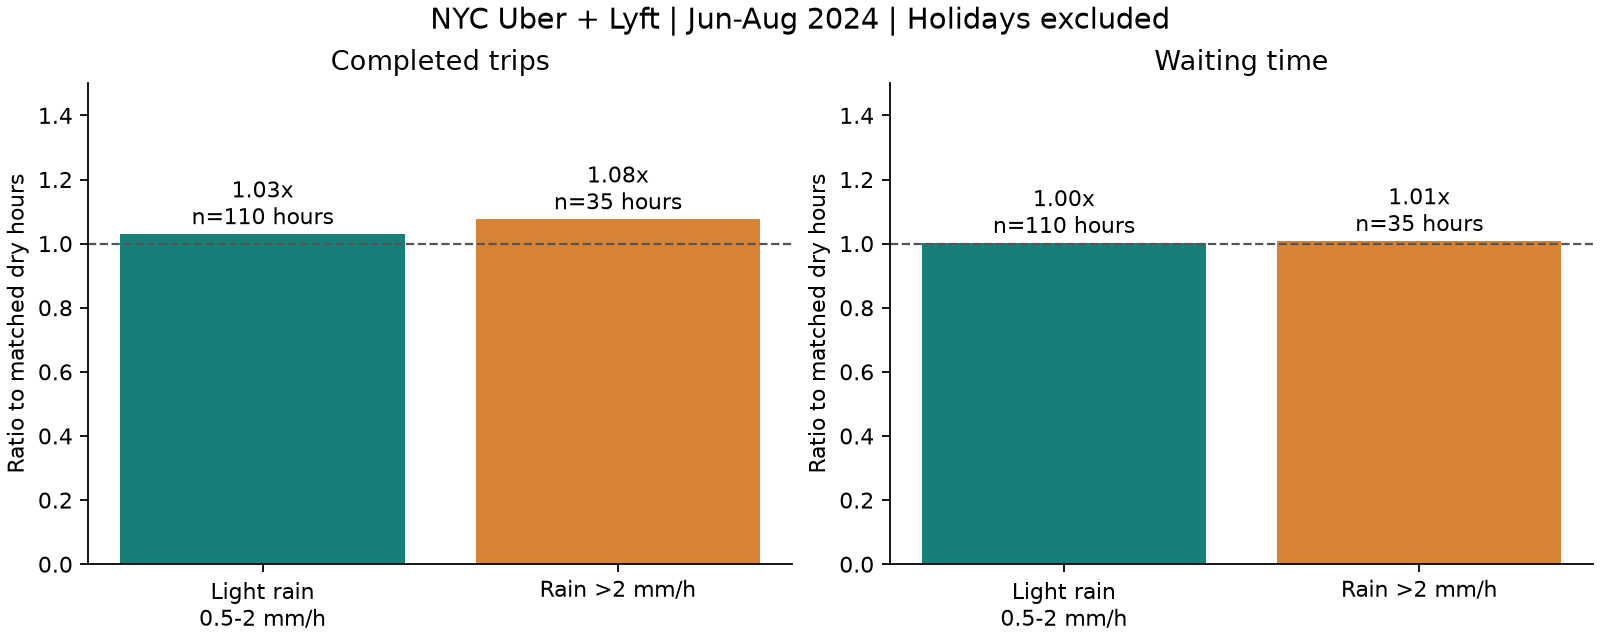

In [30]:
display(pd.read_csv(ROOT / "data/processed/weather_coverage_by_month.csv"))
display(pd.read_csv(ROOT / "data/processed/weather_window_comparison.csv"))
display(rain_factors)
from IPython.display import Image
display(Image(filename=str(ROOT / "reports/rain_factors.png")))

### Kiểm tra một giờ và các case đã rà
Bảng đầu chứa số chuyến giờ mưa và mức khô tham chiếu để tự tính tỷ số. Bảng sau là điều tra có bằng chứng, giả thuyết, giới hạn và bước tiếp; không tuyên bố đã xác định nguyên nhân cuối cùng.

In [31]:
display(pd.read_csv(ROOT / "data/processed/weather_factor_spot_check.csv"))
print(f"Cảnh báo: {len(watchlist):,} dòng ngày/phân khúc; {watchlist.request_date.nunique()} ngày.")
display(investigations[["request_date", "operator", "touches_zone", "evidence", "finding", "next_step"]])
display(pd.read_csv(ROOT / "data/processed/alert_case_comparison.csv")[["request_date", "operator", "touches_zone", "trips_deviation", "fare_excluded_share", "rain_hours", "snow_hours"]])

,request_hour,trips,valid_wait_trips,median_wait_minutes,temperature_c,rain_mm,snowfall_cm,weather_group,weather_event_id,request_date,...,low_fare_trips,valid_fare_trips,valid_distance_trips,valid_driver_pay_trips,valid_economics_trips,total_base_fare,total_driver_pay,source_trips,data_available,holiday_name
0,2024-06-06 02:00:00,8463,8440,3.733333,21.8,2.6,0.0,moderate_or_heavy_rain,2,2024-06-06,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Cảnh báo: 118 dòng ngày/phân khúc; 58 ngày.


,request_date,operator,touches_zone,evidence,finding,next_step
0,2025-01-20,Lyft,False,Chuyến -7.7%; chờ +5.0%; cước không thuộc mẫu ...,Có ngày lễ MLK nhưng biến động không đồng đều ...,So cả bốn phân khúc và ngày lễ năm trước; kiểm...
1,2025-01-21,Lyft,True,Chuyến +9.9%; chờ +2.1%; cước không thuộc mẫu ...,Chuyến tăng đồng thời nhiều cước không thuộc m...,"Rà nguồn cước/chờ; giữ volume, không dùng giá ..."


,request_date,operator,touches_zone,trips_deviation,fare_excluded_share,rain_hours,snow_hours
0,2025-01-20,Lyft,False,-0.076688,0.000023,0,2
1,2025-01-20,Lyft,True,-0.000064,0.000000,0,2
2,2025-01-20,Uber,False,0.026299,0.000329,0,2
3,2025-01-20,Uber,True,0.011760,0.000446,0,2
4,2025-01-21,Lyft,False,0.081592,0.073421,0,1
5,2025-01-21,Lyft,True,0.099278,0.103404,0,1
6,2025-01-21,Uber,False,0.069913,0.000341,0,1
7,2025-01-21,Uber,True,0.079768,0.000327,0,1


## Phí vùng trung tâm: chênh lệch tăng trưởng
So 08-28/01/2024 với 06-26/01/2025: ba tuần, cùng thứ và mỗi kỳ có một ngày MLK. Nhóm chạm vùng dựa trên endpoint; nhóm ngoài vùng là đối chứng giả định. Không coi so sánh này là bằng chứng nhân quả chắc chắn.

### Chọn cửa sổ
Dùng clean_trips đã tạo ngay trong notebook; không cần upload database hoặc script. Các tháng bổ sung mùa hè không tham gia phép tính phí.

In [32]:
FEE_SAMPLE_SQL = """
CREATE OR REPLACE TEMP VIEW fee_sample AS
SELECT *
FROM clean_trips
WHERE request_date BETWEEN DATE '2024-01-08' AND DATE '2024-01-28'
   OR request_date BETWEEN DATE '2025-01-06' AND DATE '2025-01-26'
"""

### Gắn nhãn với từng ngưỡng vùng
Lặp 90%/95%/99% từ profile phí đã có. Chuyến ngắn và giá thấp giữ định nghĩa/giá ngưỡng cố định. Hai nhóm có thể chồng lấn, không cộng các chênh lệch nhóm.

In [33]:
FEE_LABEL_SQL = """
CREATE OR REPLACE TEMP VIEW fee_labeled_trips AS
SELECT t.*,
    CASE WHEN pu.LocationID IS NOT NULL OR do_zone.LocationID IS NOT NULL
         THEN true ELSE false END AS touches_zone,
    CASE WHEN valid_distance = true AND trip_miles < 2
         THEN true ELSE false END AS is_short_trip,
    CASE WHEN valid_fare = true AND base_passenger_fare <= {low_fare_threshold}
         THEN true ELSE false END AS is_low_fare_trip
FROM fee_sample t
LEFT JOIN fee_zones pu ON t.PULocationID = pu.LocationID
LEFT JOIN fee_zones do_zone ON t.DOLocationID = do_zone.LocationID
"""

### Đếm theo ngày
SQL gộp từng ngày × hãng × nhãn vùng. Cước đại diện lấy từ giá dương của đúng nhóm chuyến trong kỳ 2024; lưu số quan sát làm mẫu số.

In [34]:
FEE_DAILY_SQL = """
SELECT request_date, operator, touches_zone,
    COUNT(*) AS trips,
    SUM(CASE WHEN is_short_trip THEN 1 ELSE 0 END) AS short_trips,
    SUM(CASE WHEN is_low_fare_trip THEN 1 ELSE 0 END) AS low_fare_trips,
    SUM(CASE WHEN valid_fare THEN 1 ELSE 0 END) AS fare_sample_count,
    SUM(CASE WHEN valid_fare THEN base_passenger_fare END) AS fare_sample_sum,
    SUM(CASE WHEN is_short_trip AND valid_fare THEN 1 ELSE 0 END) AS short_fare_count,
    SUM(CASE WHEN is_short_trip AND valid_fare THEN base_passenger_fare END) AS short_fare_sum,
    SUM(CASE WHEN is_low_fare_trip THEN 1 ELSE 0 END) AS low_fare_count,
    SUM(CASE WHEN is_low_fare_trip THEN base_passenger_fare END) AS low_fare_sum
FROM fee_labeled_trips
GROUP BY request_date, operator, touches_zone
ORDER BY request_date, operator, touches_zone
"""

### Tính tăng trưởng và phản thực
Gọi A/B là chuyến chạm vùng 2024/2025, C/D là chuyến ngoài vùng. Counterfactual=A×D/C; chênh lệch tương đối=B/counterfactual−1. Hiệu hai tỷ lệ tăng trưởng tính bằng điểm phần trăm được lưu riêng, không dùng thay cho tỷ số này. Giả định chính là hai nhóm sẽ tăng cùng nhịp nếu không có sự kiện.

In [35]:
def describe_fee_windows(root):
    root = Path(root)
    hourly = pd.read_csv(root / "data/processed/hourly_city.csv", parse_dates=["request_date"])
    calendar = pd.read_csv(root / "data/external/holidays.csv", parse_dates=["date"])
    dates = []
    weather_rows = []
    for year, start, end in [(2024, "2024-01-08", "2024-01-28"), (2025, "2025-01-06", "2025-01-26")]:
        for day in pd.date_range(start, end):
            dates.append({"request_date": day, "year": year, "week_index": (day - pd.Timestamp(start)).days // 7,
                          "day_of_week": day.dayofweek, "is_holiday": day in set(calendar.date)})
        data = hourly[hourly.request_date.between(start, end)].copy()
        data["week_index"] = (data.request_date - pd.Timestamp(start)).dt.days // 7
        for week, group in data.groupby("week_index"):
            weather_rows.append({"year": year, "week_index": week,
                                 "start": group.request_date.min(), "end": group.request_date.max(),
                                 "rain_mm": group.rain_mm.sum(), "snowfall_cm": group.snowfall_cm.sum(),
                                 "rain_hours": int((group.rain_mm.gt(0) & group.snowfall_cm.eq(0)).sum()),
                                 "snow_hours": int(group.snowfall_cm.gt(0).sum()),
                                 "holiday_days": int(group.loc[group.is_holiday, "request_date"].nunique())})
    dates = pd.DataFrame(dates)
    weather = pd.DataFrame(weather_rows)
    pair_rain = weather.groupby("week_index").rain_mm.sum().sort_values(ascending=False, kind="stable")
    dropped_week = int(pair_rain.index[0])
    weather["dropped_in_weather_check"] = weather.week_index.eq(dropped_week)
    weather.to_csv(root / "data/processed/fee_comparison_week_weather.csv", index=False)
    dates.to_csv(root / "data/processed/fee_comparison_dates.csv", index=False)
    return dates, weather, dropped_week

def estimate_relative_growth(daily, dates, zone_threshold, zone_count, scenario):
    selected = daily.merge(dates, on="request_date", how="inner", validate="many_to_one")
    distribution = dates.groupby(["year", "day_of_week"]).size().unstack("year")
    if not distribution[2024].equals(distribution[2025]):
        raise ValueError("Comparison windows must have matching weekday counts.")
    holidays = dates.groupby("year").is_holiday.sum()
    count_columns = {"all_trips": ("trips", "fare_sample_count", "fare_sample_sum"),
                     "short_trips": ("short_trips", "short_fare_count", "short_fare_sum"),
                     "low_fare_trips": ("low_fare_trips", "low_fare_count", "low_fare_sum")}
    rows = []
    for operator in ["All", "Uber", "Lyft"]:
        data = selected if operator == "All" else selected[selected.operator.eq(operator)]
        for trip_group, (volume, fare_count, fare_sum) in count_columns.items():
            grouped = data.groupby(["year", "touches_zone"])[[volume, fare_count, fare_sum]].sum()
            a = float(grouped.loc[(2024, True), volume])
            b = float(grouped.loc[(2025, True), volume])
            c = float(grouped.loc[(2024, False), volume])
            d = float(grouped.loc[(2025, False), volume])
            if min(a, b, c, d) <= 0:
                raise ValueError("Each comparison cell must have positive volume.")
            zone_growth = b / a - 1
            outside_growth = d / c - 1
            counterfactual = a * d / c
            effect = b / counterfactual - 1
            trip_difference = b - counterfactual
            price_n = float(grouped.loc[(2024, True), fare_count])
            price_sum = float(grouped.loc[(2024, True), fare_sum])
            representative_fare = price_sum / price_n if price_n > 0 else float("nan")
            assumed_price_change = 1.5 / representative_fare if representative_fare > 0 else float("nan")
            elasticity_proxy = effect / assumed_price_change if assumed_price_change > 0 else float("nan")
            rows.append({"zone_threshold": zone_threshold, "zone_count": zone_count, "scenario": scenario,
                         "operator": operator, "trip_group": trip_group,
                         "days_per_year": int(dates.year.eq(2024).sum()),
                         "holiday_days_2024": int(holidays.loc[2024]), "holiday_days_2025": int(holidays.loc[2025]),
                         "holiday_balance_matches": holidays.loc[2024] == holidays.loc[2025],
                         "zone_trips_2024": int(a), "zone_trips_2025": int(b),
                         "outside_trips_2024": int(c), "outside_trips_2025": int(d),
                         "zone_growth": zone_growth, "outside_growth": outside_growth,
                         "growth_gap_percentage_points": 100 * (zone_growth - outside_growth),
                         "relative_growth_gap": effect, "counterfactual_zone_trips_2025": counterfactual,
                         "estimated_trip_difference": trip_difference,
                         "analysis_total_counterfactual_2025": counterfactual + d,
                         "scaled_total_gap": trip_difference / (counterfactual + d),
                         "representative_base_fare_2024": representative_fare,
                         "fare_sample_count_2024": int(price_n), "assumed_fee_usd": 1.5,
                         "assumed_price_increase": assumed_price_change,
                         "naive_elasticity_proxy": elasticity_proxy,
                         "elasticity_interpretation": "Illustrative ratio only; not identified causal price elasticity, especially for Lyft or pooled platforms"})
    return pd.DataFrame(rows)

### Kiểm tra độ vững
Ngoài ba ngưỡng, bỏ cặp tuần có tổng lượng mưa hai năm lớn nhất, chọn chỉ từ thời tiết. Bỏ cùng bảy thứ ở hai kỳ và kiểm tra số ngày lễ. Tách All/Uber/Lyft. Cùng chiều qua các lựa chọn chỉ cho thấy độ vững mô tả, không xác nhận parallel trends.

In [36]:
def plot_fee_comparison(root, effect):
    root = Path(root)
    os.environ.setdefault("MPLCONFIGDIR", str(root / ".mpl-cache"))
    (root / "reports").mkdir(exist_ok=True)
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
    sections = [(effect[effect.operator.eq("All")], "Trip groups | Uber + Lyft", "trip_group"),
                (effect[effect.trip_group.eq("all_trips")], "Platforms | All trips", "operator")]
    labels = {"all_trips": "All trips", "short_trips": "Short trips", "low_fare_trips": "Low-fare trips"}
    for ax, (data, title, name) in zip(axes, sections):
        values = data.relative_growth_gap.to_numpy() * 100
        ax.bar(range(len(data)), values, color=["#bf6d36" if v < 0 else "#167f78" for v in values])
        ax.axhline(0, color="#555555", linewidth=1)
        ax.set_xticks(range(len(data)), [labels.get(v, v) for v in data[name]])
        for i, value in enumerate(values):
            ax.text(i, value + (1 if value >= 0 else -1), f"{value:+.1f}%", ha="center",
                    va="bottom" if value >= 0 else "top", fontsize=10)
        ax.set_ylim(min(-5, min(values) - 6), max(5, max(values) + 6))
        ax.set_title(title)
        ax.set_ylabel("Relative growth gap (%)")
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle("Zone vs outside | Matched January weeks | 95% zone rule", fontsize=13)
    fig.savefig(root / "reports/congestion_fee_comparison.png", dpi=160)
    plt.close(fig)

def write_fee_report(root, effect, robust, weather, spot, summary):
    lines = ["# Phí vùng trung tâm và chênh lệch tăng trưởng", "",
             "## Phạm vi và phương pháp", "",
             "So 08-28/01/2024 với 06-26/01/2025: 21 ngày, cùng thứ, mỗi kỳ có một ngày MLK. Nhãn chạm vùng dùng endpoint; đối chứng là không chạm vùng. Ngưỡng chính 95%, kiểm tra 90%/99%. Mưa mùa hè không tham gia phép tính này.",
             "Counterfactual = chuyến trong vùng 2024 × (chuyến ngoài vùng 2025 / chuyến ngoài vùng 2024). Chênh lệch tương đối = chuyến trong vùng 2025 / counterfactual - 1. Đây là ratio-of-ratios, không phải hiệu hai tỷ lệ tăng trưởng tính bằng điểm phần trăm.",
             "", "## Kết quả chính", "", "| Hãng | Nhóm chuyến | Tăng trưởng chạm vùng | Tăng trưởng ngoài vùng | Chênh lệch tương đối | Chênh lệch chuyến phản thực |", "|---|---|---:|---:|---:|---:|"]
    for r in effect.itertuples(index=False):
        lines.append(f"| {r.operator} | {r.trip_group} | {r.zone_growth:+.2%} | {r.outside_growth:+.2%} | {r.relative_growth_gap:+.2%} | {r.estimated_trip_difference:+,.0f} |")
    r = spot.iloc[0]
    actual_total_growth = (r.zone_trips_2025 + r.outside_trips_2025) / (r.zone_trips_2024 + r.outside_trips_2024) - 1
    lines += ["", "## Tính tay một dòng", "",
              f"Tổng chuyến thực tế trong mẫu tăng {actual_total_growth:+.2%} so với cùng kỳ. Chênh lệch {r.relative_growth_gap:+.2%} dưới đây áp cho nhóm chạm vùng so với nhịp tăng của đối chứng, không phải toàn thị trường giảm từng đó.",
              f"Chạm vùng: {int(r.zone_trips_2024):,} → {int(r.zone_trips_2025):,}; ngoài vùng: {int(r.outside_trips_2024):,} → {int(r.outside_trips_2025):,}.",
              f"Nếu nhóm chạm vùng tăng cùng nhịp đối chứng: {int(r.zone_trips_2024):,} × {int(r.outside_trips_2025):,} / {int(r.outside_trips_2024):,} = {r.counterfactual_zone_trips_2025:,.2f} chuyến.",
              f"Thực tế / phản thực - 1 = {r.relative_growth_gap:.6f}, tức {r.relative_growth_gap:+.2%}. Chênh lệch {r.estimated_trip_difference:+,.2f} chuyến chỉ là ước tính dưới giả định đối chứng, không phải số chuyến mất đã quan sát trực tiếp.",
              "", "## Độ vững", "", "| Hãng | Nhóm | Khoảng chênh lệch qua 6 lựa chọn | Cùng chiều? |", "|---|---|---|---|"]
    for v in robust.itertuples(index=False):
        lines.append(f"| {v.operator} | {v.trip_group} | {v.min_relative_gap:+.2%} đến {v.max_relative_gap:+.2%} | {v.same_direction} |")
    dropped = weather[weather.dropped_in_weather_check]
    lines += ["", "Bỏ cặp tuần có tổng lượng mưa hai năm lớn nhất, cùng bảy thứ ở hai kỳ. Không chỉ bỏ tuần ở một năm. Các phương án đều giữ số ngày lễ bằng nhau trong dữ liệu hiện tại. Khoảng sensitivity không phải khoảng tin cậy thống kê.", ""]
    for v in dropped.itertuples(index=False):
        lines.append(f"- {v.year}: bỏ {v.start:%d/%m}–{v.end:%d/%m}, mưa {v.rain_mm:.1f} mm, tuyết {v.snowfall_cm:.2f} cm.")
    lines += ["", "## Độ nhạy giá: chỉ minh họa", "",
              "Lấy cước cơ bản trung bình dương của nhóm chạm vùng trong kỳ 2024, giả định giá tăng $1,50/cước đó, rồi chia chênh lệch tương đối cho tỷ lệ tăng giá. naive_elasticity_proxy được xuất để hiểu phép tính, không coi là độ nhạy giá nhân quả: cước không gồm mọi phí/thuế, giá động và mix chuyến thay đổi, Lyft có credit tương lai, đối chứng có thể bị ảnh hưởng.",
              "Nhóm giá thấp là nhóm theo ngưỡng cước cố định trong mỗi kỳ, không phải cùng khách hoặc cùng tuyến; cước tăng cũng làm chuyến chuyển ra khỏi nhóm. Chuyến ngắn và giá thấp có thể chồng lấn, không cộng các tác động nhóm.",
              "", "## Đối chiếu nghiên cứu", "",
              "Tóm tắt của Zhang, Sang & Wu (2026) trên Transportation Research Part A báo cáo giảm tổng ride-hailing khoảng 0,5–1,5%, Uber giảm tới 6% và Lyft tăng 2–5% trong kỳ credit; phản ứng tập trung ở chuyến ngắn/giá thấp. Họ dùng thiết kế two-way fixed effects. Nguồn: [tạp chí](https://www.sciencedirect.com/science/article/pii/S0965856426001072), DOI 10.1016/j.tra.2026.104966.",
              "Demo này chỉ đối chiếu tóm tắt công bố, không tái lập mô hình của nghiên cứu. Có điểm tương đồng về hướng khác nhau giữa hai hãng và nhóm giá thấp nhạy hơn, nhưng độ lớn khác rõ. Nhóm chạm vùng và mẫu số của ratio-of-ratios không đồng nhất với tổng ride-hailing nghiên cứu. scaled_total_gap quy đổi sang tổng mẫu phản thực dưới chính giả định demo, vẫn không phải ước lượng tương đương của nghiên cứu.",
              f"Dòng All/all_trips sau quy đổi theo tổng mẫu phản thực là {r.scaled_total_gap:+.2%}; vẫn khác khoảng công bố và không thể coi là so sánh cùng thiết kế.",
              "", "## Giới hạn và cách diễn giải", "",
              "- Cùng chiều qua sensitivity không xác nhận parallel trends. Dữ liệu trước sự kiện ngắn và cách so cùng kỳ không kiểm soát hết thay đổi giữa hai năm.",
              "- Nhóm ngoài vùng có chuyến xuyên vùng chịu phí; dòng kiểm tra fee_label_diagnostics.csv đã cho thấy sai khác nhãn. Đối chứng còn có thể chịu tác động chuyển hãng/chuyển điểm đón.",
              "- Kỳ so có mưa/tuyết khác nhau; chỉ bỏ một cặp tuần chưa kiểm soát đầy đủ thời tiết.",
              "- Lyft credit xảy ra cùng lúc; gộp hai hãng phản ánh nhiều thay đổi, tách Uber vẫn chưa loại cạnh tranh/chuyển hãng.",
              "- Chỉ đo chuyến hoàn thành của tập giữ lại, không đo mọi yêu cầu đặt xe hay booking bị hủy.",
              "- Cách viết phù hợp: nhóm chạm vùng tăng trưởng thấp hơn/cao hơn đối chứng X% trong cửa sổ này. Không viết phí chắc chắn làm mất X% chuyến hoặc dùng proxy elasticity để quyết định tăng giá.", ""]
    (root / "docs/congestion_fee_report.md").write_text("\n".join(lines))

def analyze_congestion_fee(root):
    root = Path(root).resolve()
    parameters = json.loads((root / "docs/trip_processing_parameters.json").read_text())
    threshold = float(parameters["low_fare_threshold_usd"])
    profile = pd.read_csv(root / "data/processed/zone_fee_profile.csv")
    dates, weather, dropped_week = describe_fee_windows(root)
    database = root / ".analysis-cache/trip_processing.duckdb"
    if not database.exists():
        raise FileNotFoundError("Run the preceding cleaning cells to create the analysis sample.")
    con = duckdb.connect(str(database))
    con.execute("SET threads=4")
    con.execute("SET memory_limit='2GB'")
    con.execute(FEE_SAMPLE_SQL)
    scenarios = []
    daily_frames = []
    for zone_threshold in [.90, .95, .99]:
        zones = profile.loc[profile.fee_rate.ge(zone_threshold), ["LocationID"]]
        if zones.empty or not zones.LocationID.is_unique:
            raise ValueError("Congestion-zone list must be nonempty and unique.")
        con.register("fee_zones", zones)
        label_query = FEE_LABEL_SQL.format(low_fare_threshold=repr(threshold))
        con.execute(label_query)
        daily = con.execute(FEE_DAILY_SQL).df()
        count_columns = ["trips", "short_trips", "low_fare_trips", "fare_sample_count", "short_fare_count", "low_fare_count"]
        daily[count_columns] = daily[count_columns].astype("int64")
        if zone_threshold == .95:
            previous = pd.read_csv(root / "data/processed/daily_segment.csv", parse_dates=["request_date"])
            previous = previous[previous.request_date.isin(dates.request_date)]
            keys = ["request_date", "operator", "touches_zone"]
            pd.testing.assert_frame_equal(daily.set_index(keys)[["trips", "short_trips", "low_fare_trips"]].sort_index(),
                                          previous.set_index(keys)[["trips", "short_trips", "low_fare_trips"]].sort_index(), check_dtype=False)
        daily_frames.append(daily.assign(zone_threshold=zone_threshold, zone_count=len(zones)))
        for scenario, chosen_dates in [("full_window", dates),
                                       ("drop_rainiest_matched_week", dates[dates.week_index.ne(dropped_week)])]:
            scenarios.append(estimate_relative_growth(daily, chosen_dates, zone_threshold, len(zones), scenario))
    con.close()
    sensitivity = pd.concat(scenarios, ignore_index=True)
    effect = sensitivity[sensitivity.zone_threshold.eq(.95) & sensitivity.scenario.eq("full_window")].copy()
    robust_rows = []
    for (operator, group), variants in sensitivity.groupby(["operator", "trip_group"], sort=False):
        base = float(effect[effect.operator.eq(operator) & effect.trip_group.eq(group)].relative_growth_gap.iloc[0])
        values = variants.relative_growth_gap
        same_direction = bool(values.gt(0).all()) if base > 0 else bool(values.lt(0).all()) if base < 0 else bool(values.abs().lt(1e-12).all())
        robust_rows.append({"operator": operator, "trip_group": group, "main_relative_gap": base,
                            "min_relative_gap": values.min(), "max_relative_gap": values.max(),
                            "variants": len(variants), "same_direction": same_direction,
                            "interpretation": "Direction stability only; not proof of causality or parallel trends"})
    robust = pd.DataFrame(robust_rows)
    effect.to_csv(root / "data/processed/fee_effect.csv", index=False)
    sensitivity.to_csv(root / "data/processed/fee_sensitivity.csv", index=False)
    robust.to_csv(root / "data/processed/fee_robustness_summary.csv", index=False)
    pd.concat(daily_frames, ignore_index=True).to_csv(root / "data/processed/fee_daily_counts_by_zone_rule.csv", index=False)
    for name, sql in [("select_fee_comparison_sample.sql", FEE_SAMPLE_SQL),
                      ("label_fee_comparison_trips.sql", label_query), ("aggregate_fee_comparison_days.sql", FEE_DAILY_SQL)]:
        (root / "sql" / name).write_text(sql.strip() + ";\n")
    spot = effect[effect.operator.eq("All") & effect.trip_group.eq("all_trips")].copy()
    r = spot.iloc[0]
    manual_cf = r.zone_trips_2024 * r.outside_trips_2025 / r.outside_trips_2024
    manual_effect = (r.zone_trips_2025 / r.zone_trips_2024) / (r.outside_trips_2025 / r.outside_trips_2024) - 1
    assert math.isclose(manual_cf, r.counterfactual_zone_trips_2025, rel_tol=1e-12)
    assert math.isclose(manual_effect, r.relative_growth_gap, rel_tol=1e-12)
    assert len(effect) == 9 and len(sensitivity) == 54
    assert effect.days_per_year.eq(21).all()
    assert sensitivity[sensitivity.scenario.eq("drop_rainiest_matched_week")].days_per_year.eq(14).all()
    assert sensitivity.holiday_balance_matches.all()
    spot.to_csv(root / "data/processed/fee_effect_spot_check.csv", index=False)
    plot_fee_comparison(root, effect)
    summary = {"completed_at_utc": datetime.now(timezone.utc).isoformat(),
               "reference_window": ["2024-01-08", "2024-01-28"], "comparison_window": ["2025-01-06", "2025-01-26"],
               "main_zone_threshold": .95, "low_fare_threshold_usd": threshold,
               "main_rows": len(effect), "sensitivity_rows": len(sensitivity),
               "rainiest_matched_week_index_removed": dropped_week,
               "weather_rule": "Maximum combined rain_mm in matched week pairs, selected without trip outcomes; remove corresponding seven-day block from each year",
               "all_trips_relative_gap": float(r.relative_growth_gap),
               "all_directions_stable": bool(robust.same_direction.all()),
               "elasticity": "Naive illustrative ratio, not an identified elasticity",
               "identification_limit": "Requires parallel growth absent policy and unaffected controls; neither is established with this short dataset"}
    (root / "docs/congestion_fee_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False) + "\n")
    write_fee_report(root, effect, robust, weather, spot, summary)
    print(f"Relative-growth comparison completed: {len(effect)} main estimates, {len(sensitivity)} sensitivity estimates.")
    return effect, sensitivity, robust, weather

In [37]:
fee_effect, fee_sensitivity, fee_robustness, comparison_weather = analyze_congestion_fee(ROOT)

Relative-growth comparison completed: 9 main estimates, 54 sensitivity estimates.


### Kết quả chính và sensitivity
Tổng chuyến thực tế vẫn có thể tăng dù nhóm chạm vùng tăng chậm hơn đối chứng. Chênh lệch tương đối không phải mức giảm toàn thị trường.

,operator,trip_group,zone_growth,outside_growth,relative_growth_gap,estimated_trip_difference
18,All,all_trips,-0.044445,0.055765,-0.094917,-498015.853367
19,All,short_trips,-0.053281,0.070871,-0.115936,-202790.166888
20,All,low_fare_trips,-0.186800,0.068494,-0.238928,-160191.621032
21,Uber,all_trips,-0.077606,0.102104,-0.163061,-675415.717528
22,Uber,short_trips,-0.105544,0.129427,-0.208044,-300138.802819
23,Uber,low_fare_trips,-0.333913,0.142279,-0.416879,-225398.887922
24,Lyft,all_trips,0.058437,-0.069030,0.136918,154411.143304
25,Lyft,short_trips,0.134214,-0.070591,0.220361,72921.003917
26,Lyft,low_fare_trips,0.264947,-0.119536,0.436682,59265.683325


,operator,trip_group,main_relative_gap,min_relative_gap,max_relative_gap,variants,same_direction,interpretation
0,All,all_trips,-0.094917,-0.094917,-0.092650,6,True,Direction stability only; not proof of causali...
1,All,short_trips,-0.115936,-0.116451,-0.114932,6,True,Direction stability only; not proof of causali...
2,All,low_fare_trips,-0.238928,-0.242116,-0.238928,6,True,Direction stability only; not proof of causali...
3,Uber,all_trips,-0.163061,-0.163061,-0.159950,6,True,Direction stability only; not proof of causali...
4,Uber,short_trips,-0.208044,-0.208044,-0.206700,6,True,Direction stability only; not proof of causali...
5,Uber,low_fare_trips,-0.416879,-0.418927,-0.409531,6,True,Direction stability only; not proof of causali...
6,Lyft,all_trips,0.136918,0.136680,0.144443,6,True,Direction stability only; not proof of causali...
7,Lyft,short_trips,0.220361,0.216738,0.229130,6,True,Direction stability only; not proof of causali...
8,Lyft,low_fare_trips,0.436682,0.419783,0.436682,6,True,Direction stability only; not proof of causali...


,year,week_index,start,end,rain_mm,snowfall_cm,rain_hours,snow_hours,holiday_days,dropped_in_weather_check
0,2024,0,2024-01-08,2024-01-14,63.2,0.00,34,0,0,True
1,2024,1,2024-01-15,2024-01-21,1.5,9.73,1,36,1,False
2,2024,2,2024-01-22,2024-01-28,38.4,0.00,69,0,0,False
3,2025,0,2025-01-06,2025-01-12,0.0,2.66,0,17,0,True
4,2025,1,2025-01-13,2025-01-19,5.5,4.62,8,11,0,False
5,2025,2,2025-01-20,2025-01-26,0.0,0.21,0,3,1,False


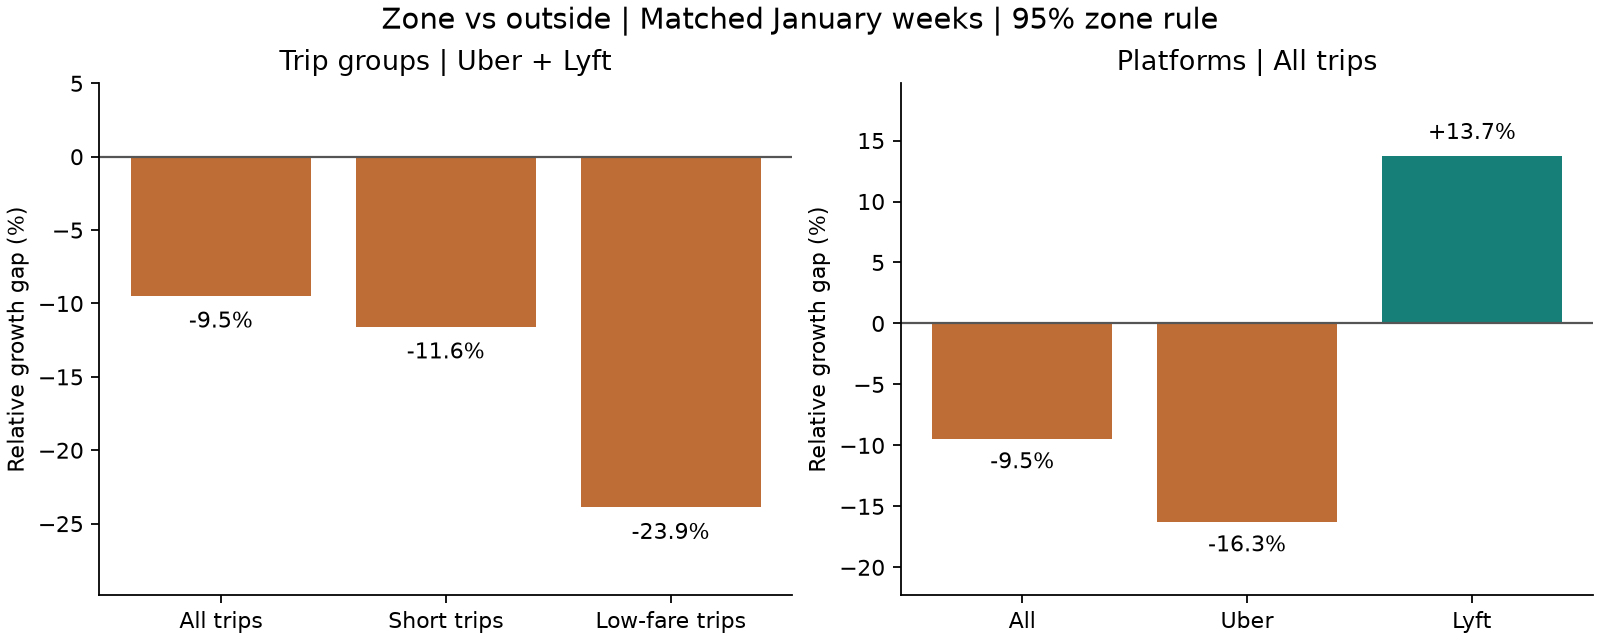

In [38]:
display(fee_effect[["operator", "trip_group", "zone_growth", "outside_growth", "relative_growth_gap", "estimated_trip_difference"]])
display(fee_robustness)
display(comparison_weather)
display(Image(filename=str(ROOT / "reports/congestion_fee_comparison.png")))

### Tự tính một dòng và đọc giới hạn
Bảng đầu chứa bốn số chuyến A/B/C/D và counterfactual để tính tay. Proxy độ nhạy giá = chênh lệch tương đối / ($1,50/cước đại diện). Đây chỉ là tỷ số minh họa: chưa đo thay đổi tổng giá thực trả, đối chứng có thể bị ảnh hưởng và Lyft có credit tương lai. Không dùng proxy để quyết định tăng giá.

Nhóm giá thấp được phân theo cước từng kỳ, không phải cùng khách/tuyến; cước tăng cũng làm chuyến rời nhóm. scaled_total_gap dùng tổng mẫu phản thực của chính nhóm đang phân tích, không mặc định là tác động lên toàn bộ NYC.

In [39]:
display(pd.read_csv(ROOT / "data/processed/fee_effect_spot_check.csv"))
display(fee_effect[["operator", "trip_group", "representative_base_fare_2024", "assumed_price_increase", "naive_elasticity_proxy", "scaled_total_gap"]])

,zone_threshold,zone_count,scenario,operator,trip_group,days_per_year,holiday_days_2024,holiday_days_2025,holiday_balance_matches,zone_trips_2024,...,counterfactual_zone_trips_2025,estimated_trip_difference,analysis_total_counterfactual_2025,scaled_total_gap,representative_base_fare_2024,fare_sample_count_2024,assumed_fee_usd,assumed_price_increase,naive_elasticity_proxy,elasticity_interpretation
0,0.95,38,full_window,All,all_trips,21,1,1,True,4969745,...,5.246881e+06,-498015.853367,1.459597e+07,-0.03412,29.055642,4967239,1.5,0.051625,-1.838574,Illustrative ratio only; not identified causal...


,operator,trip_group,representative_base_fare_2024,assumed_price_increase,naive_elasticity_proxy,scaled_total_gap
18,All,all_trips,29.055642,0.051625,-1.838574,-0.034120
19,All,short_trips,14.450618,0.103802,-1.116896,-0.037178
20,All,low_fare_trips,9.354105,0.160357,-1.489974,-0.043443
21,Uber,all_trips,29.552001,0.050758,-3.212515,-0.059990
22,Uber,short_trips,14.786005,0.101447,-2.050758,-0.071349
23,Uber,low_fare_trips,9.315822,0.161016,-2.589047,-0.078894
24,Lyft,all_trips,27.512536,0.054521,2.511316,0.045955
25,Lyft,short_trips,13.244695,0.113253,1.945743,0.057311
26,Lyft,low_fare_trips,9.471664,0.158367,2.757401,0.070864


### So với nghiên cứu công bố
Tóm tắt [Zhang, Sang & Wu (2026)](https://www.sciencedirect.com/science/article/pii/S0965856426001072) dùng two-way fixed effects và báo cáo tác động khác nhau giữa hãng, tập trung ở chuyến ngắn/giá thấp. Demo chỉ đối chiếu tóm tắt, không tái lập mô hình nghiên cứu. Cửa sổ, nhóm và mẫu số khác nhau nên không yêu cầu con số khớp.

Ngoài vùng vẫn có chuyến xuyên vùng chịu phí và có thể chịu spillover/chuyển hãng. Hai năm có thời tiết và thị trường khác nhau; dữ liệu trước sự kiện còn ngắn. Cách viết kết quả là chênh lệch tăng trưởng tương đối trong cửa sổ đã chọn, không phải phí chắc chắn làm mất từng ấy chuyến.

## Lyft credit: thị phần và kinh tế khuyến mãi
Lyft cấp credit $1,50 cho chuyến tương lai hoặc Citi Bike, không hoàn tiền mặt. Credit phát từ 05-31/01/2025 và có hiệu lực một tuần sau chuyến đầu; đầu tháng 02 có thể còn carryover. Nguồn: [Lyft](https://www.lyft.com/blog/posts/navigating-the-new-nyc-congestion-fee-with-lyft).

Phần này đọc bảng ngày vừa tạo trong notebook. Không cần script, Excel hoặc CSV upload từ bên ngoài. Kết quả dùng dữ liệu tới 23/02/2025, là phân tích hồi cứu; không dùng như thông tin đã biết tại 16/02 cho kế hoạch dự báo.

### So thị phần trên hai cửa sổ
Thị phần = chuyến Lyft / (Uber + Lyft), tách chạm vùng và ngoài vùng. So 06-26/01 với 03-23/02, mỗi kỳ 21 ngày và một lễ thứ Hai. Chênh lệch = (share trong vùng tháng 01 - tháng 02) - (share ngoài vùng tháng 01 - tháng 02).

Uplift xấp xỉ chia chênh lệch cho share trong vùng tháng 02. Proxy thị trường cố định dùng share phản thực và quy mô thị trường tháng 01; hai cách có mẫu số khác nhau. Chúng phụ thuộc giả định đối chứng không bị ảnh hưởng và không xác nhận tác động nhân quả. Coverage phải đủ mọi ngày × hãng × nhãn vùng trước khi tính.

In [40]:
def summarize_credit_periods(daily, off_start="2025-02-03", off_end="2025-02-23"):
    rows = []
    periods = [("credit_issuance", "2025-01-06", "2025-01-26"), ("post_issuance", off_start, off_end)]
    for period, start, end in periods:
        data = daily[daily.request_date.between(start, end)]
        expected = pd.MultiIndex.from_product([pd.date_range(start, end), ["Uber", "Lyft"], [False, True]],
                                              names=["request_date", "operator", "touches_zone"])
        actual = pd.MultiIndex.from_frame(data[["request_date", "operator", "touches_zone"]])
        if actual.has_duplicates or len(actual) != len(expected) or len(expected.difference(actual)):
            raise ValueError("Credit comparison needs complete unique daily segment coverage.")
        for touches_zone, group in data.groupby("touches_zone"):
            trips = group.groupby("operator").trips.sum()
            paired = group[group.operator.eq("Lyft")]
            row = {"period": period, "start": start, "end": end, "touches_zone": bool(touches_zone),
                   "days": int(group.request_date.nunique()), "holiday_days": int(group.loc[group.is_holiday, "request_date"].nunique()),
                   "lyft_trips": int(trips.loc["Lyft"]), "uber_trips": int(trips.loc["Uber"]),
                   "lyft_valid_economics_trips": int(paired.valid_economics_trips.sum()),
                   "lyft_base_fare_sum": float(paired.total_base_fare.sum()),
                   "lyft_driver_pay_sum": float(paired.total_driver_pay.sum())}
            row["market_trips"] = row["lyft_trips"] + row["uber_trips"]
            row["lyft_share"] = row["lyft_trips"] / row["market_trips"]
            row["reported_fare_pay_gap_proxy"] = (row["lyft_base_fare_sum"] - row["lyft_driver_pay_sum"]) / row["lyft_valid_economics_trips"]
            rows.append(row)
    periods = pd.DataFrame(rows)
    lookup = periods.set_index(["period", "touches_zone"])
    on_zone = lookup.loc[("credit_issuance", True)]
    off_zone = lookup.loc[("post_issuance", True)]
    on_out = lookup.loc[("credit_issuance", False)]
    off_out = lookup.loc[("post_issuance", False)]
    difference = (on_zone.lyft_share - off_zone.lyft_share) - (on_out.lyft_share - off_out.lyft_share)
    counterfactual_share = off_zone.lyft_share + on_out.lyft_share - off_out.lyft_share
    if not 0 < counterfactual_share < 1:
        raise ValueError("Adjusted reference share must be between zero and one.")
    delta = difference * on_zone.market_trips
    summary = {"share_difference": float(difference), "share_difference_percentage_points": float(difference * 100),
               "approx_uplift_vs_post_share": float(difference / off_zone.lyft_share),
               "counterfactual_credit_period_share": float(counterfactual_share),
               "fixed_market_incremental_trip_proxy": float(delta),
               "fixed_market_counterfactual_lyft_trips": float(counterfactual_share * on_zone.market_trips),
               "fixed_market_uplift_proxy": float(difference / counterfactual_share),
               "credit_period_share_in_zone": float(on_zone.lyft_share),
               "post_period_share_in_zone": float(off_zone.lyft_share),
               "credit_period_share_outside": float(on_out.lyft_share),
               "post_period_share_outside": float(off_out.lyft_share),
               "lyft_zone_volume_change_post_vs_credit": float(off_zone.lyft_trips / on_zone.lyft_trips - 1),
               "uber_zone_volume_change_post_vs_credit": float(off_zone.uber_trips / on_zone.uber_trips - 1),
               "market_zone_volume_change_post_vs_credit": float(off_zone.market_trips / on_zone.market_trips - 1),
               "interpretation": "Observed share difference; uplift and trip counts are proxies under fixed-market and unaffected-control assumptions, not causal campaign ROI"}
    return periods, summary

### Chi phí credit và mẫu số hòa vốn
N là chuyến nền, u là uplift trên toàn bộ N, s là phần chuyến nền nhận credit, a là phần chuyến tăng thêm nhận credit, c là mệnh giá, r là tỷ lệ sử dụng, m là contribution margin giả định mỗi chuyến tăng thêm.

Chi phí = N × (s + a × u) × c × r. Contribution thêm = N × u × m. Hòa vốn toàn mẫu = s × c × r / (m - a × c × r), khi mẫu số dương. Hòa vốn trên chuyến nền đủ điều kiện bằng ngưỡng toàn mẫu / s, nếu toàn bộ incrementals thuộc nhóm đó. Quy đổi sang uplift theo người dùng còn cần tính tương đương về population, thời gian và số chuyến nền.

Mặc định m=$6 chỉ là giả định; cước trừ driver pay không phải contribution margin thật. TLC không có redemption, customer ID, retention hoặc toàn bộ chi phí nền tảng. Targeting mới cần giả định uplift mới. Chi phí/chuyến tăng thêm không xác định khi uplift=0; margin không đủ được báo rõ.

In [41]:
def credit_economics(base_trips=100, uplift=.03, credit=1.5, margin=6, coverage=1,
                     redemption=1, incremental_credit_fraction=1):
    values = [base_trips, uplift, credit, margin, coverage, redemption, incremental_credit_fraction]
    if not all(math.isfinite(x) for x in values):
        raise ValueError("Economic inputs must be finite.")
    if min(base_trips, uplift, credit, margin) < 0 or not 0 < coverage <= 1 or not 0 <= redemption <= 1 or not 0 <= incremental_credit_fraction <= 1:
        raise ValueError("Invalid economic inputs.")
    effective_credit = credit * redemption
    extra = base_trips * uplift
    issued = base_trips * coverage + extra * incremental_credit_fraction
    redeemed = issued * redemption
    cost = issued * effective_credit
    contribution = extra * margin
    net = contribution - cost
    denominator = margin - incremental_credit_fraction * effective_credit
    if denominator > 0:
        breakeven = coverage * effective_credit / denominator
    elif coverage * effective_credit == 0 and denominator == 0:
        breakeven = 0.0
    else:
        breakeven = None
    return {"base_trips": base_trips, "uplift": uplift, "credit_usd": credit, "margin_usd": margin,
            "coverage": coverage, "redemption": redemption, "incremental_credit_fraction": incremental_credit_fraction,
            "effective_credit_usd": effective_credit, "incremental_trips": extra, "credits_issued": issued,
            "credits_redeemed": redeemed, "credit_cost_usd": cost, "incremental_contribution_usd": contribution,
            "net_incremental_contribution_usd": net, "cost_per_incremental_trip_usd": cost / extra if extra > 0 else None,
            "breakeven_global_uplift": breakeven,
            "breakeven_eligible_uplift": breakeven / coverage if breakeven is not None else None,
            "uplift_denominator": "All base trips; eligible-population threshold divides by baseline-trip coverage"}

### Xuất kết quả và brief thử nghiệm
Hàm dưới tạo thị phần tuần (đánh dấu tuần thiếu ngày), volume theo kỳ, sensitivity bỏ tuần đầu tháng 02, 24 kịch bản margin/redemption/coverage và các ví dụ tính tay. Biểu đồ, báo cáo, brief và hồ sơ đối chiếu đều được tạo từ notebook.

Excel và PDF một trang là bản trình bày riêng; notebook vẫn chạy đầy đủ và tạo brief Markdown khi chưa có các bản đó. Các kiểm tra dữ liệu diễn ra tự động, dừng phân tích nếu đối chiếu sai.

In [42]:
def plot_credit_analysis(root, weekly, comparison):
    root = Path(root)
    os.environ.setdefault("MPLCONFIGDIR", str(root / ".mpl-cache"))
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    for touches, label, color in [(True, "Zone endpoints", "#d78335"), (False, "Outside endpoints", "#157f78")]:
        data = weekly[weekly.touches_zone.eq(touches)]
        ax.plot(data.week_start, data.lyft_share * 100, marker="o", label=label, color=color)
    ax.axvspan(pd.Timestamp("2025-01-05"), pd.Timestamp("2025-01-31"), color="#d78335", alpha=.10, label="Credit issuance")
    ax.set_title("Lyft weekly share of completed Uber + Lyft trips")
    ax.set_ylabel("Share (%)")
    ax.legend(loc="lower left", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    fig.savefig(root / "reports/lyft_share_weekly.png", dpi=160)
    plt.close(fig)


def write_credit_report(root, periods, summary, default, sensitivity):
    lines = ["# Lyft credit: thị phần và kinh tế theo kịch bản", "",
             "## So sánh quan sát", "",
             "06-26/01/2025 so với 03-23/02/2025: cùng ba tuần, cùng thứ và một lễ thứ Hai. Credit phát trong 05-31/01 và dùng cho chuyến tương lai/Citi Bike trong tuần kế tiếp; giai đoạn đầu tháng 02 có thể còn credit. Ngoài vùng cũng có thể hưởng credit.",
             "", "| Kỳ | Nhãn vùng | Lyft | Uber | Thị phần Lyft |", "|---|---|---:|---:|---:|"]
    for r in periods.itertuples(index=False):
        lines.append(f"| {r.period} | {r.touches_zone} | {r.lyft_trips:,} | {r.uber_trips:,} | {r.lyft_share:.2%} |")
    lines += ["", f"Chênh lệch của thay đổi thị phần = {summary['share_difference_percentage_points']:+.3f} điểm phần trăm. Quy đổi xấp xỉ theo deck, chia cho thị phần Lyft trong vùng giai đoạn sau: {summary['approx_uplift_vs_post_share']:.2%}.",
              f"Nếu giữ quy mô thị trường tháng 01 cố định và điều chỉnh mức share phản thực bằng thay đổi ngoài vùng, proxy là {summary['fixed_market_incremental_trip_proxy']:,.0f} chuyến, uplift trên chính mẫu phản thực {summary['fixed_market_uplift_proxy']:.2%}. Hai tỷ lệ khác mẫu số; không coi là hai ước lượng nhân quả độc lập.",
              f"Từ kỳ January sang February, volume trong vùng: Lyft {summary['lyft_zone_volume_change_post_vs_credit']:+.2%}, Uber {summary['uber_zone_volume_change_post_vs_credit']:+.2%}, tổng {summary['market_zone_volume_change_post_vs_credit']:+.2%}. Lyft không giảm volume tuyệt đối dù share giảm; chưa kết luận toàn bộ chênh lệch là lấy chuyến từ Uber hay tạo nhu cầu mới.",
              "", "## Bỏ tuần đầu tháng 02", ""]
    for r in sensitivity.itertuples(index=False):
        lines.append(f"- {r.comparison}: {r.share_difference_percentage_points:+.3f} pp; uplift xấp xỉ {r.approx_uplift_vs_post_share:.2%}; {r.credit_days} ngày kỳ credit so {r.post_days} ngày kỳ sau.")
    lines += ["", "Phép kiểm tra 10-23/02 giảm lo ngại carryover nhưng có hai tuần so ba tuần, khác thành phần thứ/lễ; chỉ là độ vững tham khảo, không dùng volume thô để suy ra tăng giảm nhân quả.",
              "", "## Mô hình kinh tế", "",
              "N: chuyến nền; u: uplift trên toàn bộ N; s: phần chuyến nền nhận credit; a: phần chuyến tăng thêm nhận credit; c: mệnh giá; r: tỷ lệ sử dụng; m: contribution margin giả định mỗi chuyến tăng thêm.",
              "Credit cost=N×(s+a×u)×c×r. Contribution thêm=N×u×m. Chênh lệch=N×[u×(m−a×c×r)−s×c×r]. Hòa vốn toàn mẫu u*=s×c×r/(m−a×c×r), nếu mẫu số dương. Hòa vốn riêng nhóm đủ điều kiện=u*/s khi incrementals nằm trong nhóm đó.",
              f"Mặc định N=100, c=$1,50, m=$6 (giả định), r=100%, s=100%, a=100%, u={default['uplift']:.2%}: cost/extra trip=${default['cost_per_incremental_trip_usd']:.2f}; net contribution=${default['net_incremental_contribution_usd']:.2f}/100 chuyến nền. Đây không phải ROI thực tế.",
              "m=$6 không lấy trực tiếp từ cước trừ driver pay. TLC không có đủ chi phí nền tảng. Credit cost là mệnh giá kỳ vọng được dùng, chưa có redemption/cost thực tế và chưa tính lợi ích tương lai hay Citi Bike.",
              "", "## Hai ví dụ cần tự giải thích", "",
              "100 chuyến nền, u=3%, hoàn toàn bộ và dùng hết: 103 credit ×$1,50=$154,50; 3 chuyến thêm đem $18 contribution; cost/extra=$51,50. Hòa vốn=33,33%.",
              "Chỉ trợ giá 30% chuyến nền, r=100%, a=100%: hòa vốn=10% toàn mẫu, tương đương 33,33% trên nhóm đủ điều kiện. Không dùng ngưỡng 10% cho KPI uplift đo riêng nhóm eligible. Đổi targeting phải ước tính lại uplift, không giả định đáp ứng giữ nguyên.",
              "", "## Sản phẩm và giới hạn", "",
              "Excel riêng có nguồn counts, công thức thị phần, input chỉnh được và sensitivity hòa vốn. Notebook tự chứa các phép tính và xuất CSV/JSON; không cần Excel hay builder để chạy trên Colab.",
              "Không có customer ID, credit redemption, retention hoặc lợi nhuận đóng góp trong dữ liệu công khai. Khác mùa/thời tiết, cạnh tranh và nhóm đối chứng hưởng credit làm giả định DiD chưa được kiểm chứng. Kết quả dùng để thiết kế thử nghiệm, không phê duyệt chi phí chiến dịch thật.",
              "Nguồn credit: [Lyft](https://www.lyft.com/blog/posts/navigating-the-new-nyc-congestion-fee-with-lyft). Nguồn volume: daily_segment.csv từ NYC TLC, quy tắc trong trip_data_quality.md.", ""]
    (root / "docs/lyft_credit_report.md").write_text("\n".join(lines))


def write_credit_experiment_brief(root):
    text = """# Campaign brief - Targeted congestion credit test

**Hypothesis.** Offering a $1.50 future-ride credit to eligible users with a pre-test history of short, low-fare zone trips increases contribution at lower organic-trip subsidy cost than blanket issuance.

**Eligibility and assignment.** Define eligibility from the preceding 28 days before assignment; do not classify users from post-treatment fares or trips. Randomly assign 90% of eligible users to treatment and 10% to holdout. Keep assignment stable per user. The public TLC data has no user IDs, so this is a proposed design, not an executed test or generated targeting list. Trip coverage s=30% is an assumption to validate, not 30% of users.

**Primary metric.** Zone trips per assigned eligible user, including zero-trip users, analyzed by intention to treat. Uplift is (treatment rate/control rate)-1 on the eligible-user denominator. Also measure all Lyft trips per user to detect displacement outside the zone. Do not compare eligible-user uplift directly with a whole-market 10% threshold.

**Economics and guardrails.** Measure actual credit issued/redeemed and contribution using approved internal cost definitions. Primary economic outcome: incremental contribution per assigned user after redeemed-credit cost. Guardrails: waiting time, cancellation rate and contribution per trip. Marketplace spillovers may affect the holdout; random assignment reduces confounding but does not remove every interference assumption. Margin/redemption/cancellation metrics require internal platform data.

**Duration and sample.** At least 14 issuance days for two of every weekday, plus a redemption follow-up covering the seven-day credit validity and issuance timing. Final duration and user count come from a power calculation using pre-test variance and a prespecified minimum detectable effect; public aggregate TLC data cannot supply a defensible sample-size calculation.

**Decision.** Before launch, agree sample size, guardrail limits, contribution definition and a fixed analysis date. Expand only if the confidence interval for incremental net contribution supports a positive effect and guardrails remain within agreed limits; otherwise do not expand and stop or redesign the campaign. Under m=$6, c=$1.50, redemption=100%, and all extra trips credited, the illustrative break-even is 33.33% eligible uplift. If eligible baseline trips are 30% of all baseline trips, that equals 10% whole-base uplift. Recompute the threshold from measured margin/redemption; do not treat either number as an unconditional launch rule.

This brief is a design deliverable. No live campaign, customer messaging or account changes were made.
"""
    (Path(root) / "docs/targeted_credit_experiment_brief.md").write_text(text)


def validate_credit_outputs(root, daily, weekly, periods, summary, scenarios, hand, targeted):
    current = daily[daily.request_date.dt.year.eq(2025)].copy()
    current["week_start"] = current.request_date - pd.to_timedelta(current.request_date.dt.dayofweek, unit="D")
    counts = current.groupby(["week_start", "touches_zone", "operator"]).trips.sum().unstack("operator").reset_index()
    joined = weekly.merge(counts, on=["week_start", "touches_zone"], validate="one_to_one")
    on = periods[periods.period.eq("credit_issuance")].set_index("touches_zone")
    off = periods[periods.period.eq("post_issuance")].set_index("touches_zone")
    manual_gap = (on.loc[True, "lyft_trips"] / on.loc[True, "market_trips"]
                  - off.loc[True, "lyft_trips"] / off.loc[True, "market_trips"]
                  - on.loc[False, "lyft_trips"] / on.loc[False, "market_trips"]
                  + off.loc[False, "lyft_trips"] / off.loc[False, "market_trips"])
    checks = {
        "weekly_unique": not weekly.duplicated(["week_start", "touches_zone"]).any(),
        "weekly_counts_match_daily": len(joined) == len(weekly) and joined.lyft_trips.eq(joined.Lyft).all() and joined.uber_trips.eq(joined.Uber).all(),
        "weekly_share_matches_counts": all(math.isclose(row.lyft_share, row.lyft_trips / row.market_trips, rel_tol=1e-12) for row in weekly.itertuples()),
        "matched_periods": len(periods) == 4 and periods.days.eq(21).all() and periods.holiday_days.eq(1).all(),
        "share_gap_matches_counts": math.isclose(manual_gap, summary["share_difference"], rel_tol=1e-12),
        "uplift_denominator_matches": math.isclose(manual_gap / off.loc[True, "lyft_share"], summary["approx_uplift_vs_post_share"], rel_tol=1e-12),
        "hundred_trip_example": math.isclose(hand["credit_cost_usd"], 154.5) and math.isclose(hand["cost_per_incremental_trip_usd"], 51.5),
        "targeted_denominators": math.isclose(targeted["net_incremental_contribution_usd"], 0, abs_tol=1e-10) and math.isclose(targeted["breakeven_global_uplift"], .1) and math.isclose(targeted["breakeven_eligible_uplift"], 1 / 3),
        "scenario_costs_match": len(scenarios) == 24 and all(math.isclose(row.credit_cost_usd, row.base_trips * (row.coverage + row.uplift * row.incremental_credit_fraction) * row.credit_usd * row.redemption, rel_tol=1e-12) for row in scenarios.itertuples()),
        "zero_redemption": credit_economics(redemption=0)["credit_cost_usd"] == 0,
        "zero_uplift": credit_economics(uplift=0)["cost_per_incremental_trip_usd"] is None,
        "insufficient_margin": credit_economics(margin=1)["breakeven_global_uplift"] is None,
    }
    payload = {"checked_at_utc": datetime.now(timezone.utc).isoformat(),
               "valid": all(checks.values()), "checks": {key: bool(value) for key, value in checks.items()},
               "weekly_rows": len(weekly), "partial_week_rows": int((~weekly.full_week).sum()),
               "comparison_rows": len(periods), "scenario_rows": len(scenarios)}
    (Path(root) / "docs/lyft_credit_validation.json").write_text(json.dumps(payload, indent=2) + "\n")
    if not payload["valid"]:
        raise ValueError(f"Credit outputs failed reconciliation: {checks}")


def analyze_lyft_credit(root):
    root = Path(root).resolve()
    for directory in ["data/processed", "docs", "reports"]:
        (root / directory).mkdir(parents=True, exist_ok=True)
    daily = pd.read_csv(root / "data/processed/daily_segment.csv", parse_dates=["request_date"])
    current = daily[daily.request_date.dt.year.eq(2025)].copy()
    current["week_start"] = current.request_date - pd.to_timedelta(current.request_date.dt.dayofweek, unit="D")
    weekly = current.groupby(["week_start", "touches_zone", "operator"]).trips.sum().unstack("operator").reset_index()
    weekly = weekly.rename(columns={"Lyft": "lyft_trips", "Uber": "uber_trips"})
    days = current.groupby(["week_start", "touches_zone"]).request_date.nunique().reset_index(name="days_covered")
    weekly = weekly.merge(days, on=["week_start", "touches_zone"], validate="one_to_one")
    weekly["market_trips"] = weekly.lyft_trips + weekly.uber_trips
    weekly["lyft_share"] = weekly.lyft_trips / weekly.market_trips
    weekly["full_week"] = weekly.days_covered.eq(7)
    weekly.to_csv(root / "data/processed/lyft_share_weekly.csv", index=False)
    periods, summary = summarize_credit_periods(current)
    periods.to_csv(root / "data/processed/lyft_credit_period_comparison.csv", index=False)
    alternatives = []
    for name, start, end in [("planned_three_weeks", "2025-02-03", "2025-02-23"),
                             ("exclude_first_february_week", "2025-02-10", "2025-02-23")]:
        frame, metrics = summarize_credit_periods(current, start, end)
        alternatives.append({"comparison": name, "post_start": start, "post_end": end,
                             "credit_days": 21, "post_days": int(frame[frame.period.eq("post_issuance")].days.iloc[0]), **metrics})
    sensitivity = pd.DataFrame(alternatives)
    sensitivity.to_csv(root / "data/processed/lyft_credit_share_sensitivity.csv", index=False)
    default = credit_economics(uplift=summary["approx_uplift_vs_post_share"])
    scenarios = []
    for margin in [3, 6, 9]:
        for redemption in [.25, .5, .75, 1]:
            for coverage in [1, .3]:
                scenarios.append(credit_economics(uplift=default["uplift"], margin=margin, redemption=redemption, coverage=coverage))
    scenarios = pd.DataFrame(scenarios)
    scenarios.to_csv(root / "data/processed/credit_breakeven_scenarios.csv", index=False)
    hand = credit_economics(uplift=.03)
    assert hand["incremental_trips"] == 3 and hand["credits_issued"] == 103
    assert math.isclose(hand["credit_cost_usd"], 154.5)
    assert math.isclose(hand["cost_per_incremental_trip_usd"], 51.5)
    assert math.isclose(hand["breakeven_global_uplift"], 1 / 3)
    targeted = credit_economics(uplift=.1, coverage=.3)
    assert math.isclose(targeted["net_incremental_contribution_usd"], 0, abs_tol=1e-10)
    assert math.isclose(targeted["breakeven_global_uplift"], .1)
    assert math.isclose(targeted["breakeven_eligible_uplift"], 1 / 3)
    assert credit_economics(redemption=0)["credit_cost_usd"] == 0
    assert credit_economics(uplift=0)["cost_per_incremental_trip_usd"] is None
    assert credit_economics(margin=1)["breakeven_global_uplift"] is None
    hand_rows = pd.DataFrame([{"example": "100_base_3pct_uplift", **hand}, {"example": "targeted_30pct_10pct_global_uplift", **targeted}])
    hand_rows.to_csv(root / "data/processed/credit_economics_hand_examples.csv", index=False)
    validate_credit_outputs(root, daily, weekly, periods, summary, scenarios, hand, targeted)
    assert periods.days.eq(21).all() and periods.holiday_days.eq(1).all()
    assert math.isclose(summary["share_difference"],
                        (summary["credit_period_share_in_zone"] - summary["post_period_share_in_zone"])
                        - (summary["credit_period_share_outside"] - summary["post_period_share_outside"]), rel_tol=1e-12)
    manual_share = periods.iloc[0].lyft_trips / periods.iloc[0].market_trips
    assert math.isclose(manual_share, periods.iloc[0].lyft_share, rel_tol=1e-12)
    payload = {"prepared_at_utc": datetime.now(timezone.utc).isoformat(), "comparison": summary,
               "period_counts": periods.to_dict("records"), "default_economics": default,
               "scenario_rows": len(scenarios), "excel_output": "excel/lyft_credit_breakeven.xlsx",
               "excel_authoring": "Separate presentation artifact; notebook analysis and CSV/JSON outputs do not require this workbook",
               "credit_program": {"face_value_usd": 1.5, "issuance": ["2025-01-05", "2025-01-31"],
                                  "validity": "One week after the initial ride; credit for future Lyft/Citi Bike use",
                                  "source": "https://www.lyft.com/blog/posts/navigating-the-new-nyc-congestion-fee-with-lyft"},
               "economics_limits": "Margin and redemption are assumptions. Cost uses expected redeemed face value, not observed expense. No measured campaign ROI, user retention or total-market incrementality."}
    (root / "docs/lyft_credit_analysis.json").write_text(json.dumps(payload, indent=2, ensure_ascii=False) + "\n")
    plot_credit_analysis(root, weekly, periods)
    write_credit_report(root, periods, summary, default, sensitivity)
    write_credit_experiment_brief(root)
    print(f"Credit comparison completed: share gap {summary['share_difference_percentage_points']:.2f} pp; illustrative uplift {default['uplift']:.2%}.")
    return weekly, periods, summary, scenarios, sensitivity

In [43]:
lyft_weekly, credit_periods, credit_summary, credit_scenarios, credit_sensitivity = analyze_lyft_credit(ROOT)

Credit comparison completed: share gap 1.61 pp; illustrative uplift 6.15%.


### Thị phần tuần, uplift và volume
So volume Lyft/Uber/tổng trước khi diễn giải share. Share giảm không đồng nghĩa volume giảm; so hai thời kỳ chưa phân biệt được nhu cầu mới với chuyển hãng. Bỏ tuần đầu tháng 02 chỉ là sensitivity, vì cửa sổ còn hai tuần và thành phần lễ khác.

,week_start,touches_zone,lyft_trips,uber_trips,days_covered,market_trips,lyft_share,full_week
0,2024-12-30,False,489130,1635345,5,2124475,0.230236,False
1,2024-12-30,True,255181,684700,5,939881,0.271504,False
2,2025-01-06,False,764086,2326851,7,3090937,0.247202,True
3,2025-01-06,True,421832,1088272,7,1510104,0.279340,True
4,2025-01-13,False,715051,2378529,7,3093580,0.231140,True
5,2025-01-13,True,410514,1176063,7,1586577,0.258742,True
6,2025-01-20,False,753182,2411389,7,3164571,0.238004,True
7,2025-01-20,True,449825,1202359,7,1652184,0.272261,True
8,2025-01-27,False,747326,2379730,7,3127056,0.238987,True
9,2025-01-27,True,429787,1178960,7,1608747,0.267156,True


,period,touches_zone,days,holiday_days,lyft_trips,uber_trips,market_trips,lyft_share
0,credit_issuance,False,21,1,2232319,7116769,9349088,0.238774
1,credit_issuance,True,21,1,1282171,3466694,4748865,0.269995
2,post_issuance,False,21,1,2365453,7244232,9609685,0.246153
3,post_issuance,True,21,1,1296909,3666442,4963351,0.261297


,comparison,credit_days,post_days,share_difference_percentage_points,approx_uplift_vs_post_share,fixed_market_uplift_proxy
0,planned_three_weeks,21,21,1.607723,0.061529,0.063317
1,exclude_first_february_week,21,14,1.339020,0.050787,0.052182


Chênh lệch share: +1.608 điểm %.
Uplift quy đổi: 6.15%; proxy thị trường cố định: 6.33%.
Volume từ January sang February trong vùng: Lyft +1.15%, Uber +5.76%, tổng +4.52%.


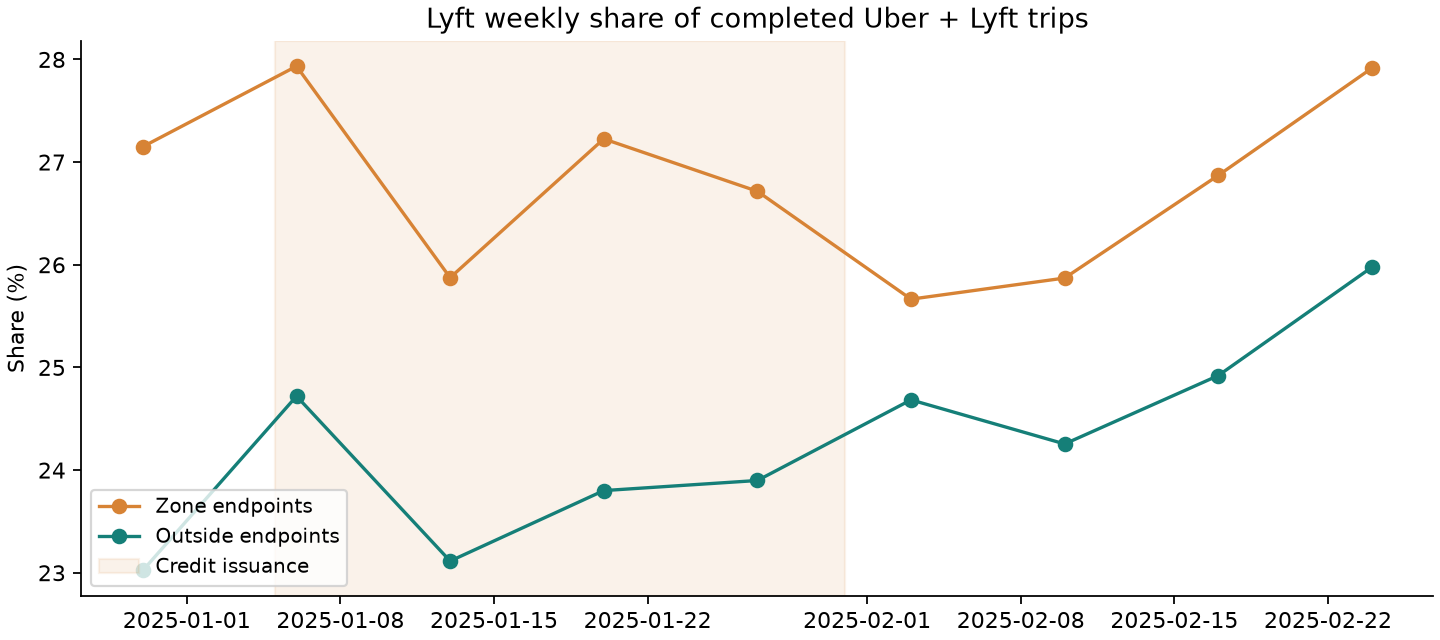

In [44]:
display(lyft_weekly)
display(credit_periods[["period", "touches_zone", "days", "holiday_days", "lyft_trips", "uber_trips", "market_trips", "lyft_share"]])
display(credit_sensitivity[["comparison", "credit_days", "post_days", "share_difference_percentage_points", "approx_uplift_vs_post_share", "fixed_market_uplift_proxy"]])
print(f"Chênh lệch share: {credit_summary['share_difference_percentage_points']:+.3f} điểm %.")
print(f"Uplift quy đổi: {credit_summary['approx_uplift_vs_post_share']:.2%}; proxy thị trường cố định: {credit_summary['fixed_market_uplift_proxy']:.2%}.")
print(f"Volume từ January sang February trong vùng: Lyft {credit_summary['lyft_zone_volume_change_post_vs_credit']:+.2%}, Uber {credit_summary['uber_zone_volume_change_post_vs_credit']:+.2%}, tổng {credit_summary['market_zone_volume_change_post_vs_credit']:+.2%}.")
from IPython.display import Image, Markdown
display(Image(filename=str(ROOT / "reports/lyft_share_weekly.png")))

### Tự tính 100 chuyến nền và đọc kịch bản
Với uplift 3%, có 103 credit × $1,50 = $154,50; chỉ ba chuyến tăng thêm nên chi phí/chuyến tăng thêm = $51,50. Với m=$6 và redemption=100%, hòa vốn đại trà = 33,33%. Trợ giá 30% chuyến nền đưa ngưỡng về 10% toàn mẫu, tương đương 33,33% trên chuyến nền đủ điều kiện.

Kết quả dùng uplift quy đổi quan sát cho kịch bản, không phải ROI đã đo của chiến dịch. Các dòng coverage=30% giữ uplift chỉ để so cơ học chi phí; không dự đoán hiệu quả targeting.

In [45]:
display(pd.read_csv(ROOT / "data/processed/credit_economics_hand_examples.csv"))
display(credit_scenarios[["margin_usd", "coverage", "redemption", "credit_cost_usd", "net_incremental_contribution_usd", "cost_per_incremental_trip_usd", "breakeven_global_uplift", "breakeven_eligible_uplift"]])
default_credit = credit_economics(uplift=credit_summary["approx_uplift_vs_post_share"])
print(f"Kịch bản mặc định: chi phí/chuyến thêm ${default_credit['cost_per_incremental_trip_usd']:.2f}; net contribution ${default_credit['net_incremental_contribution_usd']:.2f}/100 chuyến nền.")

,example,base_trips,uplift,credit_usd,margin_usd,coverage,redemption,incremental_credit_fraction,effective_credit_usd,incremental_trips,credits_issued,credits_redeemed,credit_cost_usd,incremental_contribution_usd,net_incremental_contribution_usd,cost_per_incremental_trip_usd,breakeven_global_uplift,breakeven_eligible_uplift,uplift_denominator
0,100_base_3pct_uplift,100,0.03,1.5,6,1.0,1,1,1.5,3.0,103.0,103.0,154.5,18.0,-136.5,51.5,0.333333,0.333333,All base trips; eligible-population threshold ...
1,targeted_30pct_10pct_global_uplift,100,0.10,1.5,6,0.3,1,1,1.5,10.0,40.0,40.0,60.0,60.0,0.0,6.0,0.100000,0.333333,All base trips; eligible-population threshold ...


,margin_usd,coverage,redemption,credit_cost_usd,net_incremental_contribution_usd,cost_per_incremental_trip_usd,breakeven_global_uplift,breakeven_eligible_uplift
0,3,1.0,0.25,39.807321,-21.348752,6.469730,0.142857,0.142857
1,3,0.3,0.25,13.557321,4.901248,2.203419,0.042857,0.142857
2,3,1.0,0.50,79.614642,-61.156073,12.939460,0.333333,0.333333
3,3,0.3,0.50,27.114642,-8.656073,4.406838,0.100000,0.333333
4,3,1.0,0.75,119.421964,-100.963394,19.409191,0.600000,0.600000
5,3,0.3,0.75,40.671964,-22.213394,6.610257,0.180000,0.600000
6,3,1.0,1.00,159.229285,-140.770715,25.878921,1.000000,1.000000
7,3,0.3,1.00,54.229285,-35.770715,8.813676,0.300000,1.000000
8,6,1.0,0.25,39.807321,-2.890182,6.469730,0.066667,0.066667
9,6,0.3,0.25,13.557321,23.359818,2.203419,0.020000,0.066667


Kịch bản mặc định: chi phí/chuyến thêm $25.88; net contribution $-122.31/100 chuyến nền.


### Thiết kế lần chạy tiếp theo
Randomize 90% treatment / 10% holdout theo khách đủ điều kiện, xác định eligibility bằng lịch sử trước thử nghiệm. KPI chuyến/khách bao gồm người không đi chuyến nào. Chạy ít nhất 14 ngày và theo dõi redemption thêm đủ bảy ngày. Định nghĩa contribution, sample size và ngưỡng guardrail phải chốt trước khi chạy; không suy ra từ TLC rằng thử nghiệm đã diễn ra.

In [46]:
display(Markdown((ROOT / "docs/targeted_credit_experiment_brief.md").read_text()))

# Campaign brief - Targeted congestion credit test

**Hypothesis.** Offering a $1.50 future-ride credit to eligible users with a pre-test history of short, low-fare zone trips increases contribution at lower organic-trip subsidy cost than blanket issuance.

**Eligibility and assignment.** Define eligibility from the preceding 28 days before assignment; do not classify users from post-treatment fares or trips. Randomly assign 90% of eligible users to treatment and 10% to holdout. Keep assignment stable per user. The public TLC data has no user IDs, so this is a proposed design, not an executed test or generated targeting list. Trip coverage s=30% is an assumption to validate, not 30% of users.

**Primary metric.** Zone trips per assigned eligible user, including zero-trip users, analyzed by intention to treat. Uplift is (treatment rate/control rate)-1 on the eligible-user denominator. Also measure all Lyft trips per user to detect displacement outside the zone. Do not compare eligible-user uplift directly with a whole-market 10% threshold.

**Economics and guardrails.** Measure actual credit issued/redeemed and contribution using approved internal cost definitions. Primary economic outcome: incremental contribution per assigned user after redeemed-credit cost. Guardrails: waiting time, cancellation rate and contribution per trip. Marketplace spillovers may affect the holdout; random assignment reduces confounding but does not remove every interference assumption. Margin/redemption/cancellation metrics require internal platform data.

**Duration and sample.** At least 14 issuance days for two of every weekday, plus a redemption follow-up covering the seven-day credit validity and issuance timing. Final duration and user count come from a power calculation using pre-test variance and a prespecified minimum detectable effect; public aggregate TLC data cannot supply a defensible sample-size calculation.

**Decision.** Before launch, agree sample size, guardrail limits, contribution definition and a fixed analysis date. Expand only if the confidence interval for incremental net contribution supports a positive effect and guardrails remain within agreed limits; otherwise do not expand and stop or redesign the campaign. Under m=$6, c=$1.50, redemption=100%, and all extra trips credited, the illustrative break-even is 33.33% eligible uplift. If eligible baseline trips are 30% of all baseline trips, that equals 10% whole-base uplift. Recompute the threshold from measured margin/redemption; do not treat either number as an unconditional launch rule.

This brief is a design deliverable. No live campaign, customer messaging or account changes were made.


## Dự báo tuần có lễ: 17-23/02/2025
Mục tiêu là 28 dự báo = bảy ngày × bốn phân khúc, đo chuyến hoàn thành. Chốt thông tin tới hết 16/02 theo giờ New York; không dùng actual tuần test, uplift credit hồi cứu hoặc thời tiết thực tế tương lai để tạo tham số. Không thêm machine learning.

B1 lấy cùng thứ tuần trước; B2 lấy trung bình hai tuần; B3 dùng B2 và chỉ điều chỉnh 17/02 bằng hệ số MLK. Chọn trước B2 làm baseline kế hoạch vì bớt phụ thuộc một ngày bất thường, giữ B3 làm kịch bản lễ. Phương án có WAPE thấp nhất sau test được nêu riêng và không diễn giải là đã biết ở cutoff.

### Dựng history chỉ gồm chuyến đã hoàn thành ở cutoff
Các nguồn tháng TLC là dữ liệu hồi cứu; mô phỏng giả định record và bảng zone đã có tại cutoff, không khẳng định TLC cung cấp realtime feed. Bảng ngày theo request có thể chứa chuyến hoàn thành sau nửa đêm. Vì vậy, SQL đọc hai raw Parquet bằng DuckDB, giữ request từ 01/01 tới 16/02 và dropoff trước 00:00 ngày 17/02. Chuyến chưa hoàn thành/thiếu dropoff bị loại khỏi history dự báo; không sửa raw hoặc bảng ngày hồi cứu.

Nhãn zone đã được suy từ 05-31/01, nằm trước cutoff. Lịch lễ 17/02 là thông tin lịch biết trước, không phải quan sát tương lai. Chỉ điền 0 trong grid history khi bảng nguồn có coverage; thiếu coverage phải dừng. Lưu provenance và chênh lệch so bảng ngày để kiểm tra.

In [47]:
FORECAST_HISTORY_SQL = """
CREATE OR REPLACE TEMP VIEW forecast_source AS
SELECT r.request_datetime, r.dropoff_datetime,
    CAST(r.request_datetime AS DATE) AS request_date,
    CASE WHEN r.hvfhs_license_num = 'HV0003' THEN 'Uber'
         WHEN r.hvfhs_license_num = 'HV0005' THEN 'Lyft' END AS operator,
    CASE WHEN crz_pu.LocationID IS NOT NULL OR crz_do.LocationID IS NOT NULL
         THEN true ELSE false END AS touches_zone
FROM forecast_raw r
JOIN known_zones pu ON r.PULocationID = pu.LocationID
JOIN known_zones do_zone ON r.DOLocationID = do_zone.LocationID
LEFT JOIN forecast_zones crz_pu ON r.PULocationID = crz_pu.LocationID
LEFT JOIN forecast_zones crz_do ON r.DOLocationID = crz_do.LocationID
WHERE r.request_datetime >= TIMESTAMP '2025-01-01'
  AND r.request_datetime < TIMESTAMP '2025-02-17'
  AND r.hvfhs_license_num IN ('HV0003', 'HV0005')
"""


def prepare_forecast_history(root):
    root = Path(root)
    cutoff = pd.Timestamp("2025-02-16")
    end_exclusive = pd.Timestamp("2025-02-17")
    daily = pd.read_csv(root / "data/processed/daily_segment.csv", parse_dates=["request_date"])
    expected = daily[daily.request_date.between("2025-01-01", cutoff)].copy()
    keys = ["request_date", "operator", "touches_zone"]
    grid = pd.MultiIndex.from_product([pd.date_range("2025-01-01", cutoff), ["Uber", "Lyft"], [False, True]], names=keys)
    actual_keys = pd.MultiIndex.from_frame(expected[keys])
    if actual_keys.has_duplicates or len(grid.difference(actual_keys)) or len(expected) != len(grid) or not expected.data_available.all():
        raise ValueError("Forecast history needs complete observed source coverage.")
    parameters = json.loads((root / "docs/trip_processing_parameters.json").read_text())
    if max(pd.Timestamp(x) for x in parameters["zone_inference_dates"]) > cutoff:
        raise ValueError("Forecast zone calibration extends beyond cutoff.")
    zones = pd.read_csv(root / "data/external/taxi_zone_lookup.csv")
    calendar = pd.read_csv(root / "data/external/holidays.csv", parse_dates=["date"])
    if not {pd.Timestamp("2025-01-20"), pd.Timestamp("2025-02-17")}.issubset(set(calendar.date)):
        raise ValueError("The planned MLK and Presidents' Day dates are missing from the holiday calendar.")
    crz = pd.read_csv(root / "data/processed/crz_zones.csv")
    con = duckdb.connect()
    con.execute("SET threads=4")
    con.execute("SET memory_limit='2GB'")
    con.execute("SET temp_directory='" + str(root / ".analysis-cache/forecast_spill").replace("'", "''") + "'")
    files = [str(root / f"data/raw/fhvhv_tripdata_{month}.parquet") for month in ["2025-01", "2025-02"]]
    con.read_parquet(files, union_by_name=True).create_view("forecast_raw")
    con.register("known_zones", zones.loc[zones.LocationID.ne(264), ["LocationID"]])
    con.register("forecast_zones", crz[["LocationID"]])
    con.execute(FORECAST_HISTORY_SQL)
    history = con.execute("""
        SELECT request_date, operator, touches_zone, COUNT(*) AS trips
        FROM forecast_source
        WHERE dropoff_datetime < TIMESTAMP '2025-02-17'
        GROUP BY request_date, operator, touches_zone
        ORDER BY request_date, operator, touches_zone
    """).df()
    deferred = con.execute("""
        SELECT request_date, operator, touches_zone,
            SUM(CASE WHEN dropoff_datetime >= TIMESTAMP '2025-02-17' THEN 1 ELSE 0 END) AS completed_after_cutoff,
            SUM(CASE WHEN dropoff_datetime IS NULL THEN 1 ELSE 0 END) AS completion_time_missing
        FROM forecast_source
        GROUP BY request_date, operator, touches_zone
    """).df()
    latest = con.execute("""
        SELECT MAX(request_datetime) AS latest_request, MAX(dropoff_datetime) AS latest_completion
        FROM forecast_source WHERE dropoff_datetime < TIMESTAMP '2025-02-17'
    """).df().iloc[0]
    con.close()
    history = expected[keys].merge(history, on=keys, how="left", validate="one_to_one")
    history["trips"] = history.trips.fillna(0).astype("int64")
    history["cutoff_date"] = cutoff
    reconciliation = expected[keys + ["trips"]].rename(columns={"trips": "final_retrospective_trips"}).merge(
        history[keys + ["trips"]].rename(columns={"trips": "known_completed_trips"}), on=keys, validate="one_to_one").merge(deferred, on=keys, validate="one_to_one")
    reconciliation["difference"] = reconciliation.final_retrospective_trips - reconciliation.known_completed_trips
    if not reconciliation.difference.eq(reconciliation.completed_after_cutoff + reconciliation.completion_time_missing).all():
        raise ValueError("Cutoff reconstruction does not reconcile with final daily counts.")
    if pd.Timestamp(latest.latest_request) >= end_exclusive or pd.Timestamp(latest.latest_completion) >= end_exclusive:
        raise ValueError("History contains a request or completion after cutoff.")
    history.to_csv(root / "data/processed/forecast_history.csv", index=False)
    reconciliation.to_csv(root / "data/processed/forecast_cutoff_reconciliation.csv", index=False)
    provenance = {"cutoff_date": "2025-02-16", "cutoff_timezone": "America/New_York",
                  "end_exclusive": "2025-02-17T00:00:00", "latest_request": str(latest.latest_request),
                  "latest_completion": str(latest.latest_completion), "history_rows": len(history),
                  "zone_calibration_dates": parameters["zone_inference_dates"],
                  "known_calendar_dates": ["2025-01-20", "2025-02-17"],
                  "calendar_note": "Scheduled holiday dates can be known before cutoff; they are not future trip or weather observations.",
                  "completed_after_cutoff_excluded": int(reconciliation.completed_after_cutoff.sum()),
                  "completion_time_missing_excluded": int(reconciliation.completion_time_missing.sum()),
                  "availability_assumption": "Historical simulation assumes trip records and the static zone lookup are accessible at cutoff. TLC monthly releases are retrospective, not a live feed.",
                  "unused_inputs": ["credit uplift", "weather factors", "future weather observations", "backtest scores", "fare thresholds"]}
    (root / "docs/forecast_input_provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")
    (root / "sql/reconstruct_forecast_history.sql").write_text(FORECAST_HISTORY_SQL.strip() + ";\n")
    return history, provenance

### Ba baseline và nguồn tham số
Với ngày D và cùng phân khúc: B1 = trips(D-7), B2 = [trips(D-7) + trips(D-14)]/2. Hệ số MLK = trips(20/01) / {[trips(13/01) + trips(27/01)]/2}. B3 = B2 × hệ số chỉ ngày 17/02; các ngày khác giữ B2.

Không làm tròn trước scoring. Mọi ngày nguồn được lưu theo từng dự báo; thiếu nguồn hoặc reference không dương được báo lỗi. Hàm lọc history tới cutoff ngay khi bắt đầu, nên volume tương lai không thay đổi forecast.

In [48]:
def build_holiday_forecasts(history):
    cutoff = pd.Timestamp("2025-02-16")
    history = history[history.request_date.le(cutoff)].copy()
    keys = ["request_date", "operator", "touches_zone"]
    if history.duplicated(keys).any() or history.trips.isna().any() or (history.trips < 0).any():
        raise ValueError("Forecast history must have unique keys and nonnegative observed trips.")
    counts = history.set_index(keys).trips
    rows, factors, lineage = [], [], []
    for operator in ["Uber", "Lyft"]:
        for touches in [False, True]:
            def observed(date):
                key = (pd.Timestamp(date), operator, touches)
                if key not in counts.index:
                    raise ValueError(f"Missing forecast reference: {key}")
                return float(counts.loc[key])
            mlk, before, after = [observed(date) for date in ["2025-01-20", "2025-01-13", "2025-01-27"]]
            reference = (before + after) / 2
            if reference <= 0:
                raise ValueError("Holiday factor requires a positive reference volume.")
            factor = mlk / reference
            factors.append({"operator": operator, "touches_zone": touches, "holiday_date": "2025-01-20",
                            "reference_before": "2025-01-13", "reference_after": "2025-01-27",
                            "holiday_trips": mlk, "before_trips": before, "after_trips": after,
                            "reference_trips": reference, "holiday_factor": factor, "cutoff_date": "2025-02-16"})
            for date in pd.date_range("2025-02-17", "2025-02-23"):
                d7, d14 = date - pd.Timedelta(days=7), date - pd.Timedelta(days=14)
                b1 = observed(d7)
                b2 = (b1 + observed(d14)) / 2
                applied = factor if date == pd.Timestamp("2025-02-17") else 1.0
                rows.append({"request_date": date, "operator": operator, "touches_zone": touches,
                             "cutoff_date": cutoff, "is_target_holiday": date == pd.Timestamp("2025-02-17"),
                             "d7_date": d7, "d14_date": d14, "B1": b1, "B2": b2, "B3": b2 * applied,
                             "applied_holiday_factor": applied, "planning_method": "B2"})
                for source, role in [(d7, "D-7"), (d14, "D-14")]:
                    lineage.append({"forecast_date": date, "operator": operator, "touches_zone": touches,
                                    "source_date": source, "role": role})
                if date == pd.Timestamp("2025-02-17"):
                    for source, role in [("2025-01-13", "MLK reference before"), ("2025-01-20", "MLK holiday"), ("2025-01-27", "MLK reference after")]:
                        lineage.append({"forecast_date": date, "operator": operator, "touches_zone": touches,
                                        "source_date": pd.Timestamp(source), "role": role})
    forecast = pd.DataFrame(rows).sort_values(keys).reset_index(drop=True)
    return forecast, pd.DataFrame(factors), pd.DataFrame(lineage)

### Chấm điểm sau khi lưu forecast
Forecast chỉ có dự báo và ngày nguồn, được lưu cùng memo trước khi actual được nối. Bảng evaluation riêng chứa actual và lỗi. MAE = trung bình |forecast-actual|; WAPE = tổng |lỗi| / tổng actual; bias = tổng (forecast-actual) / tổng actual. Bias dương là dự báo cao hơn thực tế.

Tính toàn tuần, riêng ngày lễ, ngày thường và mỗi phân khúc. WAPE toàn mẫu dùng 28 sai số, không lấy trung bình WAPE nhóm hay để lỗi trái dấu triệt tiêu. Khi tổng actual=0, giữ WAPE/bias unavailable.

In [49]:
def forecast_metrics(actual, prediction):
    errors = prediction - actual
    denominator = float(actual.sum())
    return {"observations": len(actual), "actual_trips": denominator, "forecast_trips": float(prediction.sum()),
            "absolute_error_trips": float(errors.abs().sum()), "signed_error_trips": float(errors.sum()),
            "MAE": float(errors.abs().mean()), "WAPE": float(errors.abs().sum() / denominator) if denominator > 0 else None,
            "bias": float(errors.sum() / denominator) if denominator > 0 else None}


def score_holiday_forecasts(forecast, daily):
    keys = ["request_date", "operator", "touches_zone"]
    actual = daily[daily.request_date.between("2025-02-17", "2025-02-23")].copy()
    if actual.duplicated(keys).any() or not actual.data_available.all():
        raise ValueError("Backtest actuals have duplicate keys or missing coverage.")
    evaluation = forecast.merge(actual[keys + ["trips"]].rename(columns={"trips": "actual_trips"}),
                                on=keys, how="left", validate="one_to_one")
    if len(evaluation) != 28 or evaluation.actual_trips.isna().any():
        raise ValueError("Backtest needs all 28 actual observations.")
    records = []
    for scope in ["week", "holiday", "ordinary_days"]:
        subset = evaluation if scope == "week" else evaluation[evaluation.is_target_holiday.eq(scope == "holiday")]
        groups = [("All", "All", subset)] + [(op, str(bool(zone)), frame) for (op, zone), frame in subset.groupby(["operator", "touches_zone"])]
        for operator, zone, frame in groups:
            for method in ["B1", "B2", "B3"]:
                records.append({"scope": scope, "operator": operator, "touches_zone": zone, "method": method,
                                **forecast_metrics(frame.actual_trips, frame[method])})
    scores = pd.DataFrame(records)
    for method in ["B1", "B2", "B3"]:
        evaluation[f"{method}_error"] = evaluation[method] - evaluation.actual_trips
        evaluation[f"{method}_absolute_error"] = evaluation[f"{method}_error"].abs()
    return evaluation, scores

### Memo kế hoạch, báo cáo hồi cứu và đối chiếu
Memo tại 16/02 chỉ đọc forecast và giả định đã biết. Báo cáo hồi cứu có bảng điểm và kết luận sau tuần test. Hash forecast được kiểm tra sau ghép actual; đối chiếu một dự báo và MAE/WAPE/bias bằng phép tính trực tiếp. Thử thêm volume rất lớn sau cutoff và bỏ một ngày nguồn để xác nhận chống leakage và phát hiện thiếu dữ liệu.

Thời tiết là contingency vận hành định tính: chuẩn bị theo dõi mưa/tuyết và thời gian chờ khi có forecast thời tiết hợp lệ. Không nhân hệ số mưa mùa hè vào tuần tháng 02, không đọc thời tiết actual tương lai để cải thiện baseline. B2/B3 là các kịch bản, không phải prediction interval.

In [50]:
def write_cutoff_planning_memo(root, forecast, factors):
    totals = forecast.groupby("request_date")[["B1", "B2", "B3"]].sum()
    lines = ["# Holiday-week operating plan", "", "**Information cutoff: end of 16 February 2025, New York time.**", "",
             "Forecast completed Uber + Lyft trips for 17-23 February, split by operator and zone endpoints. This is a historical planning simulation, assuming cutoff trip records are accessible; TLC monthly releases are not a live feed.", "",
             "## Planning choice", "", "Use B2, the mean of the two preceding same-weekday observations, as the provisional planning baseline. This choice is fixed before test actuals are joined: averaging reduces reliance on a single unusual day. It has not been shown to win the upcoming test week.", "",
             "B3 is a holiday scenario for 17 February only: apply each segment's MLK factor from 20 January versus the mean of 13 and 27 January. One MLK observation does not establish Presidents' Day behavior; keep B2 and B3 visible to show this assumption's effect. B1 is the reference based on the preceding week.", "",
             "| Date | B2 planning trips | B3 holiday scenario |", "|---|---:|---:|"]
    for date, row in totals.iterrows():
        lines.append(f"| {date:%Y-%m-%d} | {row.B2:,.0f} | {row.B3:,.0f} |")
    lines += ["", f"B2 total: {totals.B2.sum():,.0f} completed trips. B3 scenario total: {totals.B3.sum():,.0f}. Fractional forecasts are retained for scoring; table display is rounded.",
              "", "## Operations and limits", "",
              "Review staffing readiness and pickup waiting times around the holiday, without converting trip forecasts into a driver count. If a weather forecast becomes available, prepare rain/snow contingency actions; future observed weather and summer rain factors are excluded from these forecasts. B2/B3 differences are scenarios, not a statistical prediction interval.",
              "", "Zone membership is calibrated on 5-31 January, before cutoff. History excludes trips completed after cutoff or lacking a completion time. No February credit uplift, test actuals, or retrospective weather coefficients enter this memo. Refresh with newly available observations during operations and evaluate accuracy in a separate retrospective report.", ""]
    (Path(root) / "docs/holiday_week_planning_memo.md").write_text("\n".join(lines))


def plot_holiday_forecasts(root, evaluation):
    root = Path(root)
    os.environ.setdefault("MPLCONFIGDIR", str(root / ".mpl-cache"))
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
    for ax, ((operator, zone), frame) in zip(axes.flat, evaluation.groupby(["operator", "touches_zone"])):
        ax.plot(frame.request_date, frame.actual_trips / 1000, color="#222222", marker="o", linewidth=2, label="Actual")
        for method, color, style in [("B1", "#9b6a38", ":"), ("B2", "#197f8c", "--"), ("B3", "#7257a5", "-")]:
            ax.plot(frame.request_date, frame[method] / 1000, color=color, linestyle=style, marker=".", label=method)
        ax.set_title(f"{operator} | {'Zone endpoints' if zone else 'Outside endpoints'}")
        ax.set_ylabel("Completed trips (thousands)")
        ax.set_xticks(frame.request_date, [date.strftime("%d/%m") for date in frame.request_date])
        ax.spines[["top", "right"]].set_visible(False)
    axes[0, 0].legend(ncol=4, fontsize=9)
    fig.suptitle("Holiday-week retrospective: 17-23 February 2025\nForecast information cutoff: 16 February; B3 differs from B2 only on 17 February", fontsize=12)
    fig.savefig(root / "reports/holiday_week_forecast.png", dpi=160)
    plt.close(fig)


def write_forecast_report(root, scores, factors, provenance, winner):
    total = scores[(scores.operator == "All") & (scores.scope == "week")]
    holiday = scores[(scores.operator == "All") & (scores.scope == "holiday")]
    lines = ["# Dự báo tuần có lễ: kết quả hồi cứu", "", "Dự báo 17-23/02/2025, cutoff hết 16/02 theo giờ New York. B2 được chọn trước làm baseline kế hoạch; B3 là kịch bản lễ. Phương án thắng dưới đây chỉ được biết sau tuần kiểm thử.", "",
             "## Ba cách dự báo", "", "B1=D-7. B2=trung bình D-7 và D-14. B3=B2×hệ số MLK riêng ngày 17/02; sáu ngày còn lại bằng B2. Hệ số riêng từng hãng/nhãn vùng = chuyến 20/01 chia trung bình 13/01 và 27/01. Không thêm machine learning hoặc chỉnh hệ số theo test.", "",
             "## Điểm toàn tuần", "", "| Cách | MAE (chuyến/ô ngày × phân khúc) | WAPE | Bias |", "|---|---:|---:|---:|"]
    for row in total.itertuples():
        lines.append(f"| {row.method} | {row.MAE:,.2f} | {row.WAPE:.2%} | {row.bias:+.2%} |")
    lines += ["", f"Phương án có WAPE thấp nhất hồi cứu: **{winner}**. Đây là kết luận của một tuần kiểm thử, không phải quyết định đã biết tại cutoff hoặc bằng chứng tổng quát cho mọi tuần có lễ.",
              "", "## Riêng ngày lễ", "", "| Cách | MAE (chuyến/phân khúc) | WAPE | Bias |", "|---|---:|---:|---:|"]
    for row in holiday.itertuples():
        lines.append(f"| {row.method} | {row.MAE:,.2f} | {row.WAPE:.2%} | {row.bias:+.2%} |")
    lines += ["", "Bảng điểm đầy đủ gồm toàn tuần, ngày lễ, ngày thường và từng phân khúc. WAPE toàn mẫu = tổng sai số tuyệt đối của 28 ô / tổng actual, không phải trung bình WAPE các phân khúc. Bias dương là dự báo cao, âm là dự báo thấp.",
              "", "## Đọc kết quả theo phân khúc", "", "| Hãng | Chạm vùng | WAPE B1 | WAPE B2 | WAPE B3 |", "|---|---|---:|---:|---:|"]
    segment_week = scores[(scores.operator != "All") & (scores.scope == "week")]
    for (operator, zone), frame in segment_week.groupby(["operator", "touches_zone"]):
        values = frame.set_index("method").WAPE
        lines.append(f"| {operator} | {zone} | {values.B1:.2%} | {values.B2:.2%} | {values.B3:.2%} |")
    b2_wape = total.set_index("method").loc["B2", "WAPE"]
    b3_wape = total.set_index("method").loc["B3", "WAPE"]
    lines += ["", f"Chênh lệch WAPE B3 trừ B2 là {(b3_wape - b2_wape) * 100:+.3f} điểm %. Toàn bộ khác biệt dự báo nằm ở 17/02. Hệ số MLK gồm cả nhóm tăng và giảm, không giả định mọi phân khúc giảm trong ngày lễ. Đọc bảng phân khúc trước khi quyết định dùng hệ số chung; kết quả một tuần chưa đủ xác nhận mô hình tốt nhất ổn định.",
              "", "## Hệ số MLK", "", "| Hãng | Chạm vùng | Chuyến MLK | Reference trung bình | Hệ số |", "|---|---|---:|---:|---:|"]
    for row in factors.itertuples():
        lines.append(f"| {row.operator} | {row.touches_zone} | {row.holiday_trips:,.0f} | {row.reference_trips:,.1f} | {row.holiday_factor:.4f} |")
    lines += ["", "## Cutoff và giới hạn", "",
              f"History chỉ giữ request từ 01/01 tới 16/02 và dropoff trước 00:00 ngày 17/02. Loại {provenance['completed_after_cutoff_excluded']:,} chuyến hoàn thành sau cutoff, {provenance['completion_time_missing_excluded']:,} chuyến thiếu thời điểm hoàn thành. Đối chiếu các chênh lệch với bảng ngày hồi cứu riêng, không sửa bảng ngày hoặc raw.",
              "Forecast và memo được ghi xuống đĩa trước khi ghép actual; hash forecast được kiểm tra sau scoring. Các tham số dùng tháng 01, không dùng kết quả credit tới 23/02 hoặc thời tiết thực tế tương lai. Bộ kiểm tra còn thay đổi mọi volume sau cutoff để xác nhận dự báo giữ nguyên.",
              "Đây là mô phỏng lịch sử với giả định dữ liệu chuyến đã có ở cutoff; TLC công bố theo tháng sau kỳ dữ liệu, không cung cấp feed dự báo realtime. Ngày lễ khác nhau, thời tiết, xu hướng và sự kiện đặc biệt có thể làm MLK không đại diện cho Presidents' Day. B2/B3 không tạo khoảng tin cậy. Chỉ đo nhu cầu được phục vụ, không đo booking bị hủy hoặc số tài xế.",
              "", "Memo kế hoạch tại cutoff: holiday_week_planning_memo.md. Đầu ra: forecast_week.csv, forecast_evaluation.csv, forecast_scores.csv, forecast_holiday_factors.csv, forecast_source_dates.csv và biểu đồ holiday_week_forecast.png.", ""]
    (Path(root) / "docs/holiday_week_forecast_report.md").write_text("\n".join(lines))


def validate_holiday_forecast(root, history, forecast, factors, lineage, evaluation, scores, provenance, frozen_hash):
    root = Path(root)
    keys = ["request_date", "operator", "touches_zone"]
    sample = evaluation.iloc[0]
    count = history.set_index(keys).trips
    d7 = float(count.loc[(sample.d7_date, sample.operator, sample.touches_zone)])
    d14 = float(count.loc[(sample.d14_date, sample.operator, sample.touches_zone)])
    h, before, after = [float(count.loc[(pd.Timestamp(date), sample.operator, sample.touches_zone)]) for date in ["2025-01-20", "2025-01-13", "2025-01-27"]]
    hand_b3 = (d7 + d14) / 2 * h / ((before + after) / 2)
    total = scores[(scores.operator == "All") & (scores.scope == "week") & (scores.method == "B3")].iloc[0]
    absolute = sum(abs(row.B3 - row.actual_trips) for row in evaluation.itertuples())
    actual_total = sum(row.actual_trips for row in evaluation.itertuples())
    signed = sum(row.B3 - row.actual_trips for row in evaluation.itertuples())
    noisy_future = pd.DataFrame([{"request_date": date, "operator": op, "touches_zone": zone, "trips": 999999999} for date in pd.date_range("2025-02-17", "2025-02-28") for op in ["Uber", "Lyft"] for zone in [False, True]])
    unchanged, _, _ = build_holiday_forecasts(pd.concat([history, noisy_future], ignore_index=True))
    missing_rejected = False
    try:
        build_holiday_forecasts(history[~((history.request_date == pd.Timestamp("2025-02-03")) & history.operator.eq("Uber") & ~history.touches_zone)])
    except ValueError:
        missing_rejected = True
    checks = {
        "twenty_eight_unique_keys": len(forecast) == 28 and not forecast.duplicated(keys).any(),
        "reference_dates_before_cutoff": lineage.source_date.le(pd.Timestamp("2025-02-16")).all(),
        "history_completed_before_cutoff": pd.Timestamp(provenance["latest_completion"]) < pd.Timestamp("2025-02-17"),
        "zone_calibration_before_cutoff": max(pd.Timestamp(x) for x in provenance["zone_calibration_dates"]) <= pd.Timestamp("2025-02-16"),
        "four_holiday_factors": len(factors) == 4 and not factors.duplicated(["operator", "touches_zone"]).any(),
        "six_ordinary_days_equal": forecast.loc[~forecast.is_target_holiday, "B2"].equals(forecast.loc[~forecast.is_target_holiday, "B3"]),
        "hand_forecast_matches": math.isclose(sample.B1, d7) and math.isclose(sample.B2, (d7 + d14) / 2) and math.isclose(sample.B3, hand_b3),
        "hand_MAE_matches": math.isclose(total.MAE, absolute / 28),
        "pooled_WAPE_matches": math.isclose(total.WAPE, absolute / actual_total),
        "pooled_bias_matches": math.isclose(total.bias, signed / actual_total, abs_tol=1e-12),
        "future_volume_cannot_change_forecast": forecast.equals(unchanged),
        "missing_reference_rejected": missing_rejected,
        "forecast_file_unchanged_after_scoring": hashlib.sha256((root / "data/processed/forecast_week.csv").read_bytes()).hexdigest() == frozen_hash,
        "scores_cover_scopes_and_segments": len(scores) == 45,
        "zero_actual_denominator_unavailable": forecast_metrics(pd.Series([0.]), pd.Series([1.]))["WAPE"] is None,
    }
    spot = {"request_date": str(sample.request_date.date()), "operator": sample.operator, "touches_zone": bool(sample.touches_zone),
            "D7_trips": d7, "D14_trips": d14, "MLK_trips": h, "MLK_before_trips": before, "MLK_after_trips": after,
            "B1": sample.B1, "B2": sample.B2, "B3": sample.B3, "hand_B3": hand_b3, "actual_trips": int(sample.actual_trips),
            "pooled_B3_absolute_error": absolute, "pooled_actual_trips": actual_total, "pooled_B3_signed_error": signed,
            "hand_MAE": absolute / 28, "hand_WAPE": absolute / actual_total, "hand_bias": signed / actual_total}
    pd.DataFrame([spot]).to_csv(root / "data/processed/forecast_spot_check.csv", index=False)
    payload = {"checked_at_utc": datetime.now(timezone.utc).isoformat(), "valid": bool(all(checks.values())),
               "checks": {key: bool(value) for key, value in checks.items()}, "forecast_rows": len(forecast), "score_rows": len(scores)}
    (root / "docs/holiday_week_forecast_validation.json").write_text(json.dumps(payload, indent=2) + "\n")
    if not payload["valid"]:
        raise ValueError(f"Forecast reconciliation failed: {checks}")


def forecast_holiday_week(root):
    root = Path(root)
    for folder in ["data/processed", "docs", "sql", "reports", ".analysis-cache"]:
        (root / folder).mkdir(parents=True, exist_ok=True)
    history, provenance = prepare_forecast_history(root)
    forecast, factors, lineage = build_holiday_forecasts(history)
    forecast.to_csv(root / "data/processed/forecast_week.csv", index=False)
    factors.to_csv(root / "data/processed/forecast_holiday_factors.csv", index=False)
    lineage.to_csv(root / "data/processed/forecast_source_dates.csv", index=False)
    write_cutoff_planning_memo(root, forecast, factors)
    frozen_hash = hashlib.sha256((root / "data/processed/forecast_week.csv").read_bytes()).hexdigest()
    daily = pd.read_csv(root / "data/processed/daily_segment.csv", parse_dates=["request_date"])
    evaluation, scores = score_holiday_forecasts(forecast, daily)
    evaluation.to_csv(root / "data/processed/forecast_evaluation.csv", index=False)
    scores.to_csv(root / "data/processed/forecast_scores.csv", index=False)
    all_week = scores[(scores.operator == "All") & (scores.scope == "week")]
    winner = all_week.sort_values(["WAPE", "method"]).iloc[0].method
    validate_holiday_forecast(root, history, forecast, factors, lineage, evaluation, scores, provenance, frozen_hash)
    plot_holiday_forecasts(root, evaluation)
    write_forecast_report(root, scores, factors, provenance, winner)
    summary = {"created_at_utc": datetime.now(timezone.utc).isoformat(), "cutoff_date": "2025-02-16",
               "target_window": ["2025-02-17", "2025-02-23"], "planning_method_at_cutoff": "B2",
               "planning_reason": "Prespecified same-weekday two-week mean; MLK transfer retained as a scenario, not selected using test scores.",
               "retrospective_lowest_WAPE_method": winner, "week_scores": all_week.to_dict("records"),
               "forecast_sha256_before_actual_join": frozen_hash, "forecast_frozen_before_actual_join": True,
               "parameters_use_future_actuals": False, "weather_adjustment_used": False,
               "availability_assumption": provenance["availability_assumption"]}
    (root / "docs/holiday_week_forecast_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
    print(f"Forecast frozen: {len(forecast)} rows. Planning method B2; retrospective lowest WAPE: {winner}.")
    return forecast, evaluation, scores, factors, history

In [51]:
holiday_forecast, holiday_evaluation, holiday_scores, holiday_factors, forecast_history = forecast_holiday_week(ROOT)

Forecast frozen: 28 rows. Planning method B2; retrospective lowest WAPE: B2.


### Tham số, cutoff và bảng dự báo
Xem chênh lệch do thời điểm hoàn thành trước khi đọc kết quả dự báo. Hệ số ngày lễ dựa trên một MLK quan sát cho mỗi phân khúc; nó có thể lớn hơn hoặc nhỏ hơn 1, không ép mọi nhóm giảm.

In [52]:
display(holiday_factors)
cutoff_comparison = pd.read_csv(ROOT / "data/processed/forecast_cutoff_reconciliation.csv")
display(cutoff_comparison[cutoff_comparison.difference.ne(0)])
display(holiday_forecast[["request_date", "operator", "touches_zone", "d7_date", "d14_date", "B1", "B2", "B3", "planning_method"]])

,operator,touches_zone,holiday_date,reference_before,reference_after,holiday_trips,before_trips,after_trips,reference_trips,holiday_factor,cutoff_date
0,Uber,False,2025-01-20,2025-01-13,2025-01-27,304115.0,294470.0,302283.0,298376.5,1.019232,2025-02-16
1,Uber,True,2025-01-20,2025-01-13,2025-01-27,130001.0,142729.0,132243.0,137486.0,0.945558,2025-02-16
2,Lyft,False,2025-01-20,2025-01-13,2025-01-27,88770.0,88171.0,90233.0,89202.0,0.995157,2025-02-16
3,Lyft,True,2025-01-20,2025-01-13,2025-01-27,46991.0,47944.0,46318.0,47131.0,0.997030,2025-02-16


,request_date,operator,touches_zone,final_retrospective_trips,known_completed_trips,completed_after_cutoff,completion_time_missing,difference
184,2025-02-16,Lyft,False,109488,107883,1605.0,0.0,1605
185,2025-02-16,Lyft,True,62419,61529,890.0,0.0,890
186,2025-02-16,Uber,False,347172,342112,5060.0,0.0,5060
187,2025-02-16,Uber,True,174130,171724,2406.0,0.0,2406


,request_date,operator,touches_zone,d7_date,d14_date,B1,B2,B3,planning_method
0,2025-02-17,Lyft,False,2025-02-10,2025-02-03,99643.0,97409.5,96937.751564,B2
1,2025-02-17,Lyft,True,2025-02-10,2025-02-03,49627.0,47312.0,47171.462350,B2
2,2025-02-17,Uber,False,2025-02-10,2025-02-03,315465.0,305049.0,310915.828274,B2
3,2025-02-17,Uber,True,2025-02-10,2025-02-03,146297.0,141846.5,134124.106065,B2
4,2025-02-18,Lyft,False,2025-02-11,2025-02-04,98037.0,95884.0,95884.000000,B2
5,2025-02-18,Lyft,True,2025-02-11,2025-02-04,53733.0,51703.5,51703.500000,B2
6,2025-02-18,Uber,False,2025-02-11,2025-02-04,316427.0,311767.0,311767.000000,B2
7,2025-02-18,Uber,True,2025-02-11,2025-02-04,167811.0,164158.0,164158.000000,B2
8,2025-02-19,Lyft,False,2025-02-12,2025-02-05,104437.0,104560.0,104560.000000,B2
9,2025-02-19,Lyft,True,2025-02-12,2025-02-05,56582.0,57453.0,57453.000000,B2


### Kế hoạch được lập trước khi ghép actual
Tài liệu dưới không chứa kết quả tuần test hoặc phương án thắng hồi cứu. Forecast trong memo vẫn dùng B2 đã chọn trước; kịch bản lễ B3 được đọc riêng.

In [53]:
display(Markdown((ROOT / "docs/holiday_week_planning_memo.md").read_text()))

# Holiday-week operating plan

**Information cutoff: end of 16 February 2025, New York time.**

Forecast completed Uber + Lyft trips for 17-23 February, split by operator and zone endpoints. This is a historical planning simulation, assuming cutoff trip records are accessible; TLC monthly releases are not a live feed.

## Planning choice

Use B2, the mean of the two preceding same-weekday observations, as the provisional planning baseline. This choice is fixed before test actuals are joined: averaging reduces reliance on a single unusual day. It has not been shown to win the upcoming test week.

B3 is a holiday scenario for 17 February only: apply each segment's MLK factor from 20 January versus the mean of 13 and 27 January. One MLK observation does not establish Presidents' Day behavior; keep B2 and B3 visible to show this assumption's effect. B1 is the reference based on the preceding week.

| Date | B2 planning trips | B3 holiday scenario |
|---|---:|---:|
| 2025-02-17 | 591,617 | 589,149 |
| 2025-02-18 | 623,512 | 623,512 |
| 2025-02-19 | 662,746 | 662,746 |
| 2025-02-20 | 712,804 | 712,804 |
| 2025-02-21 | 793,364 | 793,364 |
| 2025-02-22 | 799,268 | 799,268 |
| 2025-02-23 | 688,156 | 688,156 |

B2 total: 4,871,468 completed trips. B3 scenario total: 4,869,000. Fractional forecasts are retained for scoring; table display is rounded.

## Operations and limits

Review staffing readiness and pickup waiting times around the holiday, without converting trip forecasts into a driver count. If a weather forecast becomes available, prepare rain/snow contingency actions; future observed weather and summer rain factors are excluded from these forecasts. B2/B3 differences are scenarios, not a statistical prediction interval.

Zone membership is calibrated on 5-31 January, before cutoff. History excludes trips completed after cutoff or lacking a completion time. No February credit uplift, test actuals, or retrospective weather coefficients enter this memo. Refresh with newly available observations during operations and evaluate accuracy in a separate retrospective report.


### Đánh giá hồi cứu và giới hạn
So bảng điểm với actual sau khi dự báo đã chốt. Nếu B3 không thắng, giữ kết quả đó. Một tuần kiểm thử và một MLK không đủ chứng minh hiệu quả ổn định hoặc tác động nhân quả của lễ; không gọi các kịch bản là khoảng tin cậy.

In [54]:
display(holiday_scores[holiday_scores.operator.eq("All")][["scope", "method", "observations", "MAE", "WAPE", "bias"]])
display(holiday_scores[holiday_scores.scope.eq("week") & holiday_scores.operator.ne("All")][["operator", "touches_zone", "method", "MAE", "WAPE", "bias"]])
forecast_summary = json.loads((ROOT / "docs/holiday_week_forecast_summary.json").read_text())
print(f"Baseline kế hoạch tại cutoff: {forecast_summary['planning_method_at_cutoff']}; WAPE thấp nhất hồi cứu: {forecast_summary['retrospective_lowest_WAPE_method']}.")

,scope,method,observations,MAE,WAPE,bias
0,week,B1,28,7660.107143,0.044497,0.027274
1,week,B2,28,5998.196429,0.034843,0.010649
2,week,B3,28,6219.571725,0.036129,0.010137
15,holiday,B1,4,5311.500000,0.035981,0.034806
16,holiday,B2,4,2084.500000,0.014121,0.001926
17,holiday,B3,4,3634.127074,0.024618,-0.002254
30,ordinary_days,B1,24,8051.541667,0.045686,0.026223
31,ordinary_days,B2,24,6650.479167,0.037736,0.011866
32,ordinary_days,B3,24,6650.479167,0.037736,0.011866


,operator,touches_zone,method,MAE,WAPE,bias
3,Lyft,False,B1,4568.714286,0.040221,0.003840
4,Lyft,False,B2,4129.071429,0.036350,-0.013567
5,Lyft,False,B3,4196.464062,0.036943,-0.014160
6,Lyft,True,B1,3752.571429,0.059994,-0.018788
7,Lyft,True,B2,3635.214286,0.058118,-0.019992
8,Lyft,True,B3,3655.291093,0.058439,-0.020313
9,Uber,False,B1,14035.428571,0.041013,0.040526
10,Uber,False,B2,8691.642857,0.025398,0.010962
11,Uber,False,B3,9529.761182,0.027847,0.013411
12,Uber,True,B1,8283.714286,0.048662,0.033196


Baseline kế hoạch tại cutoff: B2; WAPE thấp nhất hồi cứu: B2.


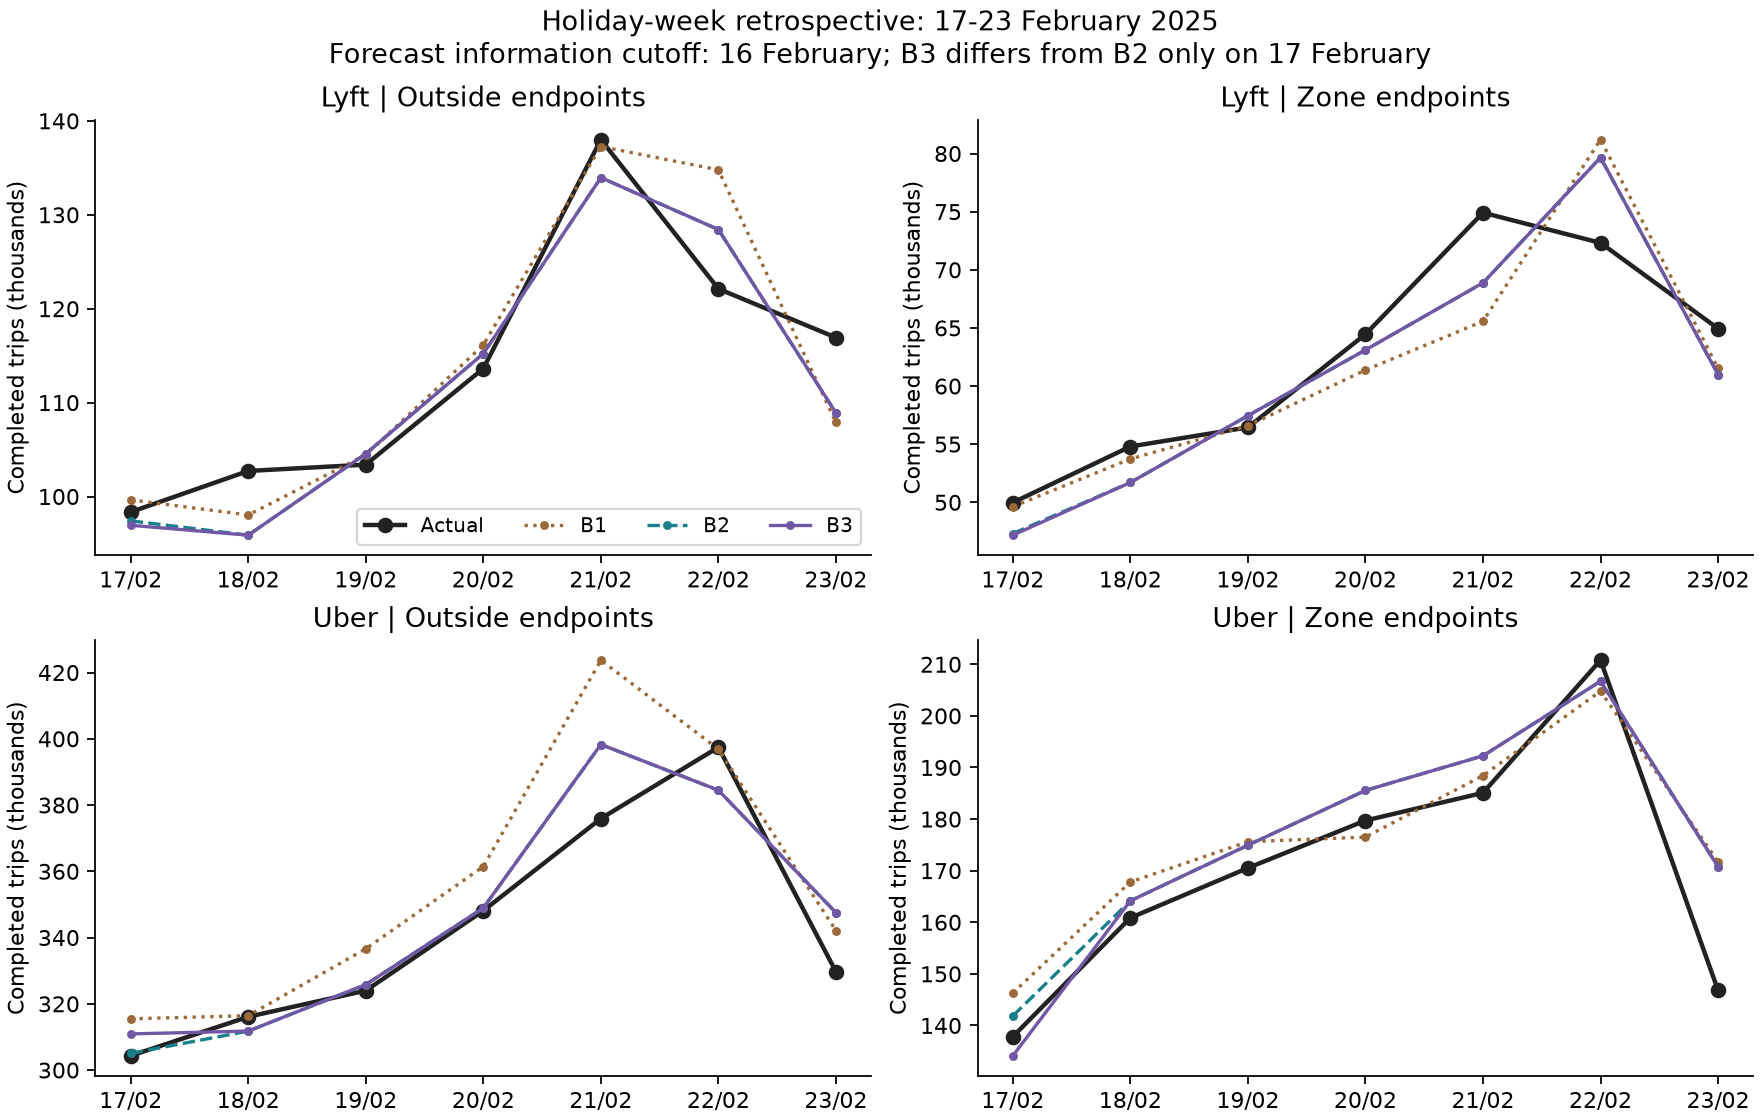

In [55]:
display(Image(filename=str(ROOT / "reports/holiday_week_forecast.png")))

### Tự tính một dự báo và ba metric
Dòng dưới cung cấp D-7, D-14, ba ngày tính hệ số MLK và tổng lỗi/actual thật. Tính lại B3 rồi MAE/WAPE/bias từ các tử số, mẫu số đã lưu; không dùng số minh họa làm kết quả.

In [56]:
display(pd.read_csv(ROOT / "data/processed/forecast_spot_check.csv"))

,request_date,operator,touches_zone,D7_trips,D14_trips,MLK_trips,MLK_before_trips,MLK_after_trips,B1,B2,B3,hand_B3,actual_trips,pooled_B3_absolute_error,pooled_actual_trips,pooled_B3_signed_error,hand_MAE,hand_WAPE,hand_bias
0,2025-02-17,Lyft,False,99643.0,95176.0,88770.0,88171.0,90233.0,99643.0,97409.5,96937.751564,96937.751564,98348,174148.008295,4820140,48859.648253,6219.571725,0.036129,0.010137


## Báo cáo và đóng gói kết quả
Hai trang trả lời hai câu hỏi: biến động chuyến và thời tiết; giá, credit và kế hoạch tuần. Mọi số được lấy từ đầu ra đã tạo trong notebook. Calendar liên tục 01/01/2024-28/02/2025, bốn phân khúc và ba phương án dự báo có dimension riêng.

Bảng thời tiết theo giờ là toàn thành phố; không có khóa hãng/vùng. Hệ số mùa hè là mẫu riêng, không đổi theo ngày tháng 01. Forecast plan không chứa actual; bảng evaluation có ba method và chỉ được cộng actual một lần cho một method. Các mô hình/ảnh được ghi đúng trạng thái local preview cho tới khi mở và kiểm tra Power BI native.

In [57]:
def reporting_segment_key(operator, zone):
    return operator + ("_zone" if zone else "_outside")


def prepare_report_tables(root):
    root = Path(root)
    out = root / "powerbi/data"
    out.mkdir(parents=True, exist_ok=True)
    daily = pd.read_csv(root / "data/processed/daily_segment.csv", parse_dates=["request_date"])
    hourly = pd.read_csv(root / "data/processed/hourly_city.csv", parse_dates=["request_date", "request_hour"])
    alerts = pd.read_csv(root / "data/processed/watchlist.csv", parse_dates=["request_date"])
    forecast = pd.read_csv(root / "data/processed/forecast_evaluation.csv", parse_dates=["request_date"])
    plan = pd.read_csv(root / "data/processed/forecast_week.csv", parse_dates=["request_date"])
    fee = pd.read_csv(root / "data/processed/fee_effect.csv")
    weekly = pd.read_csv(root / "data/processed/lyft_share_weekly.csv", parse_dates=["week_start"])
    weather = pd.read_csv(root / "data/processed/rain_factors.csv")
    credit = json.loads((root / "docs/lyft_credit_analysis.json").read_text())
    holidays = pd.read_csv(root / "data/external/holidays.csv", parse_dates=["date"])
    dates = pd.DataFrame({"Date": pd.date_range("2024-01-01", "2025-02-28")})
    dates["Year"] = dates.Date.dt.year
    dates["Month"] = dates.Date.dt.month
    dates["YearMonth"] = dates.Date.dt.strftime("%Y-%m")
    dates["Weekday"] = dates.Date.dt.dayofweek
    dates["DayName"] = dates.Date.dt.strftime("%a")
    dates["HolidayName"] = dates.Date.map(holidays.set_index("date").holiday_name)
    dates["IsHoliday"] = dates.HolidayName.notna()
    dates["HasTripSource"] = dates.Date.isin(daily.request_date)
    segments = pd.DataFrame([{"SegmentKey": reporting_segment_key(op, zone), "Operator": op,
                              "TouchesZone": zone, "SegmentLabel": f"{op} / {'zone endpoints' if zone else 'outside endpoints'}"}
                             for op in ["Uber", "Lyft"] for zone in [False, True]])
    def segmented(frame):
        result = frame.copy()
        result["SegmentKey"] = [reporting_segment_key(op, zone) for op, zone in zip(result.operator, result.touches_zone)]
        return result
    daily = segmented(daily)
    alerts = segmented(alerts)
    forecast = segmented(forecast)
    plan = segmented(plan)
    facts = {
        "DimDate": dates,
        "DimSegment": segments,
        "DimMethod": pd.DataFrame({"Method": ["B1", "B2", "B3"], "SortOrder": [1, 2, 3]}),
        "DimHour": pd.DataFrame({"Hour": range(24)}),
        "DimFeeOperator": pd.DataFrame({"FeeOperator": ["All", "Uber", "Lyft"]}),
        "DimTripGroup": pd.DataFrame({"TripGroup": ["all_trips", "short_trips", "low_fare_trips"]}),
        "DimZone": pd.DataFrame({"TouchesZone": [False, True], "ZoneLabel": ["Outside endpoints", "Zone endpoints"]}),
        "FactDaily": daily[["request_date", "SegmentKey", "trips", "short_trips", "low_fare_trips", "valid_economics_trips", "total_base_fare", "total_driver_pay", "median_wait_minutes"]].rename(columns={"request_date": "Date", "trips": "Trips", "short_trips": "ShortTrips", "low_fare_trips": "LowFareTrips", "valid_economics_trips": "ValidEconomicsTrips", "total_base_fare": "BaseFareSum", "total_driver_pay": "DriverPaySum", "median_wait_minutes": "MedianWaitMinutes"}),
        "FactCityHourly": hourly[["request_date", "request_hour", "hour", "trips", "median_wait_minutes", "rain_mm", "snowfall_cm", "temperature_c"]].rename(columns={"request_date": "Date", "request_hour": "DateTime", "hour": "Hour", "trips": "Trips", "median_wait_minutes": "MedianWaitMinutes", "rain_mm": "RainMM", "snowfall_cm": "SnowCM", "temperature_c": "TemperatureC"}),
        "FactAlerts": alerts[["request_date", "SegmentKey", "trips_deviation", "wait_deviation", "trigger", "next_step", "investigation_status"]].rename(columns={"request_date": "Date", "trips_deviation": "TripsDeviation", "wait_deviation": "WaitDeviation", "trigger": "Trigger", "next_step": "NextStep", "investigation_status": "Status"}),
        "FactPlan": plan[["request_date", "SegmentKey", "B1", "B2", "B3"]].rename(columns={"request_date": "Date"}),
        "FactFeeEffect": fee[["operator", "trip_group", "relative_growth_gap", "estimated_trip_difference", "scaled_total_gap"]].rename(columns={"operator": "FeeOperator", "trip_group": "TripGroup", "relative_growth_gap": "RelativeGrowthGap", "estimated_trip_difference": "EstimatedTripDifference", "scaled_total_gap": "ScaledTotalGap"}),
        "FactWeeklyShare": weekly[weekly.full_week][["week_start", "touches_zone", "lyft_trips", "market_trips", "lyft_share"]].rename(columns={"week_start": "Date", "touches_zone": "TouchesZone", "lyft_trips": "LyftTrips", "market_trips": "MarketTrips", "lyft_share": "LyftShare"}),
        "FactWeatherFactors": weather[["study", "weather_group", "usable_trip_hours", "usable_days", "wet_events", "trips_factor", "wait_factor", "trip_sample_under_20_hours"]].rename(columns={"study": "Study", "weather_group": "WeatherGroup", "usable_trip_hours": "Hours", "usable_days": "Days", "wet_events": "Events", "trips_factor": "TripsFactor", "wait_factor": "WaitFactor", "trip_sample_under_20_hours": "LowSample"}),
    }
    rows = []
    for method in ["B1", "B2", "B3"]:
        frame = forecast[["request_date", "SegmentKey", "actual_trips", method, f"{method}_absolute_error", f"{method}_error"]].copy()
        frame.columns = ["Date", "SegmentKey", "ActualTrips", "ForecastTrips", "AbsoluteErrorTrips", "SignedErrorTrips"]
        frame["Method"] = method
        rows.append(frame)
    facts["FactForecast"] = pd.concat(rows, ignore_index=True)
    facts["FactCreditSummary"] = pd.DataFrame([{"ShareGapPP": credit["comparison"]["share_difference_percentage_points"],
                                                "UpliftProxy": credit["comparison"]["approx_uplift_vs_post_share"],
                                                "CostPerExtraTrip": credit["default_economics"]["cost_per_incremental_trip_usd"],
                                                "MarginAssumption": 6.0, "RedemptionAssumption": 1.0}])
    contract = []
    for name, frame in facts.items():
        frame.to_csv(out / f"{name}.csv", index=False, date_format="%Y-%m-%d %H:%M:%S")
        types = {}
        for column in frame:
            dtype = frame[column].dtype
            types[column] = "dateTime" if pd.api.types.is_datetime64_any_dtype(dtype) else "boolean" if pd.api.types.is_bool_dtype(dtype) else "int64" if pd.api.types.is_integer_dtype(dtype) else "double" if pd.api.types.is_float_dtype(dtype) else "string"
        contract.append({"table": name, "csv": f"data/{name}.csv", "rows": len(frame), "columns": types})
    (root / "powerbi/data_contract.json").write_text(json.dumps(contract, indent=2) + "\n")
    return facts


def report_kpis(facts, start="2025-01-06", end="2025-01-26", segment_keys=None):
    daily = facts["FactDaily"]
    selected_dates = pd.date_range(start, end)
    selected = daily[daily.Date.isin(selected_dates)]
    if segment_keys is not None:
        selected = selected[selected.SegmentKey.isin(segment_keys)]
    prior = daily[daily.Date.isin(selected_dates - pd.Timedelta(days=364))]
    if segment_keys is not None:
        prior = prior[prior.SegmentKey.isin(segment_keys)]
    prior_total = float(prior.Trips.sum()) if prior.Date.nunique() == len(selected_dates) else None
    zones = facts["DimSegment"].set_index("SegmentKey").TouchesZone
    selected_zones = zones.loc[selected.SegmentKey.unique()].unique()
    market_keys = facts["DimSegment"].loc[facts["DimSegment"].TouchesZone.isin(selected_zones), "SegmentKey"]
    market = daily[daily.Date.isin(selected_dates) & daily.SegmentKey.isin(market_keys)]
    alerts = facts["FactAlerts"][facts["FactAlerts"].Date.isin(selected_dates)]
    if segment_keys is not None:
        alerts = alerts[alerts.SegmentKey.isin(segment_keys)]
    return {"trips": int(selected.Trips.sum()), "prior_trips": prior_total,
            "year_on_year": float(selected.Trips.sum() / prior_total - 1) if prior_total else None,
            "lyft_share": float(market.loc[market.SegmentKey.str.startswith("Lyft"), "Trips"].sum() / market.Trips.sum()) if market.Trips.sum() else None,
            "alert_rows": len(alerts)}


def validate_report_pack(root, facts):
    root = Path(root)
    daily = pd.read_csv(root / "data/processed/daily_segment.csv", parse_dates=["request_date"])
    hourly = pd.read_csv(root / "data/processed/hourly_city.csv")
    scores = pd.read_csv(root / "data/processed/forecast_scores.csv")
    single = report_kpis(facts, "2025-01-21", "2025-01-21", ["Lyft_zone"])
    original = daily[daily.request_date.eq("2025-01-21") & daily.operator.eq("Lyft") & daily.touches_zone].iloc[0]
    forecast = facts["FactForecast"]
    checks = {"continuous_date_dimension": len(facts["DimDate"]) == 425 and facts["DimDate"].Date.is_unique,
              "four_unique_segments": len(facts["DimSegment"]) == 4 and facts["DimSegment"].SegmentKey.is_unique,
              "daily_total_matches_source": int(facts["FactDaily"].Trips.sum()) == int(daily.trips.sum()),
              "city_hour_total_matches_source": int(facts["FactCityHourly"].Trips.sum()) == int(hourly.trips.sum()),
              "single_date_segment_matches": single["trips"] == int(original.trips),
              "all_daily_keys_unique": not facts["FactDaily"].duplicated(["Date", "SegmentKey"]).any(),
              "weather_has_no_segment_key": "SegmentKey" not in facts["FactCityHourly"] and "SegmentKey" not in facts["FactWeatherFactors"],
              "only_full_share_weeks": len(facts["FactWeeklyShare"]) == 14,
              "missing_prior_year_is_unavailable": report_kpis(facts, "2025-02-17", "2025-02-23")["year_on_year"] is None,
              "forecast_keys_unique": len(forecast) == 84 and not forecast.duplicated(["Date", "SegmentKey", "Method"]).any(),
              "plan_has_no_actual": "ActualTrips" not in facts["FactPlan"] and len(facts["FactPlan"]) == 28}
    for method in ["B1", "B2", "B3"]:
        frame = forecast[forecast.Method.eq(method)]
        expected = scores[scores.scope.eq("week") & scores.operator.eq("All") & scores.method.eq(method)].iloc[0]
        checks[f"{method}_WAPE_matches_source"] = math.isclose(frame.AbsoluteErrorTrips.sum() / frame.ActualTrips.sum(), expected.WAPE, rel_tol=1e-10)
    daily_dates = set(facts["DimDate"].Date)
    segments = set(facts["DimSegment"].SegmentKey)
    checks["foreign_keys_match_dimensions"] = all(("Date" not in frame or set(frame.Date).issubset(daily_dates)) and ("SegmentKey" not in frame or set(frame.SegmentKey).issubset(segments)) for frame in facts.values())
    checks["operator_slicer_does_not_change_share_market"] = math.isclose(report_kpis(facts, segment_keys=["Uber_zone"])["lyft_share"], report_kpis(facts, segment_keys=["Lyft_zone"])["lyft_share"], rel_tol=1e-12)
    pd.DataFrame([{"check": "all_retained_trips", "expected": int(daily.trips.sum()), "actual": int(facts["FactDaily"].Trips.sum())},
                  {"check": "2025-01-21_Lyft_zone", "expected": int(original.trips), "actual": single["trips"]}]).to_csv(root / "data/processed/report_reconciliation.csv", index=False)
    result = {"checked_at_utc": datetime.now(timezone.utc).isoformat(), "valid": bool(all(checks.values())),
              "checks": {k: bool(v) for k, v in checks.items()}, "default_filters": {"start": "2025-01-06", "end": "2025-01-26"},
              "default_kpis": report_kpis(facts), "native_powerbi_tested": False,
              "evidence": "Local source reconciliation and filter semantics; native DAX and visual interactions require Power BI validation."}
    (root / "docs/reporting_pack_validation.json").write_text(json.dumps(result, indent=2) + "\n")
    if not result["valid"]:
        raise ValueError(f"Report inputs failed reconciliation: {checks}")
    return result

### Memo tại cutoff và bản đọc hồi cứu
Memo ngày 16/02 lấy kế hoạch B2/B3, so phí trong tháng 01 và share Lyft tháng 01. Không chứa hiệu quả credit dựa trên tháng 02 hoặc điểm forecast test. Bản đọc hồi cứu riêng chứa những kết quả đó. Mỗi claim số trong memo có source/selection và cờ biết được tại cutoff.

In [58]:
def write_portfolio_memos(root, facts):
    root = Path(root)
    plan = facts["FactPlan"].groupby("Date")[["B2", "B3"]].sum()
    fee = facts["FactFeeEffect"]
    pooled = fee[fee.FeeOperator.eq("All") & fee.TripGroup.eq("all_trips")].iloc[0]
    jan = facts["FactDaily"][facts["FactDaily"].Date.between("2025-01-06", "2025-01-26")]
    zone = jan[jan.SegmentKey.str.endswith("_zone")]
    share = zone.loc[zone.SegmentKey.eq("Lyft_zone"), "Trips"].sum() / zone.Trips.sum()
    memo = ["# January Review and Feb 17-23 Demand Plan", "", "**Decision time: end of 16 February 2025, New York. Historical planning simulation.**", "",
            f"Plan **{plan.B2.sum():,.0f} completed Uber + Lyft trips** for 17-23 February using the two-week same-weekday mean (B2). Treat the MLK adjustment as a holiday scenario, not a proven improvement.", "",
            "## Evidence available at cutoff", "",
            f"In the matched January windows, zone-touching volume was {abs(pooled.RelativeGrowthGap):.2%} below its comparison-based counterfactual. This is an observational relative gap, not an identified causal fee effect. Outside-zone trips can be affected by spillovers and through-zone fees.",
            f"Lyft had {share:.2%} of completed Uber + Lyft zone trips in 6-26 January. Its $1.50 offer was future credit, not cash reimbursement. Redemption and campaign incrementality are unmeasured; the January-February share estimate is excluded because it uses data after this decision time.", "",
            "## Plan and action", "",
            f"Use B2 as the provisional baseline, fixed before evaluation. The B3 holiday scenario totals {plan.B3.sum():,.0f} trips and changes only 17 February. Keep the segment forecasts visible; the four MLK responses differ.",
            "Prepare pickup-time monitoring and rain/snow contingency actions. Summer rain coefficients are not February forecast multipliers. No future observed weather or test-week accuracy is used in this plan.",
            "Design a targeted $1.50 future-credit experiment with 10% randomized holdout, at least 14 issuance days and redemption follow-up. Decide using measured incremental net contribution per assigned user and guardrails. With assumed $6 contribution and full redemption, break-even is 33.33% uplift on eligible baseline trips; a whole-base 10% threshold requires 30% baseline-trip coverage and a compatible denominator.", "",
            "## What remains unknown", "",
            "Completed trips exclude failed/cancelled requests. Driver supply, true margin, redemption, retention and causal incrementality are not observed. This simulation assumes trip records were available at cutoff; public TLC monthly releases are retrospective. B2/B3 scenarios are not prediction intervals.", ""]
    (root / "docs/mobility_planning_memo.md").write_text("\n".join(memo))
    credit = facts["FactCreditSummary"].iloc[0]
    evaluation = facts["FactForecast"]
    review = ["# Retrospective evidence and learning", "", "**Includes trip outcomes through 23 February 2025. Separate from the 16 February planning memo.**", "",
              f"January fee comparison: relative zone gap {pooled.RelativeGrowthGap:+.2%}; observational assumptions remain unverified.",
              f"Credit comparison: adjusted Lyft share gap {credit.ShareGapPP:+.3f} percentage points; uplift proxy {credit.UpliftProxy:.2%}. Under $6 margin and 100% redemption assumptions, expected credit cost per extra trip is ${credit.CostPerExtraTrip:.2f}; this is not observed campaign ROI.", "",
              "| Method | Weekly WAPE | Weekly bias |", "|---|---:|---:|"]
    for method, frame in evaluation.groupby("Method"):
        review.append(f"| {method} | {frame.AbsoluteErrorTrips.sum() / frame.ActualTrips.sum():.2%} | {frame.SignedErrorTrips.sum() / frame.ActualTrips.sum():+.2%} |")
    review += ["", "B2 has the lowest WAPE in this test week. MLK adjustment improves Uber zone endpoints slightly, but worsens the other groups. One test week does not establish an enduring winner.", "",
               "Summer heavy-rain coefficients describe city-wide observed association, not causal demand or driver availability. Use them in the separate weather study; do not apply them to February planning.", ""]
    (root / "docs/mobility_retrospective_review.md").write_text("\n".join(review))
    claims = [{"claim": "planned_week_trips_B2", "value": float(plan.B2.sum()), "source": "data/processed/forecast_week.csv", "selection": "sum B2, 2025-02-17 through 2025-02-23", "known_at_cutoff": True},
              {"claim": "holiday_scenario_week_trips_B3", "value": float(plan.B3.sum()), "source": "data/processed/forecast_week.csv", "selection": "sum B3", "known_at_cutoff": True},
              {"claim": "January_relative_zone_gap", "value": float(pooled.RelativeGrowthGap), "source": "data/processed/fee_effect.csv", "selection": "operator=All, trip_group=all_trips", "known_at_cutoff": True},
              {"claim": "January_Lyft_zone_share", "value": float(share), "source": "data/processed/daily_segment.csv", "selection": "2025-01-06 through 2025-01-26, touches_zone=True", "known_at_cutoff": True},
              {"claim": "credit_cost_per_extra_trip_scenario", "value": float(credit.CostPerExtraTrip), "source": "docs/lyft_credit_analysis.json", "selection": "default_economics.cost_per_incremental_trip_usd; retrospective review only", "known_at_cutoff": False},
              {"claim": "illustrative_eligible_breakeven", "value": 1 / 3, "source": "data/processed/credit_economics_hand_examples.csv", "selection": "targeted example, breakeven_eligible_uplift; assumed economics, independent of observed uplift", "known_at_cutoff": True},
              {"claim": "illustrative_whole_base_breakeven", "value": .1, "source": "data/processed/credit_economics_hand_examples.csv", "selection": "targeted example, breakeven_global_uplift; assumed economics", "known_at_cutoff": True},
              {"claim": "assumed_trip_coverage", "value": .3, "source": "data/processed/credit_economics_hand_examples.csv", "selection": "targeted example, coverage; assumption", "known_at_cutoff": True},
              {"claim": "assumed_contribution_per_trip", "value": 6.0, "source": "data/processed/credit_economics_hand_examples.csv", "selection": "margin_usd; assumption, not observed margin", "known_at_cutoff": True},
              {"claim": "credit_face_value", "value": 1.5, "source": "data/processed/credit_economics_hand_examples.csv", "selection": "credit_usd; program face value", "known_at_cutoff": True},
              {"claim": "proposed_holdout_share", "value": .1, "source": "docs/targeted_credit_experiment_brief.md", "selection": "Eligibility and assignment; proposed design, not executed test", "known_at_cutoff": True},
              {"claim": "proposed_issuance_days_minimum", "value": 14, "source": "docs/targeted_credit_experiment_brief.md", "selection": "Duration and sample; proposed design", "known_at_cutoff": True}]
    pd.DataFrame(claims).to_csv(root / "data/processed/memo_claim_sources.csv", index=False)


def render_report_previews(root, facts):
    root = Path(root)
    os.environ.setdefault("MPLCONFIGDIR", str(root / ".mpl-cache"))
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from matplotlib.ticker import FuncFormatter
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
    dark, teal, orange, purple = "#18394b", "#217f85", "#c87336", "#7861a2"
    def canvas(title, subtitle):
        fig = plt.figure(figsize=(16, 9), facecolor="#f3f6f8")
        fig.text(.045, .94, title, fontsize=23, fontweight="bold", color=dark)
        fig.text(.045, .905, subtitle, fontsize=11, color="#536571")
        fig.text(.045, .025, "Local report preview from verified CSV | Power BI native rendering and filters pending", fontsize=9, color="#536571")
        return fig
    def card(fig, x, title, value, detail):
        ax = fig.add_axes([x, .745, .21, .12], facecolor="white", zorder=5)
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values(): spine.set_visible(False)
        ax.text(.06, .79, title, transform=ax.transAxes, color="#536571", fontsize=10)
        ax.text(.06, .32, value, transform=ax.transAxes, color=dark, fontsize=22, fontweight="bold")
        ax.text(.06, .07, detail, transform=ax.transAxes, color="#536571", fontsize=8)
    metrics = report_kpis(facts)
    fig = canvas("Demand monitoring and weather", "6-26 January 2025 | All four segments | Matched weekday comparison: 8-28 January 2024")
    for x, title, value, detail in [(.045, "Completed trips", f"{metrics['trips']/1e6:.3f}M", "Observed served demand"), (.285, "Same-weekday change", f"{metrics['year_on_year']:+.2%}", "D-364; all reference days available"), (.525, "Lyft market share", f"{metrics['lyft_share']:.2%}", "Uber + Lyft denominator"), (.765, "Alert rows", str(metrics['alert_rows']), "Date x segment; not unique dates")]:
        card(fig, x, title, value, detail)
    daily = facts["FactDaily"][facts["FactDaily"].Date.between("2025-01-06", "2025-01-26")]
    ax = fig.add_axes([.07, .38, .42, .30], facecolor="white")
    colors = [teal, orange, purple, "#637c9e"]
    for (segment, frame), color in zip(daily.groupby("SegmentKey"), colors):
        ax.plot(frame.Date, frame.Trips/1000, color=color, label=segment.replace("_", " / "))
    ax.set_title("Daily completed trips by segment", loc="left", color=dark)
    ax.set_ylabel("Thousands"); ax.legend(ncol=2, fontsize=8, frameon=False)
    ax.tick_params(axis="x", labelsize=8)
    city = facts["FactCityHourly"][facts["FactCityHourly"].Date.between("2025-01-06", "2025-01-26")].copy()
    city["Weekday"] = city.Date.dt.dayofweek
    heat = city.groupby(["Weekday", "Hour"]).Trips.mean().unstack("Hour")
    ax = fig.add_axes([.57, .40, .35, .25], facecolor="white")
    im = ax.imshow(heat/1000, aspect="auto", cmap="YlGnBu")
    ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
    ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("New York hour")
    ax.set_title("City-wide average trips per hour", loc="left", color=dark)
    fig.colorbar(im, ax=ax, fraction=.025, pad=.02, label="Thousands")
    fig.text(.57, .33, "City-wide grain: unaffected by operator / zone slicers", fontsize=9, color="#536571")
    ax = fig.add_axes([.07, .095, .59, .205], facecolor="white"); ax.axis("off")
    ax.set_title("Alerts to investigate | completed review does not establish root cause", loc="left", color=dark, fontsize=11)
    alerts = facts["FactAlerts"][facts["FactAlerts"].Date.between("2025-01-06", "2025-01-26")].copy()
    alerts["Magnitude"] = alerts.TripsDeviation.abs()
    alerts = alerts.sort_values("Magnitude", ascending=False).head(5)
    rows = [[r.Date.strftime("%d Jan"), r.SegmentKey.replace("_", " / "), f"{r.TripsDeviation:+.1%}", f"{r.WaitDeviation:+.1%}", r.Status.replace("_", " ")] for r in alerts.itertuples()]
    table = ax.table(cellText=rows, colLabels=["Date", "Segment", "Trips", "Wait", "Status"], colWidths=[.11, .22, .11, .11, .39], loc="center", cellLoc="left")
    table.auto_set_font_size(False); table.set_fontsize(9); table.scale(1, 1.5)
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("#edf1f4"); cell.set_facecolor("#e3ebef" if row == 0 else "white")
    rain = facts["FactWeatherFactors"]
    heavy = rain[rain.Study.eq("summer_2024") & rain.WeatherGroup.eq("moderate_or_heavy_rain")].iloc[0]
    fig.text(.715, .28, "Separate summer weather study", color=dark, fontweight="bold", fontsize=12)
    fig.text(.715, .23, f"Heavy rain: trips x{heavy.TripsFactor:.3f}\nWait x{heavy.WaitFactor:.3f} | {int(heavy.Hours)} hours", color=teal, fontsize=13, linespacing=1.5)
    fig.text(.715, .125, "June-August 2024, city-wide association.\nSmall event sample; no causal claim.\nDo not transfer this factor to February.", fontsize=9, color="#536571", linespacing=1.5)
    fig.savefig(root / "reports/demand_monitoring_preview.png", dpi=140)
    plt.close(fig)
    fig = canvas("Price, credit and the holiday-week plan", "Retrospective comparisons and a separately frozen 16 February plan | Observed proxies, not causal campaign ROI")
    fee = facts["FactFeeEffect"]
    all_fee = fee[fee.FeeOperator.eq("All") & fee.TripGroup.eq("all_trips")].iloc[0]
    credit = facts["FactCreditSummary"].iloc[0]
    plan = facts["FactPlan"].groupby("Date")[["B2", "B3"]].sum()
    for x, title, value, detail in [(.045, "Relative zone volume gap", f"{all_fee.RelativeGrowthGap:+.2%}", "Matched January comparison"), (.285, "Adjusted Lyft share gap", f"{credit.ShareGapPP:+.3f} pp", "Jan vs Feb; retrospective"), (.525, "Credit cost / extra trip", f"${credit.CostPerExtraTrip:.2f}", "Assumed $6 margin; 100% redemption"), (.765, "B2 planned week", f"{plan.B2.sum()/1e6:.3f}M", "Frozen cutoff: 16 February")]:
        card(fig, x, title, value, detail)
    ax = fig.add_axes([.08, .39, .23, .29], facecolor="white")
    sample = fee[fee.FeeOperator.eq("All")]
    ax.barh(["All trips", "Short trips", "Low fare"], sample.RelativeGrowthGap*100, color=[teal, orange, purple])
    ax.axvline(0, color="#536571", linewidth=.7); ax.set_xlabel("Relative gap (%)")
    ax.set_title("Fee comparison | pooled operators", fontsize=11, loc="left", color=dark)
    fig.text(.08, .335, "Overlapping trip groups; do not add effects.", fontsize=9, color="#536571")
    ax = fig.add_axes([.40, .40, .52, .27], facecolor="white")
    weekly = facts["FactWeeklyShare"]
    for zone, label, color in [(True, "Zone endpoints", orange), (False, "Outside endpoints", teal)]:
        frame = weekly[weekly.TouchesZone.eq(zone)]
        ax.plot(frame.Date, frame.LyftShare*100, marker="o", color=color, label=label)
    ax.axvspan(pd.Timestamp("2025-01-05"), pd.Timestamp("2025-01-31"), color=orange, alpha=.10)
    ax.set_title("Lyft share | full observed weeks only", loc="left", fontsize=11, color=dark)
    ax.set_ylabel("Percent"); ax.legend(fontsize=8, ncol=2, frameon=False)
    ax.tick_params(axis="x", labelsize=8)
    ax = fig.add_axes([.08, .10, .46, .20], facecolor="white")
    forecast = facts["FactForecast"]
    for method, color, style in [("B1", orange, ":"), ("B2", teal, "--"), ("B3", purple, "-")]:
        frame = forecast[forecast.Method.eq(method)].groupby("Date").ForecastTrips.sum()
        ax.plot(frame.index, frame/1000, color=color, linestyle=style, label=method)
    actual = forecast[forecast.Method.eq("B2")].groupby("Date").ActualTrips.sum()
    ax.plot(actual.index, actual/1000, color="#222222", marker="o", label="Actual")
    ax.set_title("17-23 February | retrospective forecast evaluation", loc="left", fontsize=11, color=dark)
    ax.set_ylabel("Thousands"); ax.legend(ncol=4, fontsize=8, frameon=False)
    ax.set_xticks(actual.index, [d.strftime("%d/%m") for d in actual.index])
    fig.text(.61, .285, "Action and evidence", fontweight="bold", fontsize=12, color=dark)
    wapes = {method: frame.AbsoluteErrorTrips.sum() / frame.ActualTrips.sum() for method, frame in forecast.groupby("Method")}
    result_text = "improve" if wapes["B3"] < wapes["B2"] else "not improve"
    fig.text(.61, .225, f"B2 weekly WAPE {wapes['B2']:.2%}; B3 {wapes['B3']:.2%}, B1 {wapes['B1']:.2%}.\nThe holiday adjustment did {result_text} the pooled result.", fontsize=10, color="#536571", linespacing=1.5)
    fig.text(.61, .145, "Propose a targeted credit experiment with 10% holdout.\nUse net contribution and guardrails; eligible uplift\nbreak-even is 33.33% under the stated assumptions.", fontsize=10, color="#536571", linespacing=1.5)
    fig.savefig(root / "reports/price_credit_plan_preview.png", dpi=140)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(7.0, 1.65), layout="constrained")
    ax.bar(plan.index, plan.B2 / 1000, color=[orange] + [teal]*6)
    ax.set_xticks(plan.index, [d.strftime("%d %b") for d in plan.index]); ax.set_ylabel("000 trips", fontsize=9)
    ax.set_title("B2 operating plan | completed trips, cutoff 16 February", loc="left", fontsize=10)
    ax.tick_params(labelsize=8)
    fig.savefig(root / "reports/memo_planned_trips.png", dpi=160)
    plt.close(fig)


def prepare_reporting_pack(root):
    root = Path(root)
    for folder in ["powerbi", "reports", "docs", "data/processed"]:
        (root / folder).mkdir(parents=True, exist_ok=True)
    facts = prepare_report_tables(root)
    verification = validate_report_pack(root, facts)
    write_portfolio_memos(root, facts)
    render_report_previews(root, facts)
    print(f"Prepared {len(facts)} report tables and two local previews; native Power BI validation remains pending.")
    return facts, verification

In [59]:
report_tables, reporting_verification = prepare_reporting_pack(ROOT)

Prepared 16 report tables and two local previews; native Power BI validation remains pending.


### Kiểm tra số và mức dữ liệu
Đối chiếu tổng chuyến và một ngày/phân khúc với CSV nguồn. Thị phần Lyft luôn dùng cả hai hãng trên vùng đang chọn; slicer hãng không biến thị phần thành 0%/100%. So năm trước D-364 để unavailable nếu thiếu bất cứ ngày reference nào. Không lấy trung bình WAPE nhóm, không cộng ba bản actual lặp theo method.

Các ảnh dưới là snapshot cố định từ dữ liệu, không có tương tác Power BI. Quan hệ và DAX tương ứng được chuẩn bị ở bản nguồn riêng, chưa chạy engine Power BI tại máy Mac.

In [60]:
display(pd.read_csv(ROOT / "data/processed/report_reconciliation.csv"))
display(pd.DataFrame([reporting_verification["default_kpis"]]))
display(pd.read_csv(ROOT / "data/processed/memo_claim_sources.csv"))

,check,expected,actual
0,all_retained_trips,59407013,59407013
1,2025-01-21_Lyft_zone,58431,58431


,trips,prior_trips,year_on_year,lyft_share,alert_rows
0,14097953,13825022.0,0.019742,0.249291,45


,claim,value,source,selection,known_at_cutoff
0,planned_week_trips_B2,4.871468e+06,data/processed/forecast_week.csv,"sum B2, 2025-02-17 through 2025-02-23",True
1,holiday_scenario_week_trips_B3,4.869000e+06,data/processed/forecast_week.csv,sum B3,True
2,January_relative_zone_gap,-9.491655e-02,data/processed/fee_effect.csv,"operator=All, trip_group=all_trips",True
3,January_Lyft_zone_share,2.699953e-01,data/processed/daily_segment.csv,"2025-01-06 through 2025-01-26, touches_zone=True",True
4,credit_cost_per_extra_trip_scenario,2.587892e+01,docs/lyft_credit_analysis.json,default_economics.cost_per_incremental_trip_us...,False
5,illustrative_eligible_breakeven,3.333333e-01,data/processed/credit_economics_hand_examples.csv,"targeted example, breakeven_eligible_uplift; a...",True
6,illustrative_whole_base_breakeven,1.000000e-01,data/processed/credit_economics_hand_examples.csv,"targeted example, breakeven_global_uplift; ass...",True
7,assumed_trip_coverage,3.000000e-01,data/processed/credit_economics_hand_examples.csv,"targeted example, coverage; assumption",True
8,assumed_contribution_per_trip,6.000000e+00,data/processed/credit_economics_hand_examples.csv,"margin_usd; assumption, not observed margin",True
9,credit_face_value,1.500000e+00,data/processed/credit_economics_hand_examples.csv,credit_usd; program face value,True


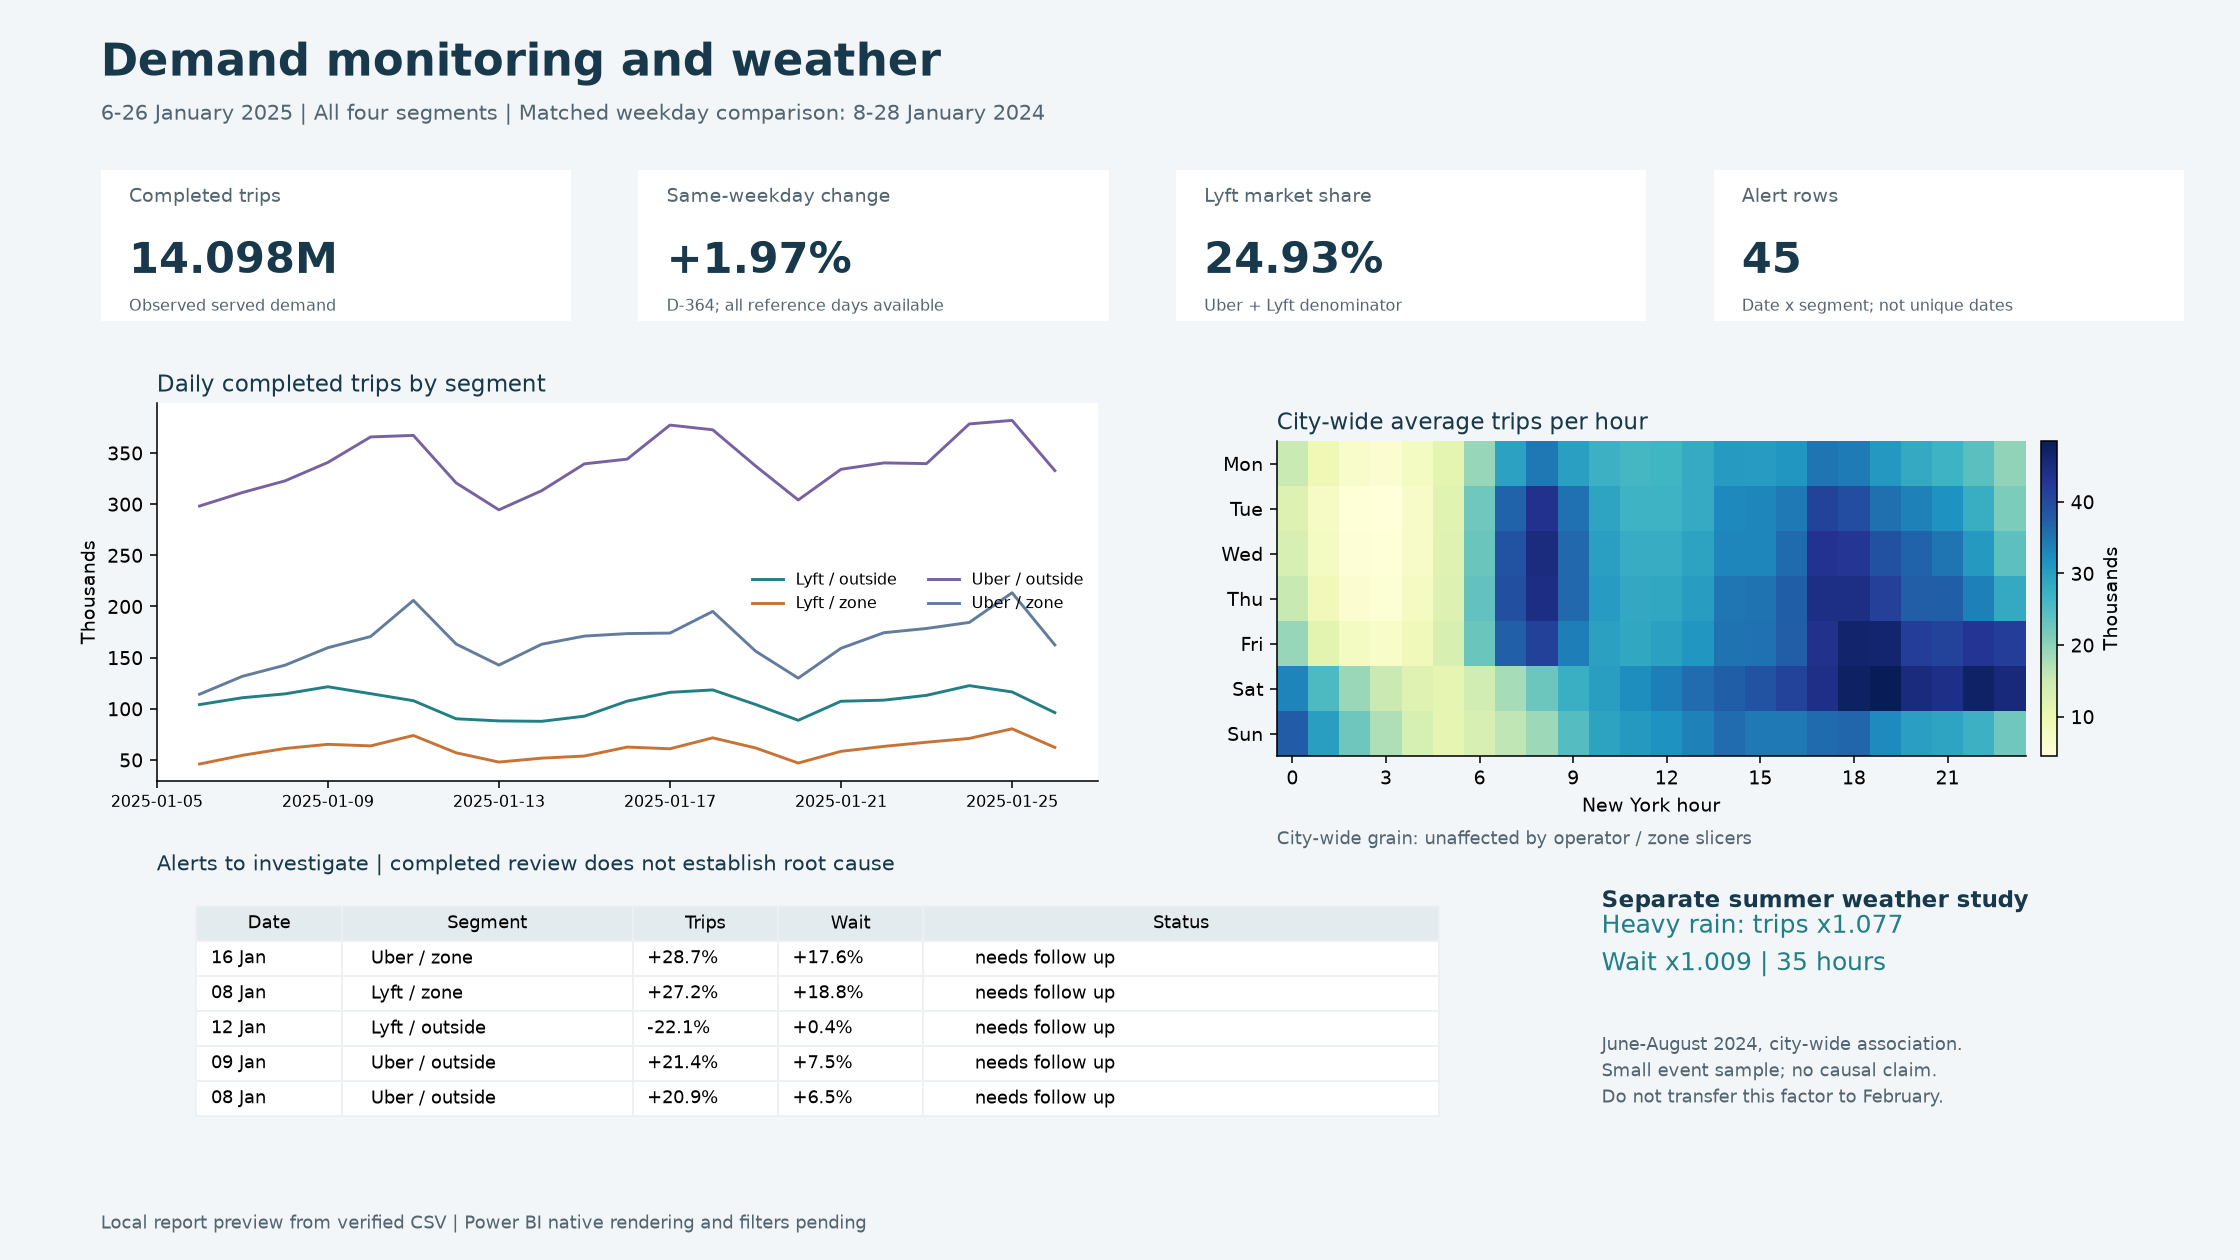

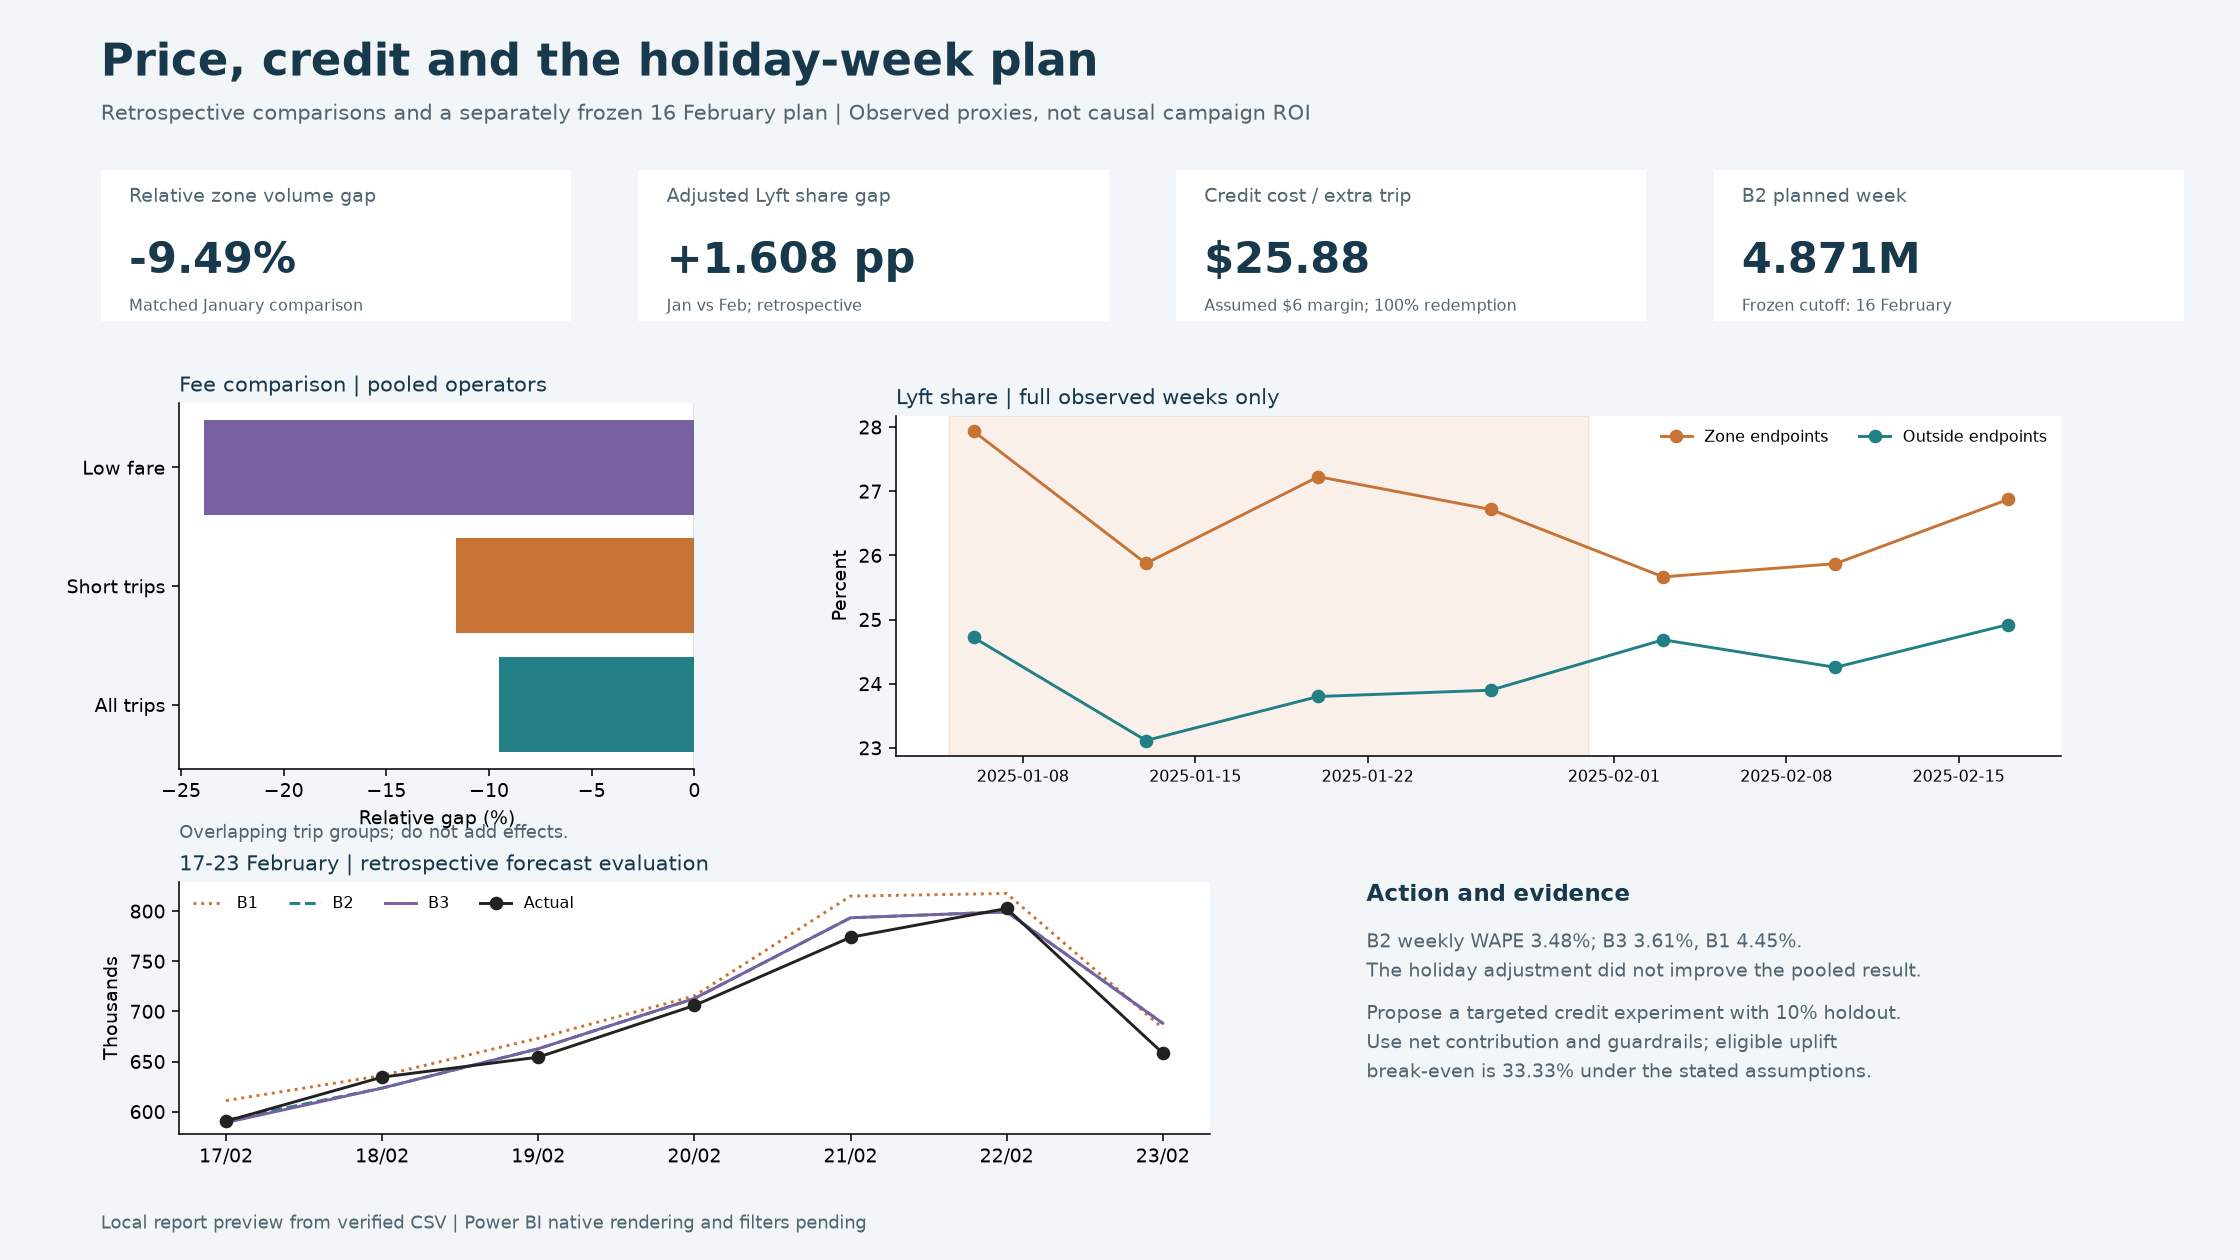

In [61]:
display(Image(filename=str(ROOT / "reports/demand_monitoring_preview.png")))
display(Image(filename=str(ROOT / "reports/price_credit_plan_preview.png")))

In [62]:
display(Markdown((ROOT / "docs/mobility_planning_memo.md").read_text()))

# January Review and Feb 17-23 Demand Plan

**Decision time: end of 16 February 2025, New York. Historical planning simulation.**

Plan **4,871,468 completed Uber + Lyft trips** for 17-23 February using the two-week same-weekday mean (B2). Treat the MLK adjustment as a holiday scenario, not a proven improvement.

## Evidence available at cutoff

In the matched January windows, zone-touching volume was 9.49% below its comparison-based counterfactual. This is an observational relative gap, not an identified causal fee effect. Outside-zone trips can be affected by spillovers and through-zone fees.
Lyft had 27.00% of completed Uber + Lyft zone trips in 6-26 January. Its $1.50 offer was future credit, not cash reimbursement. Redemption and campaign incrementality are unmeasured; the January-February share estimate is excluded because it uses data after this decision time.

## Plan and action

Use B2 as the provisional baseline, fixed before evaluation. The B3 holiday scenario totals 4,869,000 trips and changes only 17 February. Keep the segment forecasts visible; the four MLK responses differ.
Prepare pickup-time monitoring and rain/snow contingency actions. Summer rain coefficients are not February forecast multipliers. No future observed weather or test-week accuracy is used in this plan.
Design a targeted $1.50 future-credit experiment with 10% randomized holdout, at least 14 issuance days and redemption follow-up. Decide using measured incremental net contribution per assigned user and guardrails. With assumed $6 contribution and full redemption, break-even is 33.33% uplift on eligible baseline trips; a whole-base 10% threshold requires 30% baseline-trip coverage and a compatible denominator.

## What remains unknown

Completed trips exclude failed/cancelled requests. Driver supply, true margin, redemption, retention and causal incrementality are not observed. This simulation assumes trip records were available at cutoff; public TLC monthly releases are retrospective. B2/B3 scenarios are not prediction intervals.
